# BI10 Round 02 – Challenge 2: Customer Engagement Score

Notebook này trả lời **6 yêu cầu của Challenge 2** và chạy được độc lập từ đầu đến cuối (*Restart & Run all*).

| # | Yêu cầu đề bài | Mục trong notebook |
|---|---|---|
| 1 | Xác định các yếu tố phản ánh Customer Engagement | **§2** khung yếu tố → biến; **§4.1** chọn biến bằng dữ liệu (IV, trùng lặp, độ ổn định, dấu hệ số) |
| 2 | Phân tích hành vi theo Recency · Frequency · Interaction · Lead · Product | **§3** EDA đầy đủ cho từng biến: phân phối, ngoại lai, quan hệ với kết quả, tương quan, độ trôi theo thời gian |
| 3 | Xây Customer Engagement Score | **§4** hai scorecard WoE đơn điệu (khách đã vay / khách chưa từng vay), học trên **nhiều mốc thời gian**, cùng thang 0–100 |
| 4 | Phân khúc khách theo mức gắn kết | **§6** 4 mức gắn kết, ngưỡng lấy từ tỉ lệ chuyển đổi thực tế |
| 5 | Yếu tố thúc đẩy / làm giảm gắn kết | **§7** mô hình đa biến (odds ratio + khoảng tin cậy) và **SHAP** của mô hình gradient boosting đơn điệu |
| 6 | Kiểm chứng điểm với kết quả kinh doanh | **§5** holdout + **out-of-time** + độ ổn định + mô hình thách thức; **§8** nhiều kết quả kinh doanh, kể cả sau ngày chốt |

> Phạm vi: Challenge 2 chỉ đo **mức gắn kết**. Phân khúc kết hợp với Financial Health và Next Best Action thuộc Challenge 3, dùng file điểm xuất ra ở §9.

**Nguyên tắc**
- Mọi biến đo **trước** mốc chấm điểm (không nhìn trước tương lai).
- "Tương tác" chỉ tính **hành động do khách chủ động** (scoring, tự tạo lead, nộp hồ sơ, tự gọi vào), không tính các bước do công ty thực hiện.
- Điểm **giải thích được**: mỗi nhóm hành vi có số điểm rõ ràng, lấy từ dữ liệu.
- **Không dùng chung biến với Financial Health** (lịch sử trả nợ, quá hạn, thu nhập, DTI, cuộc gọi thu nợ).
- **Tương quan ≠ nhân quả**: các tác động ở §7 là liên hệ có điều kiện, cần A/B test trước khi triển khai.

## 0. Setup & nạp dữ liệu

In [1]:
import os
import gc
import sys
import time
import subprocess
import warnings
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

try:
    import lightgbm as lgb
except ImportError:   # preinstalled on Colab; install elsewhere if missing
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], check=True)
    import lightgbm as lgb

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ---- Paths: on Colab mount Drive; locally set BI10_ROOT or edit DEFAULT_ROOT ----
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DEFAULT_ROOT = "/content/drive/MyDrive/BI10_ROUND02_DATASET"
except ImportError:
    DEFAULT_ROOT = r"C:\BI10_ROUND02_DATASET"
ROOT = Path(os.environ.get("BI10_ROOT", DEFAULT_ROOT))
CLEAN_DIR = ROOT / "Clean_data"            # *_clean.xlsx delivered by the team
PQ_DIR = CLEAN_DIR / "parquet"             # parquet cache (built once from the xlsx)
OUT = ROOT / "output" / "challenge2"
FIG = OUT / "figures"
for p in (PQ_DIR, FIG):
    p.mkdir(parents=True, exist_ok=True)

# ---- Time design: 60-day outcome windows; learn on two dates, test on a later, unseen date ----
T0 = "2025-02-01"        # training date 1
TM = "2025-03-01"        # training date 2
T1 = "2025-04-01"        # out-of-time test date (never used for fitting)
SNAPSHOT = "2025-06-05"  # final scoring date (data ends 2025-06-04 -> exclusive bound)
TRAIN = [T0, TM]
HORIZON_DAYS = 60
END = SNAPSHOT
outcome_end = lambda d: min(pd.Timestamp(d) + pd.Timedelta(days=HORIZON_DAYS), pd.Timestamp(END)).strftime("%Y-%m-%d")
SEED = 42

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

BLUE, BLUE_L, ORANGE, GREY, RED, GREEN = "#2a78d6", "#86b6ef", "#eb6834", "#8a8984", "#d03b3b", "#0ca30c"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 8.5,
})
PCT = mtick.PercentFormatter(1, decimals=0)
PCT1 = mtick.PercentFormatter(1, decimals=1)

def save(fig, name):
    fig.tight_layout(rect=(0, 0, 1, 0.97) if fig._suptitle else None)
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def bar_labels(ax, values, fmt="{:.1%}", horizontal=False, size=7.5):
    for i, v in enumerate(values):
        if pd.isna(v):
            continue
        if horizontal:
            ax.text(v, i, " " + fmt.format(v), va="center", fontsize=size, color="#52514e")
        else:
            ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=size, color="#52514e")

In [2]:
# Clean_data is delivered as multi-sheet .xlsx (Excel caps a sheet at 1,048,576 rows).
# Read every sheet once with the fast calamine engine, stack them and cache as Parquet.
def fix_object_columns(df):
    """Excel sheets can mix ints/strings/None in one column -> make each object column one type."""
    for col in df.columns[df.dtypes == object]:
        s = df[col]
        num = pd.to_numeric(s, errors="coerce")
        if num.notna().sum() == s.notna().sum():
            df[col] = num
        else:
            df[col] = s.where(s.isna(), s.astype(str))
    return df

def xlsx_to_parquet(name):
    pq = PQ_DIR / f"{name}.parquet"
    if pq.exists():
        return
    t0 = time.time()
    sheets = pd.read_excel(CLEAN_DIR / f"{name}_clean.xlsx", sheet_name=None, engine="calamine")
    df = fix_object_columns(pd.concat(sheets.values(), ignore_index=True))
    df.to_parquet(pq, index=False)
    print(f"{name}: {len(sheets)} sheets, {len(df):,} rows, {time.time() - t0:.0f}s")

for name in ["CUSTOMER", "CONTRACT", "LEADS", "PAST_BEHAVIOR", "CALL"]:
    xlsx_to_parquet(name)

In [3]:
# Typed views on top of the team's Clean_data parquet. Every column is cast defensively, so the
# notebook works whether the parquet came out of Excel as typed columns or as text.
def create_views(con, pq_dir):
    p = lambda name: (pq_dir / f"{name}.parquet").as_posix()
    con.execute("""
        CREATE OR REPLACE MACRO num(x) AS TRY_CAST(CAST(x AS VARCHAR) AS DOUBLE);
        CREATE OR REPLACE MACRO flag(x) AS coalesce(num(x), 0) = 1;
        CREATE OR REPLACE MACRO ts(x) AS coalesce(
            TRY_CAST(CAST(x AS VARCHAR) AS TIMESTAMP),
            TIMESTAMP '1899-12-30' + to_seconds(CAST(num(x) * 86400 AS BIGINT)));   -- Excel serial date fallback
        CREATE OR REPLACE MACRO txt(x) AS NULLIF(NULLIF(trim(CAST(x AS VARCHAR)), ''), 'XNA');
    """)
    con.execute(f"""CREATE OR REPLACE VIEW customer AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client,
               coalesce(num(AVG_SESSION_PER_WEEK_2025), 0) AS app_sessions,
               flag(FLAG_GMA_USER) AS app_user
        FROM '{p("CUSTOMER")}'""")
    con.execute(f"""CREATE OR REPLACE VIEW contract AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client,
               coalesce(txt(PRODUCT_GROUP), 'UNKNOWN') AS product,
               txt(STATUS_GROUP) AS status_group,
               flag(IS_SIGNED) AS is_signed, flag(IS_REVOLVING) AS is_revolving,
               ts(APPLY_CONTRACT_TIME) AS t_apply,
               coalesce(ts(SIGN_CONTRACT_TIME), ts(APPLY_CONTRACT_TIME)) AS t_sign,
               num(PAYMENT_NUM) AS tenor,
               CASE WHEN num(AMT_CREDIT) > 0 THEN num(AMT_CREDIT) ELSE num(AMT_BILLING) END AS amount
        FROM '{p("CONTRACT")}'""")
    con.execute(f"""CREATE OR REPLACE VIEW leads AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client,
               ts(DTIME_CREATED) AS t_created,
               CASE WHEN year(ts(DATE_ACCEPTED)) < 2900 THEN ts(DATE_ACCEPTED) END AS t_accepted,  -- 3000-01-01 = sentinel
               CASE WHEN year(ts(DATE_ACCEPTED)) < 2900 THEN num(ACCEPT_LAG_HOURS) END AS accept_lag_h,
               txt(LEAD_OUTCOME) AS outcome, flag(IS_DEAL) AS is_deal,
               txt(LEAD_SOURCE) AS source, txt(LEAD_SOURCE) IN ('SOB', 'GMA', 'LANDING PAGE') AS is_self,
               txt(PRODUCT_GROUP) AS product
        FROM '{p("LEADS")}'""")
    con.execute(f"""CREATE OR REPLACE VIEW behavior AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client, ts(DTIME_EVENT) AS t_event,
               txt(CHANNEL) AS channel, txt(EVENT_TYPE) AS event_type, txt(PRODUCT_GROUP) AS product
        FROM '{p("PAST_BEHAVIOR")}'""")
    con.execute(f"""CREATE OR REPLACE VIEW call AS
        SELECT CAST(num(SKP_CLIENT) AS BIGINT) AS client, ts(TIME_OF_CALL_START) AS t_call,
               txt(CALL_TYPE) = 'Inbound' AS is_inbound, flag(IS_CONNECTED) AS is_connected,
               flag(IS_COLLECTION_CALL) AS is_collection, txt(RESPONSE_GROUP) AS response
        FROM '{p("CALL")}'
        WHERE NOT flag(FLAG_DUP_CALL_ID)""")

In [4]:
CALL_WINDOW_DAYS = 30   # CALL starts 2025-01-01 -> same short window at every as-of date keeps call features comparable

def build_features(con, as_of):
    """All candidate engagement variables measured strictly BEFORE `as_of` (no look-ahead)."""
    a = f"TIMESTAMP '{as_of}'"
    d12, d24 = f"{a} - INTERVAL 365 DAY", f"{a} - INTERVAL 730 DAY"
    d3, d1 = f"{a} - INTERVAL 90 DAY", f"{a} - INTERVAL 30 DAY"
    dc = f"{a} - INTERVAL {CALL_WINDOW_DAYS} DAY"
    days = lambda t: f"date_diff('day', {t}, {a})"
    sql = f"""
    WITH
    beh AS (
        SELECT client,
               {days("max(t_event) FILTER (WHERE event_type = 'SCORING')")} AS rec_scoring_days,
               count(*) FILTER (WHERE event_type = 'SCORING' AND t_event >= {d12}) AS n_scoring_12m,
               count(DISTINCT product) FILTER (WHERE event_type = 'SCORING' AND t_event >= {d12}) AS n_products_scored_12m,
               count(DISTINCT channel) FILTER (WHERE t_event >= {d12}) AS n_channels_12m,
               avg(CASE WHEN channel IN ('APP', 'WEB') THEN 1.0 ELSE 0 END) FILTER (WHERE t_event >= {d12}) AS self_service_share_12m,
               max(t_event) FILTER (WHERE event_type = 'SCORING') AS last_scoring
        FROM behavior WHERE t_event < {a} GROUP BY 1),
    lds AS (
        SELECT client,
               count(*) FILTER (WHERE t_created >= {d12}) AS n_leads_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND t_accepted IS NOT NULL AND t_accepted < {a}) AS n_leads_accepted_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND outcome = 'NOT_INTEREST') AS n_leads_not_interest_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND is_deal) AS n_lead_deals_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND is_self) AS n_self_leads_12m,
               count(*) FILTER (WHERE t_created >= {d12} AND NOT is_self) AS n_company_leads_12m,
               median(accept_lag_h) FILTER (WHERE t_created >= {d12} AND t_accepted < {a}) AS median_accept_lag_h_12m,
               {days('max(t_created)')} AS rec_lead_days,
               max(t_created) FILTER (WHERE is_self) AS last_self_lead
        FROM leads WHERE t_created < {a} GROUP BY 1),
    cl AS (
        SELECT client,
               count(*) FILTER (WHERE NOT is_inbound) AS n_sales_calls_30d,
               avg(is_connected::INT) FILTER (WHERE NOT is_inbound) AS call_answer_rate_30d,
               count(*) FILTER (WHERE is_inbound) AS n_inbound_calls_30d,
               count(*) FILTER (WHERE is_connected AND response = 'REFUSE') AS n_call_refuse_30d,
               count(*) FILTER (WHERE response = 'TERMINATION_REQUEST') AS n_termination_req_30d
        FROM call WHERE NOT is_collection AND t_call >= {dc} AND t_call < {a} GROUP BY 1),
    ct AS (   -- contracts known at as_of (applied before it)
        SELECT * REPLACE (is_signed AND t_sign < {a} AS is_signed),   -- a loan counts as booked only once signed before as_of
               t_sign + to_months(CAST(coalesce(tenor, 0) AS INT)) AS t_end
        FROM contract WHERE t_apply < {a}),
    apps AS (
        SELECT client,
               {days('max(t_sign) FILTER (WHERE is_signed)')} AS rec_booking_days,
               count(*) FILTER (WHERE is_signed AND t_apply >= {d24}) AS n_signed_24m,
               count(DISTINCT product) FILTER (WHERE is_signed AND product <> 'UNKNOWN') AS n_products_held,
               max(CASE WHEN is_signed AND is_revolving THEN 1 ELSE 0 END) AS has_revolving,
               count(*) FILTER (WHERE is_signed AND (is_revolving OR t_end >= {a})) AS n_running,
               count(*) FILTER (WHERE t_apply >= {d24}) AS n_apps_24m,
               avg(CASE WHEN status_group = 'CANCELLED' THEN 1.0 ELSE 0 END) FILTER (WHERE t_apply >= {d24}) AS cancel_rate_24m,
               avg(CASE WHEN status_group = 'REJECTED' THEN 1.0 ELSE 0 END) FILTER (WHERE t_apply >= {d24}) AS reject_rate_24m
        FROM ct GROUP BY 1),
    gaps AS (   -- median days between consecutive applications (application rhythm)
        SELECT client, median(gap) AS median_app_gap_days
        FROM (SELECT client, date_diff('day', lag(t_apply) OVER (PARTITION BY client ORDER BY t_apply), t_apply) AS gap FROM ct)
        WHERE gap IS NOT NULL GROUP BY 1),
    rep AS (   -- repeat rate: share of loans that ended before as_of and were followed by a new application
        SELECT e.client, avg(CASE WHEN EXISTS (SELECT 1 FROM ct n WHERE n.client = e.client AND n.t_apply > e.t_end) THEN 1.0 ELSE 0 END) AS repeat_rate
        FROM ct e WHERE e.is_signed AND NOT e.is_revolving AND e.tenor > 0 AND e.t_end < {a} GROUP BY 1),
    acts AS (     -- customer-initiated actions only: scoring, self-created leads, applications (not company steps)
        SELECT client, t_event AS t FROM behavior WHERE t_event >= {d12} AND t_event < {a}
        UNION ALL SELECT client, t_created FROM leads WHERE is_self AND t_created >= {d12} AND t_created < {a}
        UNION ALL SELECT client, t_apply FROM contract WHERE t_apply >= {d12} AND t_apply < {a}),
    months AS (
        SELECT client, count(DISTINCT date_trunc('month', t)) AS active_months_12m,
               avg(CASE WHEN t >= {d3} THEN 1.0 ELSE 0 END) AS recent_activity_share
        FROM acts GROUP BY 1),
    fun AS (      -- personal funnel: share of scoring events followed by an application within 30 days
        SELECT s.client, avg(CASE WHEN p.t_apply <= s.t_event + INTERVAL 30 DAY THEN 1.0 ELSE 0 END) AS scoring_to_app_rate_12m
        FROM (SELECT client, t_event FROM behavior WHERE event_type = 'SCORING' AND t_event >= {d12} AND t_event < {d1}) s
        ASOF LEFT JOIN (SELECT client, t_apply FROM contract WHERE t_apply < {a}) p
            ON s.client = p.client AND p.t_apply >= s.t_event
        GROUP BY 1)
    SELECT c.client, c.app_sessions, c.app_user,
           {days('greatest(b.last_scoring, l.last_self_lead)')} AS rec_touch_days,
           b.rec_scoring_days, a.rec_booking_days, l.rec_lead_days,
           coalesce(m.active_months_12m, 0) AS active_months_12m, m.recent_activity_share,
           coalesce(b.n_scoring_12m, 0) AS n_scoring_12m,
           coalesce(a.n_signed_24m, 0) AS n_signed_24m,
           coalesce(k.n_sales_calls_30d, 0) AS n_sales_calls_30d, k.call_answer_rate_30d,
           coalesce(k.n_inbound_calls_30d, 0) AS n_inbound_calls_30d,
           coalesce(k.n_call_refuse_30d, 0) AS n_call_refuse_30d,
           coalesce(k.n_termination_req_30d, 0) AS n_termination_req_30d,
           coalesce(b.n_channels_12m, 0) AS n_channels_12m, b.self_service_share_12m,
           coalesce(l.n_leads_12m, 0) AS n_leads_12m,
           l.n_leads_accepted_12m / nullif(l.n_leads_12m, 0) AS lead_accept_rate_12m,
           l.n_leads_not_interest_12m / nullif(l.n_leads_12m, 0) AS lead_not_interest_rate_12m,
           coalesce(l.n_lead_deals_12m, 0) AS n_lead_deals_12m,
           coalesce(l.n_self_leads_12m, 0) AS n_self_leads_12m,
           coalesce(l.n_company_leads_12m, 0) AS n_company_leads_12m,
           l.median_accept_lag_h_12m, f.scoring_to_app_rate_12m,
           coalesce(b.n_products_scored_12m, 0) AS n_products_scored_12m,
           coalesce(a.n_products_held, 0) AS n_products_held,
           coalesce(a.has_revolving, 0) AS has_revolving,
           coalesce(a.n_running, 0) AS n_running,
           r.repeat_rate,
           coalesce(a.n_apps_24m, 0) AS n_apps_24m, a.cancel_rate_24m, a.reject_rate_24m,
           g.median_app_gap_days
    FROM customer c
    LEFT JOIN beh b USING (client) LEFT JOIN lds l USING (client) LEFT JOIN cl k USING (client)
    LEFT JOIN apps a USING (client) LEFT JOIN gaps g USING (client) LEFT JOIN rep r USING (client)
    LEFT JOIN months m USING (client) LEFT JOIN fun f USING (client)
    ORDER BY c.client"""
    df = con.execute(sql).df()
    for col in df.columns:
        if col != "client":
            df[col] = pd.to_numeric(df[col], errors="coerce").astype("float64")
    return df


def build_outcomes(con, as_of, end):
    """Business outcomes in the window [as_of, end): conversion = new signed loan applied in the window or a lead deal."""
    a, e = f"TIMESTAMP '{as_of}'", f"TIMESTAMP '{end}'"
    return con.execute(f"""
    WITH k AS (SELECT client, count(*) AS new_apps, count(*) FILTER (WHERE is_signed) AS new_booked,
                      sum(amount) FILTER (WHERE is_signed) AS new_booked_amount
               FROM contract WHERE t_apply >= {a} AND t_apply < {e} GROUP BY 1),
         d AS (SELECT client, count(*) AS new_lead_deals FROM leads WHERE is_deal AND t_created >= {a} AND t_created < {e} GROUP BY 1)
    SELECT c.client,
           CASE WHEN coalesce(k.new_booked, 0) + coalesce(d.new_lead_deals, 0) > 0 THEN 1 ELSE 0 END AS converted,
           CASE WHEN coalesce(k.new_apps, 0) > 0 THEN 1 ELSE 0 END AS applied,
           coalesce(k.new_booked_amount, 0) AS new_booked_amount
    FROM customer c LEFT JOIN k USING (client) LEFT JOIN d USING (client) ORDER BY c.client""").df()

In [5]:
con = duckdb.connect()
create_views(con, PQ_DIR)
q = lambda sql: con.execute(sql).df()

coverage = q("""
SELECT 'customer' AS table_name, COUNT(*) AS n_rows, COUNT(DISTINCT client) AS n_clients, NULL AS first_date, NULL AS last_date FROM customer
UNION ALL SELECT 'contract (application)', COUNT(*), COUNT(DISTINCT client), MIN(t_apply)::DATE, MAX(t_apply)::DATE FROM contract
UNION ALL SELECT 'leads (created)', COUNT(*), COUNT(DISTINCT client), MIN(t_created)::DATE, MAX(t_created)::DATE FROM leads
UNION ALL SELECT 'behavior (scoring events)', COUNT(*), COUNT(DISTINCT client), MIN(t_event)::DATE, MAX(t_event)::DATE FROM behavior
UNION ALL SELECT 'call (dup CALL_ID removed)', COUNT(*), COUNT(DISTINCT client), MIN(t_call)::DATE, MAX(t_call)::DATE FROM call
""")
coverage

,table_name,n_rows,n_clients,first_date,last_date
0,customer,1000528,1000528,NaT,NaT
1,contract (application),4280377,1000528,2009-04-21,2025-06-04
2,leads (created),2104642,645344,2019-10-09,2025-06-04
3,behavior (scoring events),4412610,473086,2022-12-01,2025-06-03
4,call (dup CALL_ID removed),3975451,360321,2025-01-01,2026-08-31


---
## 1. EDA dữ liệu nguồn: hoạt động theo thời gian
Trước khi tạo biến, cần biết **mỗi bảng có dữ liệu từ khi nào** và **hoạt động dồn vào thời điểm nào**, vì điều này quyết định cách chọn mốc chấm điểm và cửa sổ đo.

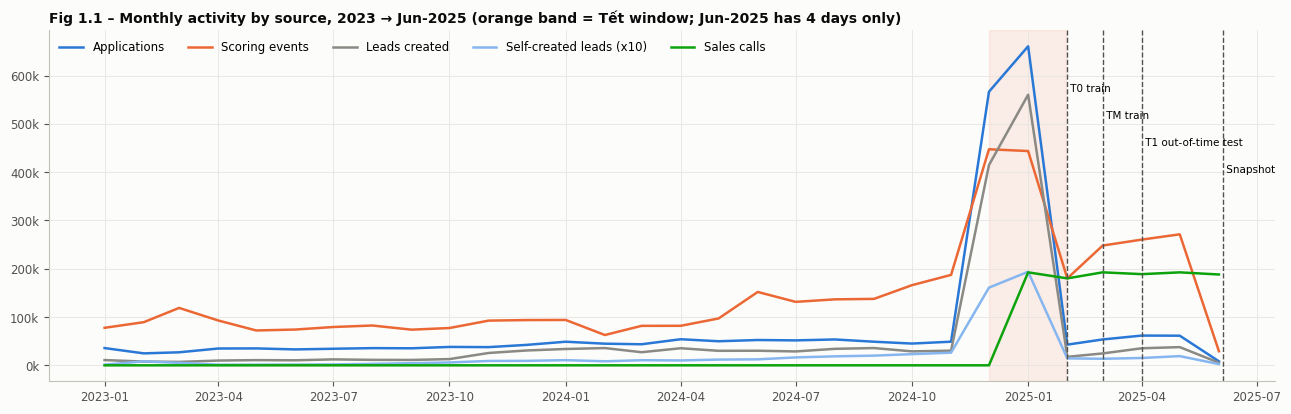

Customers with an application in Dec-2024/Jan-2025: 1,000,528 / 1,000,528 (100.0%)


In [6]:
monthly = q("""
WITH m AS (
    SELECT date_trunc('month', t_apply) AS month, 'Applications' AS series FROM contract
    UNION ALL SELECT date_trunc('month', t_event), 'Scoring events' FROM behavior WHERE event_type = 'SCORING'
    UNION ALL SELECT date_trunc('month', t_created), 'Leads created' FROM leads
    UNION ALL SELECT date_trunc('month', t_created), 'Self-created leads (x10)' FROM leads WHERE is_self
    UNION ALL SELECT date_trunc('month', t_call), 'Sales calls' FROM call WHERE NOT is_collection)
SELECT month, series, COUNT(*) AS n FROM m
WHERE month >= TIMESTAMP '2023-01-01' AND month < TIMESTAMP '2025-07-01' GROUP BY ALL ORDER BY month""")
mp = monthly.pivot(index="month", columns="series", values="n").fillna(0)
mp["Self-created leads (x10)"] *= 10

fig, ax = plt.subplots(figsize=(13, 4.2))
colors = {"Applications": BLUE, "Scoring events": ORANGE, "Leads created": GREY, "Self-created leads (x10)": BLUE_L, "Sales calls": GREEN}
for s, c in colors.items():
    ax.plot(mp.index, mp[s], color=c, linewidth=1.8, label=s)
ax.axvspan(pd.Timestamp("2024-12-01"), pd.Timestamp("2025-01-31"), color=ORANGE, alpha=0.10)
for k, (d, lab) in enumerate([(T0, "T0 train"), (TM, "TM train"), (T1, "T1 out-of-time test"), ("2025-06-04", "Snapshot")]):
    ax.axvline(pd.Timestamp(d), color="#52514e", linestyle="--", linewidth=1)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * (0.84 - 0.08 * k), f" {lab}", fontsize=7.5, va="top")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
ax.legend(loc="upper left", frameon=False, ncol=5)
ax.set_title("Fig 1.1 – Monthly activity by source, 2023 → Jun-2025 (orange band = Tết window; Jun-2025 has 4 days only)", loc="left")
save(fig, "1_1_monthly_activity")

cohort = q("""SELECT COUNT(DISTINCT client) AS n FROM contract
              WHERE t_apply >= TIMESTAMP '2024-12-01' AND t_apply < TIMESTAMP '2025-02-01'""")["n"][0]
n_cust = q("SELECT COUNT(*) AS n FROM customer")["n"][0]
print(f"Customers with an application in Dec-2024/Jan-2025: {cohort:,} / {n_cust:,} ({cohort / n_cust:.1%})")

> **💡 Insight (Fig 1.1):**
> - **100% trong 1.000.528 khách đều nộp hồ sơ trong 12/2024 – 01/2025.** Số hồ sơ tháng 01/2025 lên khoảng 660 nghìn, trong khi mức thường ngày chỉ khoảng 50 nghìn/tháng. Lead và scoring cũng tăng vọt cùng thời điểm.
> - **Lead do khách tự tạo rất ít:** chỉ khoảng 3,5% tổng số lead (đường xanh nhạt đã nhân 10 để nhìn thấy được).
> - Bảng **CALL chỉ bắt đầu từ 01/2025**; 74% cuộc gọi nằm *sau* ngày chốt (§3.3).
>
> **➡️ Ý nghĩa:** Tập khách là **một cohort mùa Tết**, nên mọi biến "gần đây" đều bị mùa vụ chi phối. Thiết kế được chọn theo đó:
> 1. Học trên **hai mốc sau Tết** (01/02 và 01/03) để điểm không khớp riêng với một thời điểm.
> 2. Kiểm chứng ở **mốc thứ ba chưa dùng** (01/04).
> 3. Loại các biến trôi quá mạnh theo thời gian (§3.6, §4.1).

---
## 2. Khung yếu tố gắn kết → biến dữ liệu (Yêu cầu 1)

### 2.1 Thiết kế thời gian
| Thành phần | Định nghĩa |
|---|---|
| **Kết quả kinh doanh** | **Chuyển đổi trong 60 ngày** sau mốc = có hồ sơ vay **nộp trong** cửa sổ và được ký, **hoặc** có lead Deal được tạo trong cửa sổ. Tính theo ngày nộp hồ sơ để hồ sơ Tết nộp cuối tháng 1 nhưng ký đầu tháng 2 **không** bị tính là "quay lại" |
| **Học trên nhiều mốc** | Hai mốc **T0 = 01/02/2025** và **TM = 01/03/2025** được **gộp lại** để chia nhóm, tính điểm và trọng số. Mỗi mốc có hành vi khác nhau (ngay sau Tết và một tháng sau), nên điểm không bị "khớp" với riêng một thời điểm |
| **Chống tự chấm tự khen** | 1 triệu khách chia ngẫu nhiên 50/50: **nửa calibration** để học, **nửa holdout** chỉ để kiểm chứng (cùng một khách luôn ở cùng một nửa) |
| **Out-of-time** | **T1 = 01/04/2025**: chưa từng dùng để học. Kiểm chứng trên **nửa holdout tại T1**, tức khách chưa thấy *và* thời điểm chưa thấy |
| **Chấm điểm cuối** | Ngày chốt 04/06/2025. Kiểm chứng thêm bằng cuộc gọi bán hàng **sau** ngày chốt |
| **Cuộc gọi** | Bảng CALL chỉ bắt đầu từ 01/2025, nên biến cuộc gọi dùng **cửa sổ 30 ngày** giống nhau ở mọi mốc |
| **Hai scorecard** | Khách **chưa từng được giải ngân** có mọi biến khoản vay bằng 0, nên có scorecard riêng chỉ dùng hành vi số, lead và hồ sơ. Hai scorecard được đưa về **cùng một thang 0–100** |

### 2.2 Từ khung yếu tố đến biến
Các yếu tố được nhóm theo **khung 5 nhóm** (giao dịch & sản phẩm · kênh số · phản hồi marketing/CSKH · hành trình hồ sơ · dấu hiệu rời bỏ) rồi gán vào **5 khía cạnh đề bài** + 1 khía cạnh bổ sung *Application journey*.

| Nhóm trong khung | Yếu tố | Có dữ liệu? | Biến | Khía cạnh | Vai trò |
|---|---|---|---|---|---|
| 1. Giao dịch & sản phẩm | Bao lâu chưa vay | ✅ | `rec_booking_days` | Recency | ứng viên |
| | Tần suất ký hợp đồng mới | ✅ | `n_signed_24m` | Frequency | ứng viên |
| | Số loại sản phẩm đã dùng (cross-sell) | ✅ | `n_products_held` | Product | ứng viên |
| | Thẻ / hạn mức quay vòng | 🟡 chỉ biết có thẻ, **không có** giao dịch thẻ, tỉ lệ dùng hạn mức | `has_revolving` | Product | ứng viên |
| | Tỷ lệ quay lại vay sau tất toán | 🟡 không có ngày tất toán thật → ước lượng bằng ngày ký + số kỳ | `repeat_rate` | Product | ứng viên |
| | Thâm niên quan hệ | ✅ | – | – | **không dùng**: đã có trong Financial Health |
| 2. Kênh số | Số phiên app | 🟡 chỉ có trung bình 2025 | `app_sessions` | – | **chỉ mô tả**: đo cả năm 2025, gồm thời gian *sau* mốc → rò rỉ kết quả |
| | Số kênh khách dùng | ✅ | `n_channels_12m` | Interaction | ứng viên |
| | Tự phục vụ qua app/web | ✅ | `self_service_share_12m` | Interaction | ứng viên |
| | **Phễu cá nhân**: scoring → nộp hồ sơ | ✅ | `scoring_to_app_rate_12m` | Interaction | ứng viên **(mới)** |
| | Tính năng app, phễu trong app | ❌ | – | – | không có dữ liệu |
| 3. Phản hồi marketing & CSKH | **Lead do khách tự tạo** (SOB / app / landing page) | ✅ | `n_self_leads_12m` | Lead | ứng viên (tách riêng) |
| | **Lead do công ty đẩy** (RA / SA / TLS / RTDM) | ✅ | `n_company_leads_12m` | Lead | ứng viên **(mới, tách riêng)** |
| | Lead: qua bước chấp nhận, Deal, "không quan tâm" | ✅ | `lead_accept_rate_12m`, `n_lead_deals_12m`, `lead_not_interest_rate_12m` | Lead | ứng viên |
| | **Tốc độ chấp nhận lead** | 🟡 có `ACCEPT_LAG_HOURS`, nhưng nhiều khả năng là bước nghiệp vụ (§3.3) | `median_accept_lag_h_12m` | Lead | ứng viên **(mới)** |
| | Telesales: từ chối, tự gọi vào | ✅ (từ 01/2025) | `n_call_refuse_30d`, `n_inbound_calls_30d` | Interaction | ứng viên |
| | Telesales: tỷ lệ nghe máy | ✅ (từ 01/2025) | `call_answer_rate_30d` | – | **chỉ mô tả**: tín hiệu đến từ việc *công ty chọn ai để gọi* (chứng minh ở §3.4b) |
| | Số cuộc gọi bán hàng nhận được | ✅ | `n_sales_calls_30d` | – | **chỉ mô tả**: do công ty quyết định |
| | Mở/click SMS, email, push; NPS/CSAT; khiếu nại | ❌ | – | – | không có dữ liệu |
| 4. Hành trình hồ sơ | Số lần nộp hồ sơ | ✅ | `n_apps_24m` | Application | ứng viên |
| | Tỷ lệ hồ sơ bị hủy giữa chừng | ✅ | `cancel_rate_24m` | Application | ứng viên (giả thuyết: hủy nhiều → kém gắn kết; dữ liệu sẽ kiểm tra) |
| | Khoảng cách giữa các lần xin vay | ✅ | `median_app_gap_days` | Application | ứng viên |
| | Tỷ lệ bị từ chối | ✅ | `reject_rate_24m` | – | **chỉ mô tả**: quyết định của công ty, thuộc về rủi ro (FH) |
| 5. Dấu hiệu rời bỏ | Không còn hợp đồng đang chạy | ✅ | `n_running` | Product | ứng viên |
| | Lâu không tương tác | ✅ | `rec_touch_days`, `rec_scoring_days` | Recency | ứng viên |
| | **Đang nguội đi / đang nóng lên** | ✅ | `recent_activity_share` (tỉ lệ hành động trong 3 tháng gần nhất / 12 tháng) | Frequency | ứng viên **(mới)** |
| | Từ chối ưu đãi nhiều lần | ✅ | `lead_not_interest_rate_12m`, `n_call_refuse_30d` | Lead / Interaction | ứng viên |
| | Yêu cầu chấm dứt hợp đồng | ✅ nhưng rất hiếm | `n_termination_req_30d` | – | **chỉ mô tả** (< 0,1% khách) |
| | Hủy đăng ký nhận tin; tất toán sớm | ❌ | – | – | không có dữ liệu |
| (khác) | Hoạt động đều đặn theo tháng | ✅ | `active_months_12m`, `n_scoring_12m` | Frequency | ứng viên |
| | Lead gần nhất | ✅ | `rec_lead_days` | – | **chỉ mô tả**: lead phần lớn do công ty tạo (RA/SA) |

> "Tương tác chủ động" (`rec_touch_days`, `active_months_12m`, `recent_activity_share`) chỉ gồm **scoring, lead khách tự tạo và nộp hồ sơ**. Ngày "chấp nhận lead" **không** được tính, vì 1,2 triệu lead "không quan tâm" vẫn có ngày chấp nhận (§3.3), tức đây là bước của công ty.
>
> Các biến *ứng viên* được **chọn bằng dữ liệu** ở §4.1, không chọn theo cảm tính.

In [7]:
INF = np.inf
LO = 1e-9
DIMS = {"R": "Recency", "F": "Frequency", "I": "Interaction behavior", "L": "Lead activity",
        "P": "Product interaction", "A": "Application journey"}
DIM_ORDER = list(DIMS.values())
REC_BINS = [(14, "≤14d"), (30, "15–30d"), (60, "31–60d"), (90, "61–90d"), (180, "91–180d"), (365, "181–365d"), (INF, ">1y")]
RATE_BINS = [(0, "0%"), (0.5 - LO, "1–49%"), (1 - LO, "50–99%"), (INF, "100%")]

def V(dim, desc, bins, direction, missing=None, role="candidate", reason=""):
    """direction: 'inc' = more is more engaged, 'dec' = more is less engaged, None = let the data decide (no monotone constraint)."""
    return dict(dim=DIMS[dim], desc=desc, bins=bins, direction=direction, missing=missing, role=role, reason=reason)

VARS = {
    # --- Recency
    "rec_touch_days": V("R", "Days since last customer action (scoring or self-created lead)", REC_BINS, "dec", "Never"),
    "rec_scoring_days": V("R", "Days since last scoring event", REC_BINS, "dec", "Never"),
    "rec_booking_days": V("R", "Days since last signed loan", [(30, "≤30d"), (60, "31–60d"), (90, "61–90d"), (180, "91–180d"),
                                                           (365, "181–365d"), (730, "1–2y"), (INF, ">2y")], "dec", "Never booked"),
    "rec_lead_days": V("R", "Days since last lead created", REC_BINS, None, "No lead", role="eda",
                       reason="leads are mostly created by the company (RA/SA), not by the customer"),
    # --- Frequency
    "active_months_12m": V("F", "Distinct months with a customer action (12m)", [(1, "1"), (2, "2"), (3, "3"), (5, "4–5"), (INF, "6+")], "inc"),
    "n_scoring_12m": V("F", "Scoring events (12m)", [(0, "0"), (2, "1–2"), (5, "3–5"), (10, "6–10"), (20, "11–20"), (INF, "21+")], "inc"),
    "n_signed_24m": V("F", "New signed loans (24m)", [(0, "0"), (1, "1"), (2, "2"), (3, "3"), (INF, "4+")], "inc"),
    "recent_activity_share": V("F", "Share of 12m customer actions done in the last 90 days (trend)",
                               [(0.25, "≤25%"), (0.5, "26–50%"), (0.75, "51–75%"), (1 - LO, "76–99%"), (INF, "100%")], None),
    # --- Interaction behaviour (calls + channels + personal funnel)
    "call_answer_rate_30d": V("I", "Answer rate of sales calls (30d)", [(0, "0%"), (0.5 - LO, "1–49%"), (INF, "≥50%")], "inc", "Not called",
                              role="eda", reason="selection bias: its signal comes from WHO the company calls, not from answering (§3.4b)"),
    "n_inbound_calls_30d": V("I", "Inbound (customer-initiated) calls (30d)", [(0, "0"), (INF, "1+")], "inc"),
    "n_call_refuse_30d": V("I", "Connected sales calls ending in refusal (30d)", [(0, "0"), (INF, "1+")], "dec"),
    "n_channels_12m": V("I", "Distinct scoring channels used (12m)", [(0, "0"), (1, "1"), (2, "2"), (3, "3"), (INF, "4+")], "inc"),
    "self_service_share_12m": V("I", "Share of scoring done in APP/WEB (12m)", RATE_BINS, None, "No scoring"),
    "scoring_to_app_rate_12m": V("I", "Personal funnel: share of scoring events followed by an application within 30 days", RATE_BINS, None, "No scoring"),
    "n_sales_calls_30d": V("I", "Sales calls received (30d)", [(0, "0"), (1, "1"), (2, "2"), (INF, "3+")], None, role="eda",
                           reason="who gets called is the company's decision, not customer behaviour"),
    "n_termination_req_30d": V("I", "Termination requests (30d)", [(0, "0"), (INF, "1+")], "dec", role="eda",
                               reason="< 0.1% of customers: too rare to score, kept as a churn flag"),
    # --- Lead activity
    "n_self_leads_12m": V("L", "Self-created leads: SOB / app / landing page (12m)", [(0, "0"), (INF, "1+")], "inc"),
    "n_company_leads_12m": V("L", "Company-pushed leads: RA / SA / TLS / RTDM (12m)", [(0, "0"), (1, "1"), (2, "2"), (4, "3–4"), (INF, "5+")], None),
    "lead_accept_rate_12m": V("L", "Share of leads that passed the accept step (12m)", RATE_BINS, "inc", "No lead"),
    "lead_not_interest_rate_12m": V("L", "Share of leads closed 'not interested' (12m)", RATE_BINS, "dec", "No lead"),
    "n_lead_deals_12m": V("L", "Lead deals (12m)", [(0, "0"), (INF, "1+")], None),
    "median_accept_lag_h_12m": V("L", "Median hours from lead creation to acceptance (12m)",
                                 [(0.1, "≤6 min"), (1, "6–60 min"), (6, "1–6h"), (24, "6–24h"), (INF, ">1 day")], None, "No accepted lead"),
    "n_leads_12m": V("L", "All leads (12m)", [(0, "0"), (1, "1"), (2, "2"), (4, "3–4"), (INF, "5+")], None, role="eda",
                     reason="split into self-created vs company-pushed leads"),
    # --- Product interaction
    "n_products_scored_12m": V("P", "Distinct product groups scored (12m)", [(0, "0"), (1, "1"), (2, "2"), (3, "3"), (INF, "4+")], "inc"),
    "n_products_held": V("P", "Distinct product groups ever booked (cross-sell)", [(0, "0"), (1, "1"), (2, "2"), (INF, "3+")], "inc"),
    "has_revolving": V("P", "Holds a revolving product (card / credit line)", [(0, "No"), (INF, "Yes")], None),
    "n_running": V("P", "Loans still running at as-of date", [(0, "0"), (1, "1"), (2, "2"), (INF, "3+")], None),
    "repeat_rate": V("P", "Share of ended loans followed by a new application", [(1 - LO, "<100%"), (INF, "100%")], "inc", "No ended loan"),
    # --- Application journey
    "n_apps_24m": V("A", "Applications (24m)", [(1, "1"), (2, "2"), (3, "3"), (5, "4–5"), (INF, "6+")], None),
    "cancel_rate_24m": V("A", "Share of applications cancelled (24m)", [(0, "0%"), (0.5 - LO, "1–49%"), (INF, "≥50%")], "dec"),
    "median_app_gap_days": V("A", "Median days between consecutive applications",
                             [(30, "≤30d"), (90, "31–90d"), (180, "91–180d"), (365, "181–365d"), (730, "1–2y"), (INF, ">2y")], None, "Single application"),
    "reject_rate_24m": V("A", "Share of applications rejected (24m)", RATE_BINS, None, role="eda",
                         reason="company credit decision -> belongs to Financial Health"),
    # --- Descriptor only
    "app_sessions": V("I", "App sessions per week, 2025 average", [(0, "0"), (0.5, "≤0.5"), (1, "0.5–1"), (INF, ">1")], None, role="eda",
                      reason="measured over 2025 including AFTER the as-of date -> leaks the outcome"),
}
# If the Financial Health notebook already uses one of these variables, list it here: it is then excluded from ENG
# (rule agreed by the team: no variable is shared between the two scores).
SHARED_WITH_FH = []
for v in SHARED_WITH_FH:
    VARS[v].update(role="eda", reason="already used in Financial Health")
BOOKED_VARS = ["rec_booking_days", "n_signed_24m", "n_products_held", "has_revolving", "n_running", "repeat_rate"]  # all 0 / missing for thin-file
CANDIDATES = [v for v, s in VARS.items() if s["role"] == "candidate"]
catalog = pd.DataFrame([{"variable": v, "dimension": s["dim"], "description": s["desc"], "expected_direction": s["direction"] or "data-driven",
                         "role": s["role"], "why_not_scored": s["reason"]} for v, s in VARS.items()])
print(f"{len(VARS)} variables: {len(CANDIDATES)} scoring candidates, {len(VARS) - len(CANDIDATES)} descriptors")
catalog

33 variables: 26 scoring candidates, 7 descriptors


,variable,dimension,description,expected_direction,role,why_not_scored
0,rec_touch_days,Recency,Days since last customer action (scoring or se...,dec,candidate,
1,rec_scoring_days,Recency,Days since last scoring event,dec,candidate,
2,rec_booking_days,Recency,Days since last signed loan,dec,candidate,
3,rec_lead_days,Recency,Days since last lead created,data-driven,eda,leads are mostly created by the company (RA/SA...
4,active_months_12m,Frequency,Distinct months with a customer action (12m),inc,candidate,
5,n_scoring_12m,Frequency,Scoring events (12m),inc,candidate,
6,n_signed_24m,Frequency,New signed loans (24m),inc,candidate,
7,recent_activity_share,Frequency,Share of 12m customer actions done in the last...,data-driven,candidate,
8,call_answer_rate_30d,Interaction behavior,Answer rate of sales calls (30d),inc,eda,selection bias: its signal comes from WHO the ...
9,n_inbound_calls_30d,Interaction behavior,Inbound (customer-initiated) calls (30d),inc,candidate,


In [8]:
t0 = time.time()
DATES = [T0, TM, T1, SNAPSHOT]
F = {d: build_features(con, d) for d in DATES}
Y = {d: build_outcomes(con, d, outcome_end(d)) for d in [T0, TM, T1]}
for d in Y:
    assert (F[d]["client"].values == Y[d]["client"].values).all()
F0, F1, FS = F[T0], F[T1], F[SNAPSHOT]
y = {d: Y[d]["converted"].values for d in Y}
y0, y1 = y[T0], y[T1]
THIN = {d: (F[d]["n_products_held"].values == 0) for d in DATES}   # never booked a loan before d

rng = np.random.default_rng(SEED)
is_cal = rng.random(len(F0)) < 0.5                      # same customers in the same half at every date
CAL, HOLD = np.where(is_cal)[0], np.where(~is_cal)[0]
print(f"features at {len(DATES)} dates built in {time.time() - t0:.0f}s | calibration {len(CAL):,} | holdout {len(HOLD):,}")
print(pd.DataFrame({d: {"outcome window": f"{d} → {outcome_end(d)}", "conversion": f"{y[d].mean():.2%}",
                        "thin-file customers": f"{THIN[d].mean():.1%}", "conversion thin-file": f"{y[d][THIN[d]].mean():.2%}"}
                    for d in Y}).T)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

features at 4 dates built in 42s | calibration 500,462 | holdout 500,066
                     outcome window conversion thin-file customers conversion thin-file
2025-02-01  2025-02-01 → 2025-04-02      4.50%               18.8%                1.25%
2025-03-01  2025-03-01 → 2025-04-30      5.67%               18.6%                1.28%
2025-04-01  2025-04-01 → 2025-05-31      6.49%               18.5%                1.52%


---
## 3. EDA các biến hành vi (Yêu cầu 2)
EDA đi theo 6 bước: **(3.1)** thống kê mô tả → **(3.2)** phân phối → **(3.3)** ngoại lai & chất lượng dữ liệu → **(3.4)** quan hệ với kết quả kinh doanh → **(3.5)** tương quan giữa các biến → **(3.6)** độ trôi theo thời gian.
Các bước dùng mốc **T0 = 01/02/2025** và kết quả chuyển đổi 60 ngày sau đó.

### 3.1 Thống kê mô tả (tại T0 và tại ngày chốt)

In [9]:
def describe(Fd, label):
    rows = []
    for v, s in VARS.items():
        x = Fd[v]
        rows.append({"variable": v, "dimension": s["dim"], "role": s["role"], "as_of": label,
                     "coverage": x.notna().mean(), "share_zero": (x == 0).mean(), "mean": x.mean(),
                     "p25": x.quantile(.25), "median": x.median(), "p75": x.quantile(.75), "p90": x.quantile(.90),
                     "p99": x.quantile(.99), "max": x.max(), "skew": x.skew()})
    return pd.DataFrame(rows)

eda_tbl = pd.concat([describe(F0, "T0"), describe(FS, "Snapshot")], ignore_index=True)
eda_tbl.to_csv(OUT / "eda_variable_summary.csv", index=False)
eda_tbl[eda_tbl["as_of"] == "T0"].drop(columns="as_of").set_index("variable")

,dimension,role,coverage,share_zero,mean,p25,median,p75,p90,p99,max,skew
variable,,,,,,,,,,,,
rec_touch_days,Recency,candidate,0.4347,0.0000,126.6567,21.0000,46.0000,125.0000,432.0000,758.0000,"1,499.0000",2.1121
rec_scoring_days,Recency,candidate,0.4234,0.0000,128.1237,22.0000,46.0000,131.0000,438.0000,755.0000,793.0000,1.9629
rec_booking_days,Recency,candidate,0.8123,0.0000,222.4996,18.0000,37.0000,58.0000,570.0000,"3,163.0000","5,732.0000",4.0846
rec_lead_days,Recency,eda,0.6303,0.0000,148.1180,16.0000,38.0000,62.0000,432.0000,"1,438.0000","1,941.0000",2.9533
active_months_12m,Frequency,candidate,1.0000,0.0000,1.8037,1.0000,1.0000,2.0000,3.0000,7.0000,12.0000,2.4887
n_scoring_12m,Frequency,candidate,1.0000,0.6313,2.1214,0.0000,0.0000,3.0000,6.0000,22.0000,"1,076.0000",17.2598
n_signed_24m,Frequency,candidate,1.0000,0.2596,1.3872,0.0000,1.0000,2.0000,3.0000,5.0000,15.0000,1.1591
recent_activity_share,Frequency,candidate,1.0000,0.0000,0.8125,0.5455,1.0000,1.0000,1.0000,1.0000,1.0000,-1.0701
call_answer_rate_30d,Interaction behavior,eda,0.1536,0.1364,0.0926,0.0000,0.0000,0.0000,0.5000,1.0000,1.0000,2.8039


> **💡 Insight (bảng 3.1, tại T0):**
> - **Độ phủ thấp ở các kênh tương tác:**
>   - **56% khách chưa từng có hành động chủ động** (scoring hoặc tự tạo lead) trước T0.
>   - 63% không scoring trong 12 tháng; 85% không được gọi trong 30 ngày; 93% không dùng app.
> - **Dữ liệu hợp đồng phủ gần đủ:** 81% khách đã từng ký hợp đồng; 19% là thin-file (chưa từng được giải ngân).
> - **Lệch rất mạnh:** `n_scoring_12m` có p99 = 22 nhưng max = 1.076; `n_apps_24m` có p99 = 8 nhưng max = 1.511.
> - `recent_activity_share` có trung vị = 100%: phần lớn khách chỉ hoạt động trong 3 tháng quanh Tết.
>
> **➡️ Ý nghĩa:**
> - Giá trị *thiếu* có nghĩa kinh doanh ("chưa từng làm"), nên được giữ thành **một nhóm riêng** chứ không điền bằng 0.
> - Phân phối lệch và có ngoại lai, nên điểm phải tính theo **nhóm (bin)**.
> - 19% khách thin-file có mọi biến khoản vay bằng 0, nên cần **scorecard riêng** (§4).

### 3.2 Phân phối từng biến (tại T0)
Biến đếm/ngày được cắt ở p99 để nhìn rõ phần thân; tiêu đề ghi % thiếu (khách không có hoạt động tương ứng) và % bằng 0.

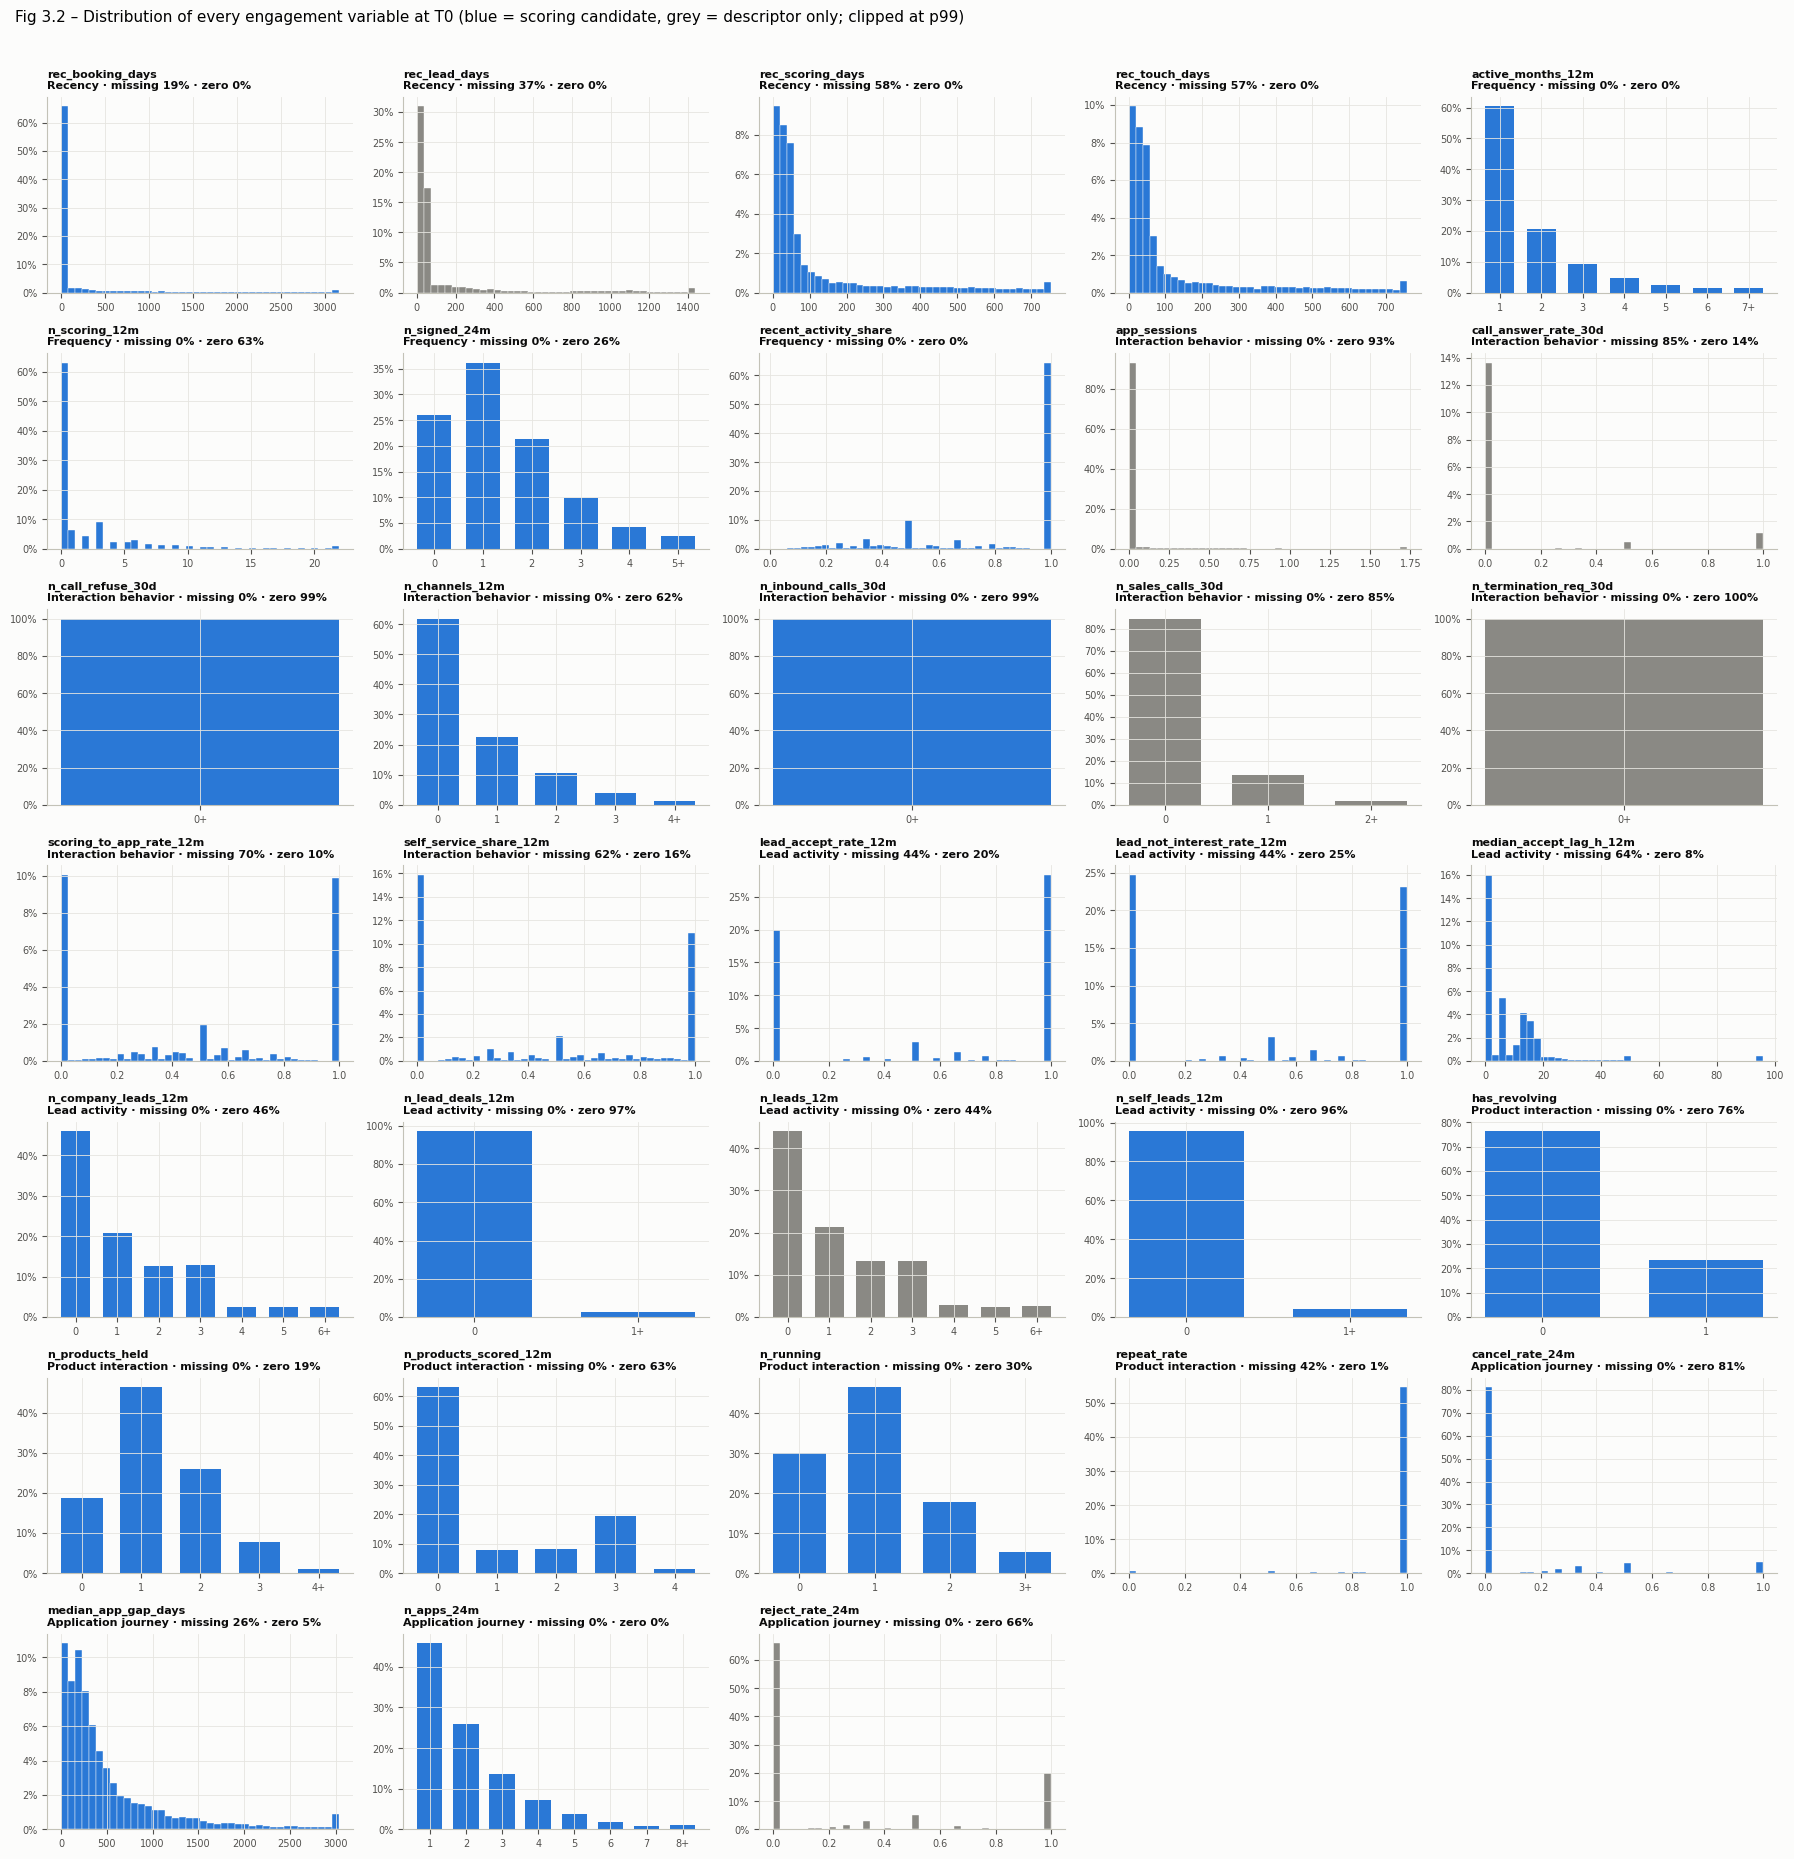

In [10]:
order = sorted(VARS, key=lambda v: (DIM_ORDER.index(VARS[v]["dim"]), v))
ncol = 5
nrow = int(np.ceil(len(order) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 2.7 * nrow))
for ax, v in zip(axes.flat, order):
    x = F0[v].dropna()
    cap = x.quantile(0.99)
    xs = x.clip(upper=cap)
    color = BLUE if VARS[v]["role"] == "candidate" else GREY
    if xs.nunique() <= 12 and (xs % 1 == 0).all():
        vc = (xs.value_counts() / len(F0)).sort_index()
        ax.bar(range(len(vc)), vc.values, color=color, width=0.7)
        ax.set_xticks(range(len(vc)), [f"{k:g}" + ("+" if k == cap and x.max() > cap else "") for k in vc.index])
    else:
        ax.hist(xs, bins=40, color=color, edgecolor="#fcfcfb", linewidth=0.3, weights=np.ones(len(xs)) / len(F0))
    ax.yaxis.set_major_formatter(PCT)
    ax.set_title(f"{v}\n{VARS[v]['dim']} · missing {F0[v].isna().mean():.0%} · zero {(F0[v] == 0).mean():.0%}", loc="left", fontsize=8)
    ax.tick_params(labelsize=7)
for ax in list(axes.flat)[len(order):]:
    ax.axis("off")
fig.suptitle("Fig 3.2 – Distribution of every engagement variable at T0 (blue = scoring candidate, grey = descriptor only; clipped at p99)",
             x=0.01, ha="left", fontsize=11)
save(fig, "3_2_distributions")

> **💡 Insight (Fig 3.2):**
> - Hầu hết biến đếm **dồn ở 0** rồi có đuôi dài.
> - Các biến tỉ lệ (lead, tự phục vụ, phễu cá nhân) có **hai đỉnh ở 0% và 100%**, vì đa số khách chỉ có 1–2 sự kiện.
> - `n_products_scored_12m` có đỉnh ở **3**: một lần scoring kiểm tra cùng lúc BNPL, CL và CC.
> - `median_accept_lag_h_12m` dồn ở **gần 0 giờ và khoảng 6–24 giờ**, đúng theo nguồn lead (xem §3.3).
>
> **➡️ Ý nghĩa:** Nhóm cho biến tỉ lệ được đặt là 0% / 1–49% / 50–99% / 100% / không có, để tách hai đỉnh và giữ riêng nhóm "không có sự kiện".

### 3.3 Ngoại lai & chất lượng dữ liệu

In [11]:
dq = []
for v in ["n_scoring_12m", "n_apps_24m", "n_company_leads_12m", "n_sales_calls_30d", "n_running", "active_months_12m"]:
    x = F0[v]
    p999 = x.quantile(0.999)
    dq.append({"variable": v, "p99": x.quantile(0.99), "p99.9": p999, "max": x.max(),
               "customers_above_p99.9": int((x > p999).sum()), "max / p99.9": x.max() / p999 if p999 else np.nan})
dq = pd.DataFrame(dq)
lead_q = q("""SELECT AVG(CASE WHEN t_accepted IS NOT NULL THEN 1.0 ELSE 0 END) FILTER (WHERE outcome = 'NOT_INTEREST') AS ni_with_accept,
                     COUNT(*) FILTER (WHERE outcome = 'NOT_INTEREST' AND t_accepted IS NOT NULL) AS ni_with_accept_n,
                     AVG(CASE WHEN is_self THEN 1.0 ELSE 0 END) AS self_share FROM leads""")
lag_by_src = q("""SELECT source, COUNT(*) AS leads_accepted, MEDIAN(accept_lag_h) AS median_lag_h
                  FROM leads WHERE t_accepted IS NOT NULL GROUP BY 1 ORDER BY median_lag_h""")
checks = pd.DataFrame([
    ("booking recency < 0 (signed after as-of: leakage)", int((F0["rec_booking_days"] < 0).sum())),
    ("repeat_rate outside [0, 1]", int(((F0["repeat_rate"] < 0) | (F0["repeat_rate"] > 1)).sum())),
    ("customers without any application in 24m", int((F0["n_apps_24m"] == 0).sum())),
    ("'not interested' leads that still have an accept date", int(lead_q["ni_with_accept_n"][0])),
    ("share of leads created by the customer (SOB / app / landing page)", lead_q["self_share"][0]),
    ("share of sales calls before snapshot (rest is after 04/06/2025)",
     q(f"SELECT AVG(CASE WHEN t_call < TIMESTAMP '{SNAPSHOT}' THEN 1.0 ELSE 0 END) AS v FROM call")["v"][0]),
], columns=["check", "value"])
display(dq)
display(checks)
lag_by_src

,variable,p99,p99.9,max,customers_above_p99.9,max / p99.9
0,n_scoring_12m,22.0000,68.0000,"1,076.0000",978,15.8235
1,n_apps_24m,8.0000,14.0000,"1,511.0000",826,107.9286
2,n_company_leads_12m,6.0000,9.0000,26.0000,562,2.8889
3,n_sales_calls_30d,2.0000,4.0000,16.0000,636,4.0000
4,n_running,3.0000,5.0000,19.0000,366,3.8000
5,active_months_12m,7.0000,10.0000,12.0000,721,1.2000


,check,value
0,booking recency < 0 (signed after as-of: leakage),0.0000
1,"repeat_rate outside [0, 1]",0.0000
2,customers without any application in 24m,0.0000
3,'not interested' leads that still have an acce...,"1,215,649.0000"
4,share of leads created by the customer (SOB / ...,0.0349
5,share of sales calls before snapshot (rest is ...,0.2555


,source,leads_accepted,median_lag_h
0,GMA,21973,0.0600
1,TLS,37375,0.0700
2,SOB,18254,0.1100
3,LANDING PAGE,8020,1.0200
4,SA,654781,1.1900
5,RA,781237,6.4700
6,RTDM,4230,149.4450


> **💡 Insight (bảng 3.3):**
> - **Ngoại lai:** 978 khách có số lần scoring trên p99,9 (max 1.076); có khách nộp 1.511 hồ sơ. Nhiều khả năng là bot, tài khoản test hoặc lỗi ghi nhận.
> - **Không có rò rỉ thời gian:** 0 khách có ngày ký *sau* mốc tính.
> - **Phát hiện quan trọng về lead:**
>   - **1.215.649 lead "không quan tâm" vẫn có ngày chấp nhận.** Như vậy "chấp nhận lead" là **bước nghiệp vụ** (lead được nhận vào xử lý), không phải khách đồng ý.
>   - Thời gian chấp nhận phụ thuộc mạnh vào **nguồn lead**: GMA/TLS khoảng 4 phút, RA 6,5 giờ, RTDM 149 giờ.
>
> **➡️ Ý nghĩa:**
> - Ngoại lai được chặn bởi nhóm cao nhất ("21+", "6+"), không cần xóa.
> - "Tương tác chủ động" **không tính ngày chấp nhận lead**. `median_accept_lag_h_12m` vẫn được thử nhưng cần đọc là *tốc độ xử lý theo nguồn lead* nhiều hơn là tốc độ phản hồi của khách.
> - Dữ liệu cuộc gọi sau ngày chốt chỉ dùng để kiểm chứng (§8).

### 3.4 Quan hệ của từng biến với kết quả kinh doanh (nửa calibration, T0)
Mỗi ô là **tỉ lệ chuyển đổi trong 60 ngày** theo nhóm của biến; đường ngang là trung bình. Đây là bước đầu tiên để thấy biến nào phân biệt được khách quay lại, theo chiều nào, và có đơn điệu hay không.

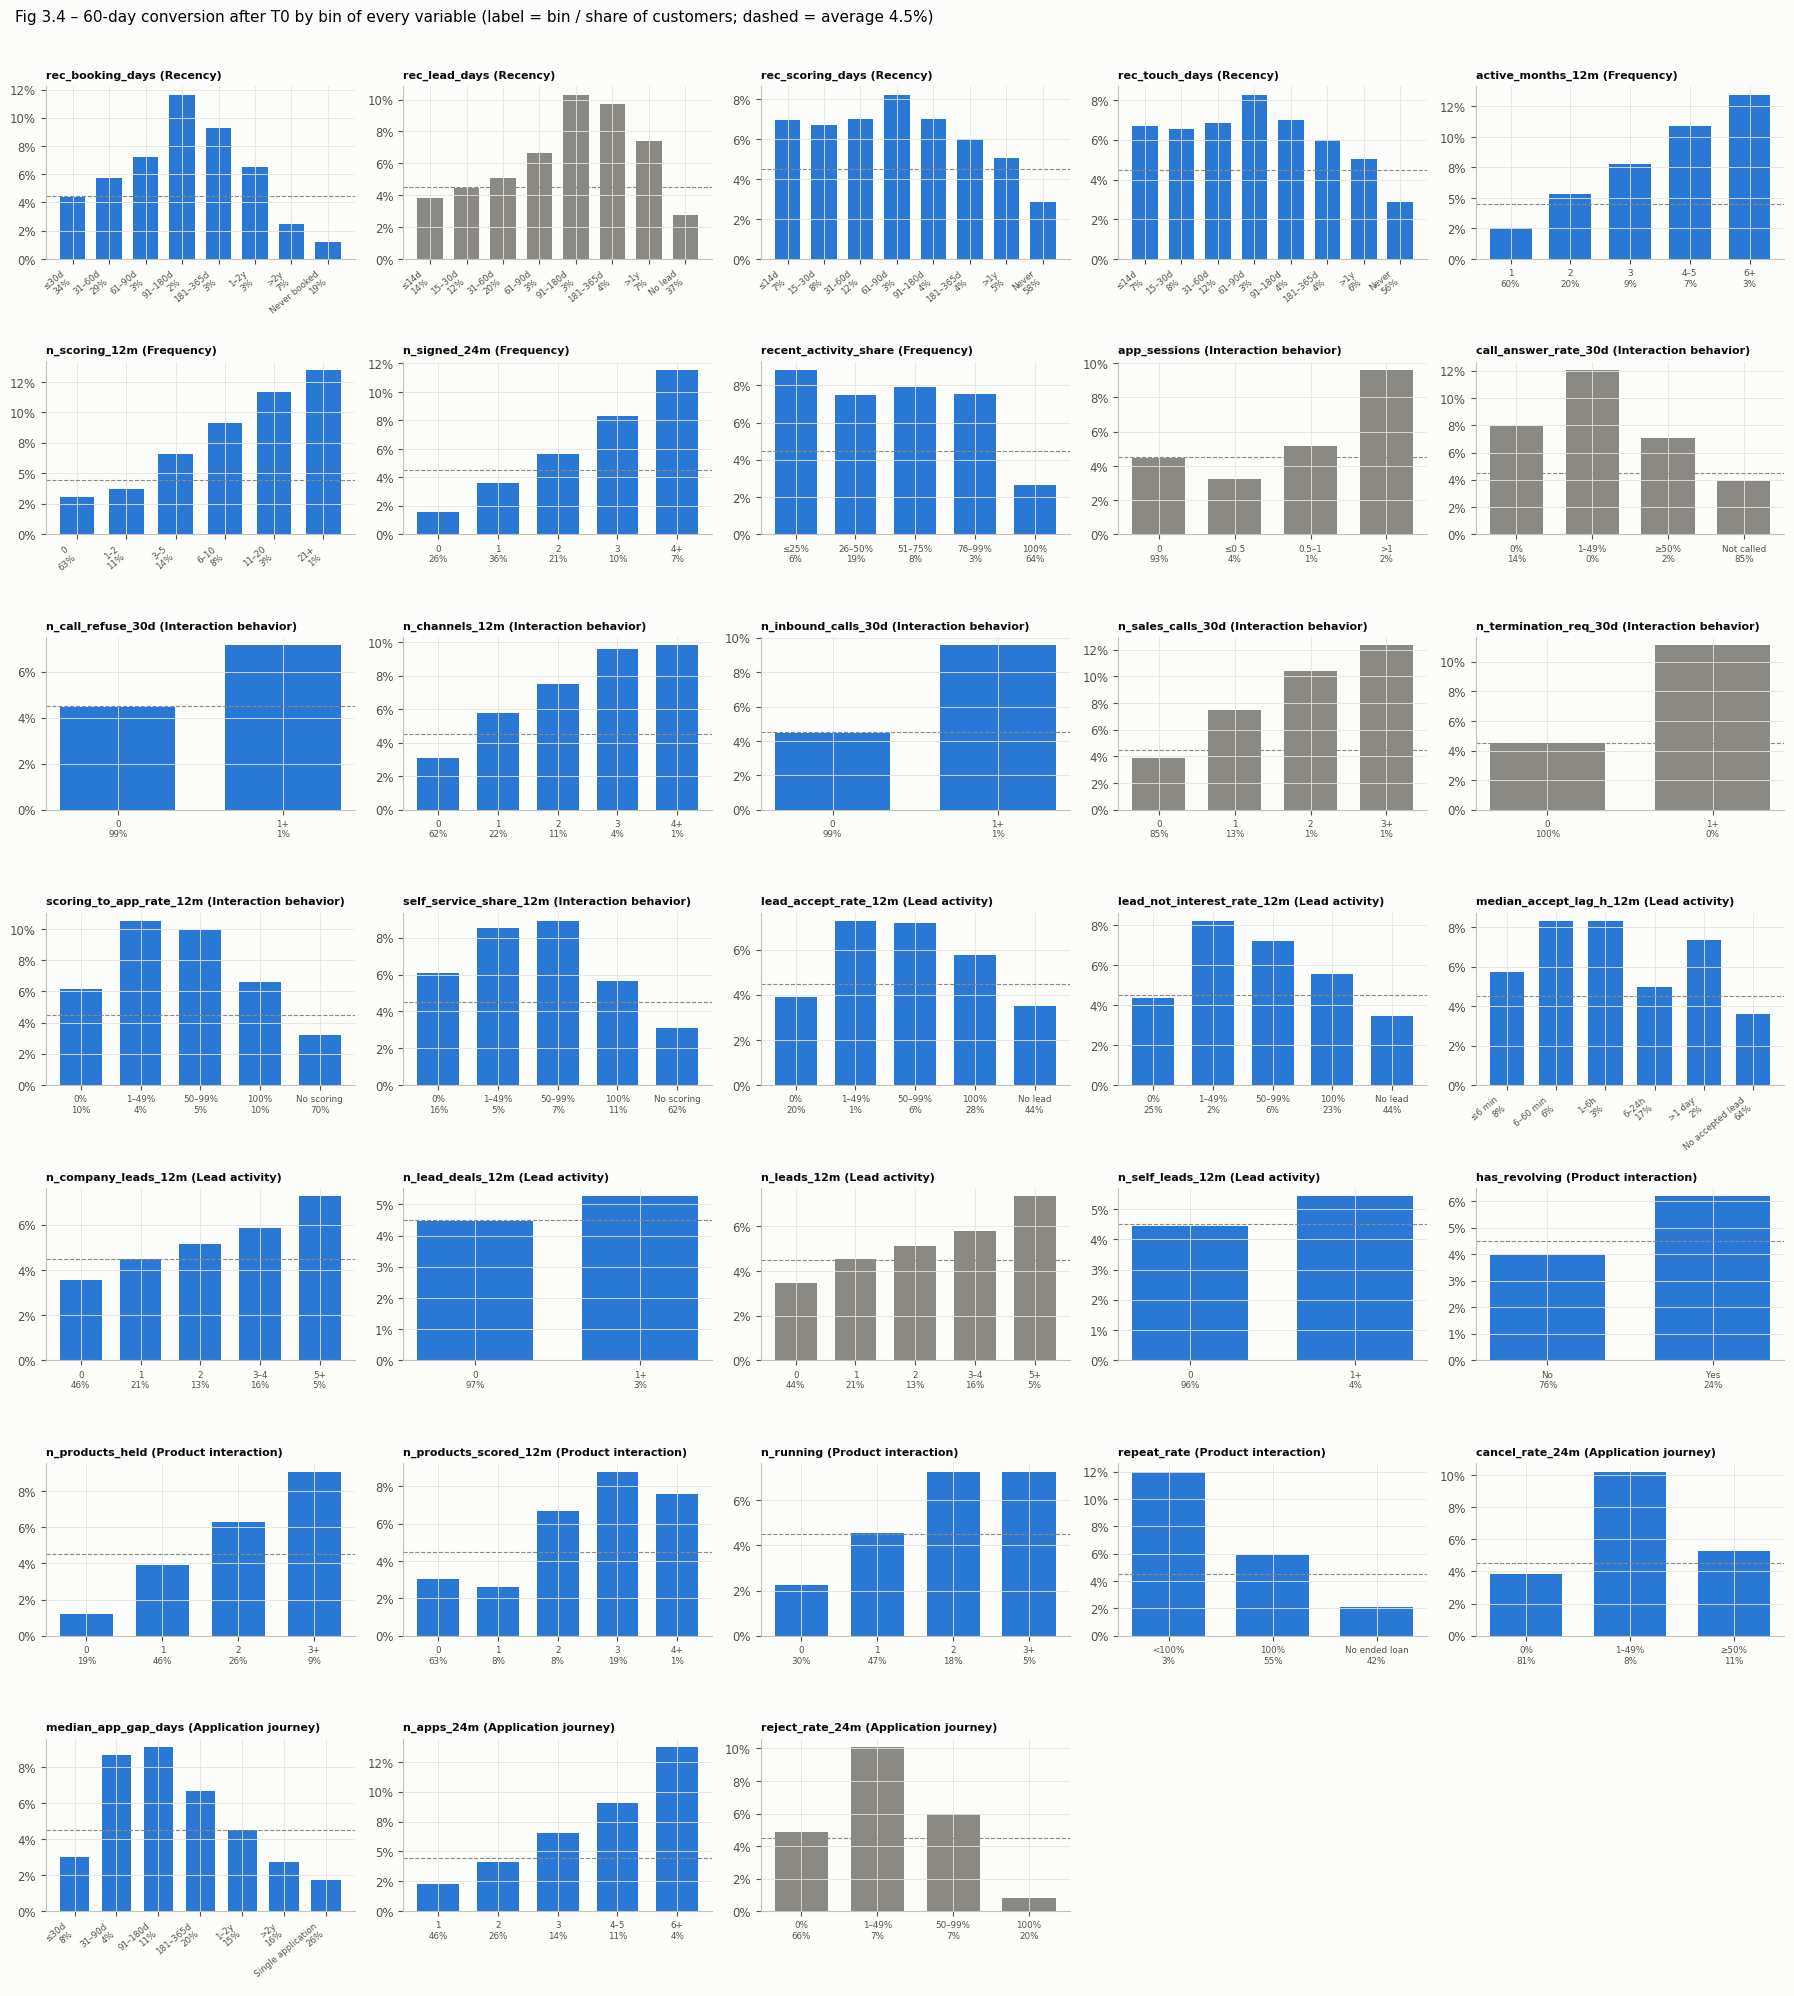

In [12]:
def assign_bins(x, spec):
    """Right-inclusive bins from spec['bins'] = [(upper, label), ...]; NaN -> spec['missing']."""
    uppers = np.array([u for u, _ in spec["bins"]], dtype=float)
    labels = [l for _, l in spec["bins"]]
    cats = labels + ([spec["missing"]] if spec["missing"] else [])
    vals = np.asarray(x, dtype=float)
    idx = np.searchsorted(uppers, np.nan_to_num(vals, nan=0.0), side="left").clip(0, len(labels) - 1)
    out = np.array(labels, dtype=object)[idx]
    if spec["missing"]:
        out[np.isnan(vals)] = spec["missing"]
    return pd.Categorical(out, categories=cats, ordered=True)

B = {d: pd.DataFrame({v: assign_bins(F[d][v], VARS[v]) for v in VARS}) for d in DATES}
B0, B1, BS = B[T0], B[T1], B[SNAPSHOT]
base_cal = y0[CAL].mean()

fig, axes = plt.subplots(nrow, ncol, figsize=(18, 2.9 * nrow))
for ax, v in zip(axes.flat, order):
    g = pd.DataFrame({"b": B0[v].iloc[CAL].values, "y": y0[CAL]}).groupby("b", observed=False)["y"].agg(["mean", "size"])
    color = BLUE if VARS[v]["role"] == "candidate" else GREY
    ax.bar(range(len(g)), g["mean"], color=color, width=0.7)
    ax.axhline(base_cal, color=GREY, linestyle="--", linewidth=0.8)
    ax.set_xticks(range(len(g)), [f"{c}\n{n / len(CAL):.0%}" for c, n in zip(g.index, g["size"])], fontsize=6.3,
                  rotation=40 if len(g) > 5 else 0, ha="right" if len(g) > 5 else "center")
    ax.yaxis.set_major_formatter(PCT)
    ax.set_title(f"{v} ({VARS[v]['dim']})", loc="left", fontsize=8)
for ax in list(axes.flat)[len(order):]:
    ax.axis("off")
fig.suptitle(f"Fig 3.4 – 60-day conversion after T0 by bin of every variable (label = bin / share of customers; dashed = average {base_cal:.1%})",
             x=0.01, ha="left", fontsize=11)
save(fig, "3_4_bivariate")

In [13]:
# Converted vs not converted: mean of each variable and standardised difference (Cohen's d)
rows = []
for v in order:
    x = F0[v].iloc[CAL]
    yc = y0[CAL]
    a, b = x[yc == 1], x[yc == 0]
    sd = np.sqrt((a.var() + b.var()) / 2)
    rows.append({"variable": v, "dimension": VARS[v]["dim"], "mean_not_converted": b.mean(), "mean_converted": a.mean(),
                 "ratio": a.mean() / b.mean() if b.mean() else np.nan, "cohens_d": (a.mean() - b.mean()) / sd if sd else 0.0,
                 "coverage": x.notna().mean()})
cmp_tbl = pd.DataFrame(rows).sort_values("cohens_d", key=np.abs, ascending=False)
cmp_tbl.to_csv(OUT / "eda_converted_vs_not.csv", index=False)
cmp_tbl.set_index("variable")

,dimension,mean_not_converted,mean_converted,ratio,cohens_d,coverage
variable,,,,,,
n_signed_24m,Frequency,1.3505,2.1705,1.6072,0.6031,1.0000
active_months_12m,Frequency,1.7634,2.6830,1.5215,0.5647,1.0000
recent_activity_share,Frequency,0.8195,0.6634,0.8095,-0.5373,1.0000
n_apps_24m,Application journey,2.0958,3.1552,1.5055,0.5216,1.0000
n_products_held,Product interaction,1.2416,1.6981,1.3676,0.5159,1.0000
n_products_scored_12m,Product interaction,0.8496,1.5195,1.7884,0.5014,1.0000
n_channels_12m,Interaction behavior,0.5843,0.9980,1.7081,0.4147,1.0000
n_running,Product interaction,0.9789,1.3350,1.3637,0.4022,1.0000
reject_rate_24m,Application journey,0.2648,0.1343,0.5070,-0.3860,1.0000


#### 3.4b Kiểm tra thiên lệch chọn mẫu của biến cuộc gọi
Khách *được gọi* là do công ty chọn (thường là khách có triển vọng). Nếu tín hiệu của biến cuộc gọi chỉ đến từ việc được gọi, thì nó đo hành vi của telesales chứ không phải mức gắn kết của khách.

In [14]:
call_status = pd.Series(np.select(
    [F0["n_inbound_calls_30d"] > 0, F0["n_sales_calls_30d"] == 0, F0["call_answer_rate_30d"] == 0],
    ["Made inbound call", "Not called", "Called, never answered"], default="Called, answered ≥1"))
call_tbl = (pd.DataFrame({"status": call_status.values[CAL], "y": y0[CAL]}).groupby("status")["y"].agg(customers="size", conversion="mean")
            .reindex(["Not called", "Called, never answered", "Called, answered ≥1", "Made inbound call"]))
call_tbl["share"] = call_tbl["customers"] / call_tbl["customers"].sum()
call_tbl["lift_vs_avg"] = call_tbl["conversion"] / base_cal
call_tbl

,customers,conversion,share,lift_vs_avg
status,,,,
Not called,422486,0.0386,0.8442,0.8586
"Called, never answered",67180,0.0795,0.1342,1.7704
"Called, answered ≥1",8284,0.0729,0.0166,1.6227
Made inbound call,2512,0.0955,0.0050,2.1263


> **💡 Insight (Fig 3.4, bảng so sánh, bảng 3.4b):** chuyển đổi 60 ngày trung bình là 4,5%.
> - **Phân biệt mạnh nhất (Cohen's d ≈ 0,5–0,6):** số hợp đồng 24 tháng, số tháng hoạt động, số hồ sơ, số sản phẩm đã dùng, số sản phẩm đã scoring.
> - **Xu hướng hoạt động (mới) có tín hiệu mạnh nhưng ngược chiều trực giác** (d = −0,54): khách có *toàn bộ* hoạt động dồn vào 3 tháng gần nhất lại ít quay lại nhất. Đó là khách chỉ đến vì đợt Tết.
> - **Recency không đơn điệu:** khách vay trong 30 ngày gần nhất chuyển đổi thấp hơn khách vay 3–6 tháng trước. Khách vừa vay xong tạm thời chưa cần vay tiếp.
> - **Phễu cá nhân và tốc độ chấp nhận lead (mới):** chênh lệch trung bình rất nhỏ (|d| < 0,05), nhưng không đơn điệu. Nhóm ở giữa (một phần scoring dẫn tới hồ sơ) cao hơn hai đầu.
> - **Biến cuộc gọi bị thiên lệch chọn mẫu (bảng 3.4b):**
>   - Khách *được gọi nhưng không nghe* chuyển đổi **8,0%**, khách *nghe máy* chỉ **7,3%**, khách không được gọi 3,9%.
>   - Chênh lệch đến từ việc **telesales chọn khách triển vọng**, không phải từ việc nghe máy.
>   - Chỉ hành động *tự gọi vào* là tín hiệu của khách (9,6%, ×2,1), nhưng chỉ 0,5% khách có.
>
> **➡️ Ý nghĩa:**
> 1. Tỉ lệ nghe máy **không được đưa vào điểm**.
> 2. Recency **phải bị ràng buộc đơn điệu**.
> 3. Các biến không đơn điệu (phễu, tốc độ lead, xu hướng) được để dữ liệu tự quyết định chiều.

### 3.5 Tương quan giữa các biến (Spearman, nửa calibration)
Biến tương quan cao đo **cùng một hành vi**; nếu đưa cả hai vào điểm thì hành vi đó bị tính hai lần. Bước chọn biến ở §4.1 sẽ loại bớt.

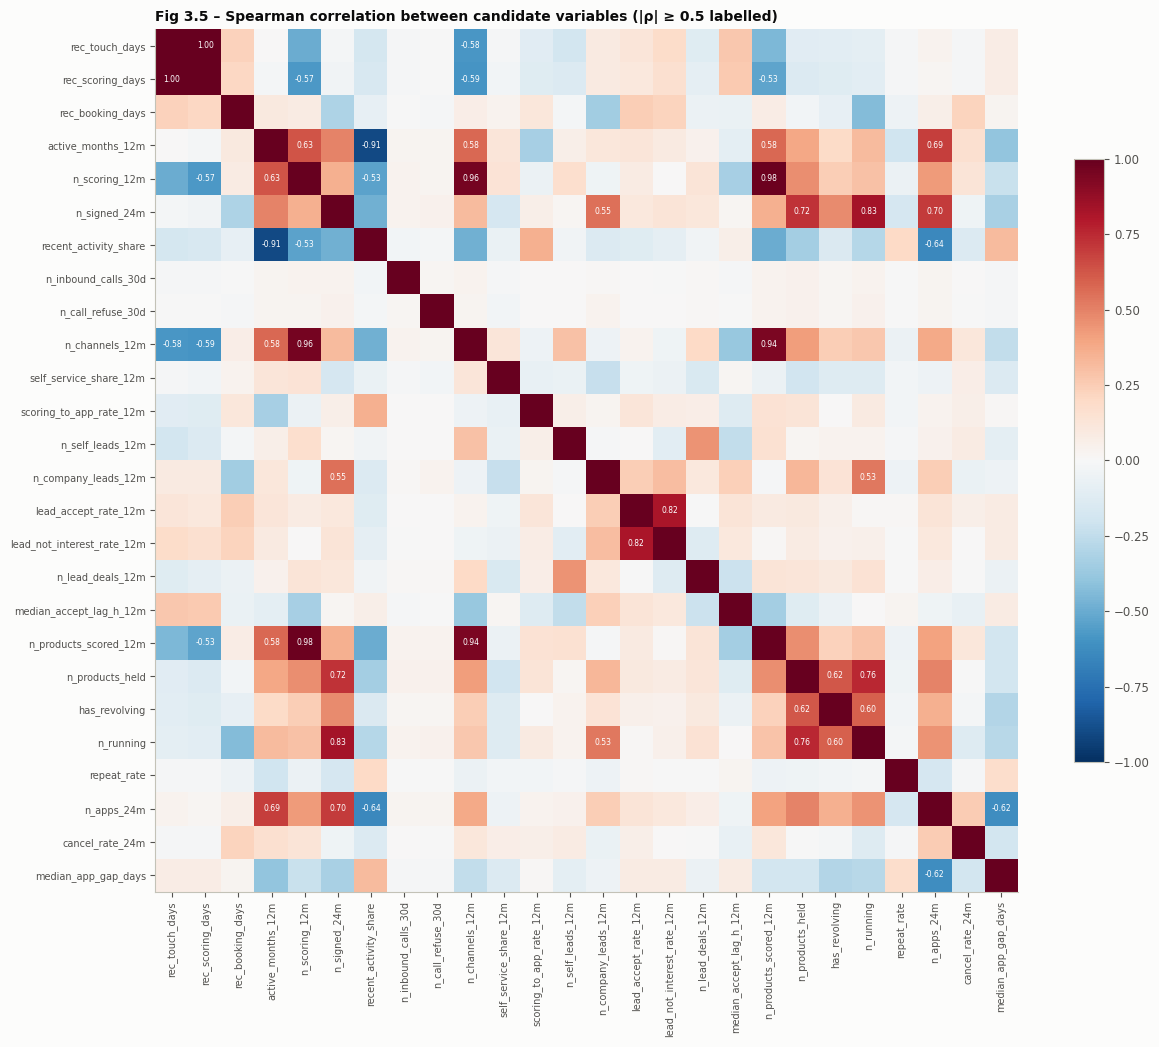

,var_1,var_2,rho
0,rec_touch_days,rec_scoring_days,0.9951
107,n_scoring_12m,n_products_scored_12m,0.9786
98,n_scoring_12m,n_channels_12m,0.9570
197,n_channels_12m,n_products_scored_12m,0.9391
74,active_months_12m,recent_activity_share,-0.9056
130,n_signed_24m,n_running,0.8342
259,lead_accept_rate_12m,lead_not_interest_rate_12m,0.8196
305,n_products_held,n_running,0.7554
128,n_signed_24m,n_products_held,0.7250
132,n_signed_24m,n_apps_24m,0.6966


In [15]:
sample = F0.iloc[CAL].sample(200_000, random_state=SEED)
corr = sample[CANDIDATES].rank().corr()   # Spearman = Pearson on ranks (NaN pairs dropped)
fig, ax = plt.subplots(figsize=(13, 10.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CANDIDATES)), CANDIDATES, rotation=90, fontsize=7)
ax.set_yticks(range(len(CANDIDATES)), CANDIDATES, fontsize=7)
for i in range(len(CANDIDATES)):
    for j in range(len(CANDIDATES)):
        if i != j and abs(corr.iat[i, j]) >= 0.5:
            ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=5.5, color="white")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title("Fig 3.5 – Spearman correlation between candidate variables (|ρ| ≥ 0.5 labelled)", loc="left")
save(fig, "3_5_correlation")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().rename("rho").reset_index()
         .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index).head(12)

> **💡 Insight (Fig 3.5):** Có bốn cụm biến gần như trùng nhau:
> 1. **Hoạt động scoring:** `n_scoring_12m`, `n_products_scored_12m`, `n_channels_12m` có ρ = 0,94–0,98; `rec_touch_days` và `rec_scoring_days` có ρ = 0,995.
> 2. **Nhịp hoạt động:** `active_months_12m` và `recent_activity_share` có ρ = −0,91. Khách hoạt động nhiều tháng thì tự nhiên có tỉ lệ "3 tháng gần nhất" thấp.
> 3. **Danh mục hợp đồng:** `n_signed_24m`, `n_running`, `n_products_held` có ρ = 0,73–0,83.
> 4. **Hai mặt của lead:** `lead_accept_rate_12m` và `lead_not_interest_rate_12m` có ρ = 0,82.
>
> **➡️ Ý nghĩa:** Nếu cộng cả cụm vào điểm thì một hành vi bị tính 2–3 lần. Bước chọn biến (§4.1) chỉ giữ **biến mạnh nhất trong mỗi cụm**.

### 3.6 Độ trôi theo thời gian: cùng một khách, đo ở T0, T1 và ngày chốt
Bảng điểm được học ở các mốc đầu năm nhưng dùng ở ngày chốt. Nếu phân phối của biến thay đổi mạnh giữa hai mốc, **ý nghĩa của từng nhóm cũng thay đổi**.
Đo bằng **PSI** (Population Stability Index): < 0,1 ổn định · 0,1–0,25 cần theo dõi · > 0,25 trôi mạnh.

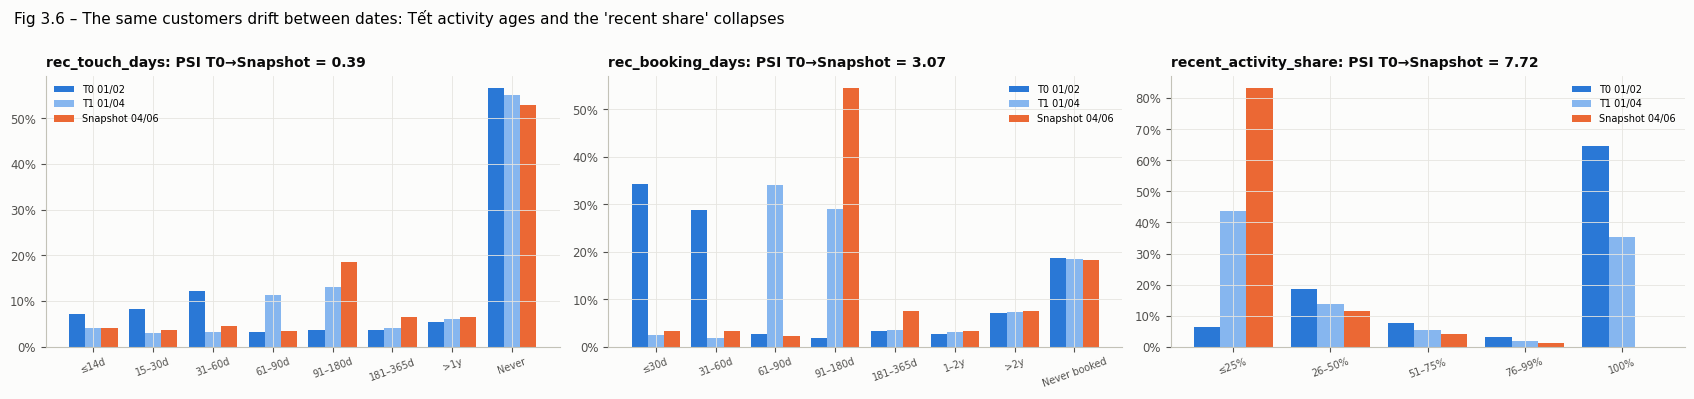

,dimension,PSI T0→T1,PSI T0→Snapshot
variable,,,
recent_activity_share,Frequency,0.9349,7.7217
rec_booking_days,Recency,3.0786,3.0664
rec_touch_days,Recency,0.4191,0.3904
rec_scoring_days,Recency,0.3837,0.3547
repeat_rate,Product interaction,0.0278,0.3279
scoring_to_app_rate_12m,Interaction behavior,0.0336,0.0410
n_running,Product interaction,0.0000,0.0332
median_app_gap_days,Application journey,0.0056,0.0203
active_months_12m,Frequency,0.0022,0.0113


In [16]:
def psi(expected, actual, eps=1e-4):
    e = pd.Series(expected).value_counts(normalize=True)
    a = pd.Series(actual).value_counts(normalize=True).reindex(e.index, fill_value=0)
    e, a = e.clip(lower=eps), a.clip(lower=eps)
    return float(((a - e) * np.log(a / e)).sum())

drift = pd.DataFrame([{"variable": v, "dimension": VARS[v]["dim"], "PSI T0→T1": psi(B0[v], B1[v]), "PSI T0→Snapshot": psi(B0[v], BS[v])}
                      for v in CANDIDATES]).sort_values("PSI T0→Snapshot", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, v in zip(axes, ["rec_touch_days", "rec_booking_days", "recent_activity_share"]):
    shares = pd.DataFrame({lab: Bd[v].value_counts(normalize=True).sort_index() for lab, Bd in [("T0 01/02", B0), ("T1 01/04", B1), ("Snapshot 04/06", BS)]})
    x = np.arange(len(shares)); w = 0.27
    for k, (lab, c) in enumerate(zip(shares.columns, [BLUE, BLUE_L, ORANGE])):
        ax.bar(x + (k - 1) * w, shares[lab], w, color=c, label=lab)
    ax.set_xticks(x, shares.index, fontsize=7, rotation=20)
    ax.yaxis.set_major_formatter(PCT)
    ax.set_title(f"{v}: PSI T0→Snapshot = {psi(B0[v], BS[v]):.2f}", loc="left")
    ax.legend(frameon=False, fontsize=7)
fig.suptitle("Fig 3.6 – The same customers drift between dates: Tết activity ages and the 'recent share' collapses", x=0.01, ha="left", fontsize=11)
save(fig, "3_6_drift")
drift.set_index("variable")

> **💡 Insight (Fig 3.6, bảng PSI):**
> - **Ba biến trôi rất mạnh giữa T0 và ngày chốt:**
>   - **`recent_activity_share`: PSI 7,7.** Tại T0 phần lớn khách có 100% hoạt động trong 3 tháng gần nhất (vì Tết); tại ngày chốt gần như không ai như vậy.
>   - **`rec_booking_days`: PSI 3,1**, và **`rec_touch_days`: PSI 0,39.** Cùng một khoản vay Tết "già" dần từ ≤60 ngày lên 120–180 ngày.
> - Các biến đếm và danh mục **rất ổn định** (PSI < 0,05). Ngoại lệ là `repeat_rate` (0,33).
>
> **➡️ Ý nghĩa:** Một biến có tín hiệu mạnh ở T0 nhưng trôi mạnh sẽ **chấm sai khi đem dùng ở ngày chốt**. Vì vậy §4.1 thêm **bộ lọc ổn định**: PSI của *điểm* biến (sau khi chia nhóm và làm đơn điệu) giữa T0 và ngày chốt phải ≤ 0,25.
>
> PSI của *điểm* có thể thấp hơn PSI của *nhóm thô*. Ví dụ, ràng buộc đơn điệu gộp mọi khoản vay trong 2 năm về cùng một mức điểm, nên `rec_booking_days` vẫn đạt yêu cầu.

---
## 4. Xây Customer Engagement Score (Yêu cầu 1 & 3)

### Phương pháp
1. **Chia nhóm** từng biến theo ngưỡng dễ hiểu (§3.4). Nhóm nhỏ hơn 0,5% khách được gộp với nhóm bên cạnh.
2. **Ràng buộc đơn điệu** (isotonic regression) cho các biến có chiều kinh doanh rõ ràng: ví dụ *càng lâu không tương tác thì điểm Recency không được cao hơn*.
3. **WoE** (Weight of Evidence) của nhóm = log-odds chuyển đổi của nhóm − log-odds trung bình. **IV** (Information Value) đo sức phân biệt của cả biến.
4. **Chọn biến** theo 5 bước:
   - IV ≥ 0,02.
   - Chiều giả thuyết phải được dữ liệu ủng hộ.
   - **Ổn định theo thời gian**: PSI của điểm biến giữa T0 và ngày chốt ≤ 0,25.
   - Không trùng thông tin: |tương quan WoE| ≤ 0,7, giữ biến có IV cao hơn.
   - Hệ số logistic phải > 0 khi đã có các biến khác.
5. **Học trên hai mốc gộp lại** (T0 và TM, nửa calibration).
6. **Hai scorecard**: *khách đã từng vay* dùng mọi biến ứng viên; *khách chưa từng vay* (thin-file) không dùng 6 biến khoản vay vì chúng luôn bằng 0.
7. **Cùng một thang 0–100**: điểm = A + B × log-odds dự báo, với A và B chọn sao cho p1 của log-odds = 0 và p99 = 100 trên dữ liệu học.
   Mỗi scorecard có **điểm nền** riêng; mỗi nhóm của một biến cộng thêm một số điểm ≥ 0 (nhóm kém nhất của biến = 0 điểm).
   **Trọng số khía cạnh** = phần trăm điểm tối đa mà khía cạnh đó có thể cộng thêm.

In [17]:
MIN_BIN_SHARE = 0.005
PRIOR_N = 200   # Bayesian smoothing: small bins are pulled toward the average rate
IV_MIN, CORR_MAX, MIN_WOE_RANGE, PSI_MAX = 0.02, 0.7, 0.05, 0.25
logit = lambda p: np.log(p / (1 - p))

def merge_small(counts, labels, min_n):
    groups, n = [[l] for l in labels], [counts.get(l, 0) for l in labels]
    while len(groups) > 1 and min(n) < min_n:
        i = int(np.argmin(n))
        j = i - 1 if i == len(n) - 1 else i + 1 if i == 0 else (i - 1 if n[i - 1] <= n[i + 1] else i + 1)
        lo, hi = min(i, j), max(i, j)
        groups[lo] += groups[hi]; n[lo] += n[hi]
        del groups[hi], n[hi]
    return {l: (g[0] if len(g) == 1 else f"{g[0]} … {g[-1]}") for g in groups for l in g}

def fit_variable(v, b, yv):
    """Bin table of one variable: merged bins, raw / monotone rates, WoE, IV."""
    spec = VARS[v]
    labels = [l for _, l in spec["bins"]]
    counts = pd.Series(b).value_counts()
    mapping = merge_small(counts, labels, MIN_BIN_SHARE * len(b))
    if spec["missing"]:
        mapping[spec["missing"]] = spec["missing"]
    mb = pd.Series(b).map(mapping)
    base = yv.mean()
    t = pd.DataFrame({"bin": mb.values, "y": yv}).groupby("bin", sort=False)["y"].agg(n="size", events="sum")
    ordered = list(dict.fromkeys(mapping[l] for l in labels))
    t = t.reindex(ordered + ([spec["missing"]] if spec["missing"] else [])).dropna(subset=["n"])
    t["rate_raw"] = t["events"] / t["n"]
    t["rate"] = (t["events"] + PRIOR_N * base) / (t["n"] + PRIOR_N)
    t["rate_fit"] = t["rate"]
    ordinal = [i for i in t.index if i in ordered]
    if spec["direction"] and len(ordinal) > 1:
        iso = IsotonicRegression(increasing=spec["direction"] == "inc")
        t.loc[ordinal, "rate_fit"] = iso.fit_transform(np.arange(len(ordinal)), t.loc[ordinal, "rate"], sample_weight=t.loc[ordinal, "n"])
    t["woe"] = logit(t["rate_fit"]) - logit(base)
    de = (t["events"] + 0.5) / (t["events"].sum() + 0.5)
    dn = (t["n"] - t["events"] + 0.5) / ((t["n"] - t["events"]).sum() + 0.5)
    t["iv_part"] = (de - dn) * np.log(de / dn)
    t["share"] = t["n"] / t["n"].sum()
    return t.reset_index().assign(variable=v, dimension=spec["dim"]), mapping

def woe_of(card, Bd, rows, variables):
    return pd.DataFrame({v: Bd[v].iloc[rows].astype(str).map(card["maps"][v]).map(card["tables"][v].set_index("bin")["woe"])
                         .astype(float).fillna(0).values for v in variables})

def fit_card(name, member, candidates, train_dates=TRAIN):
    """Fit one scorecard on the calibration customers in `member` (dict date -> bool array), pooled over train_dates."""
    rows = {d: CAL[member[d][CAL]] for d in train_dates}
    Btr = pd.concat([B[d].iloc[rows[d]].astype(str) for d in train_dates], ignore_index=True)
    ytr = np.concatenate([y[d][rows[d]] for d in train_dates])
    card = {"name": name, "member": member, "train_dates": train_dates, "tables": {}, "maps": {}, "status": {}}
    for v in candidates:
        card["tables"][v], card["maps"][v] = fit_variable(v, Btr[v].values, ytr)
    card["iv"] = pd.Series({v: card["tables"][v]["iv_part"].sum() for v in candidates})
    Wtr = pd.DataFrame({v: Btr[v].map(card["maps"][v]).map(card["tables"][v].set_index("bin")["woe"]).astype(float).fillna(0).values
                        for v in candidates})
    # stability of each variable's contribution between the first train date and the snapshot (same population definition)
    r0, rs = CAL[member[train_dates[0]][CAL]], CAL[member[SNAPSHOT][CAL]]
    card["psi"] = pd.Series({v: psi(woe_of(card, B[train_dates[0]], r0, [v])[v].round(4), woe_of(card, BS, rs, [v])[v].round(4))
                             for v in candidates})
    kept = []
    for v in card["iv"].sort_values(ascending=False).index:
        t = card["tables"][v]
        if card["iv"][v] < IV_MIN:
            card["status"][v] = f"dropped: IV {card['iv'][v]:.3f} < {IV_MIN}"
        elif t["woe"].max() - t["woe"].min() < MIN_WOE_RANGE:
            card["status"][v] = f"dropped: expected direction ({VARS[v]['direction']}) not supported by data"
        elif card["psi"][v] > PSI_MAX:
            card["status"][v] = f"dropped: unstable over time (PSI {card['psi'][v]:.2f})"
        else:
            c = Wtr[kept + [v]].corr()[v].drop(v) if kept else pd.Series(dtype=float)
            if len(c) and c.abs().max() > CORR_MAX:
                card["status"][v] = f"dropped: overlaps {c.abs().idxmax()} (r = {c.abs().max():.2f})"
            else:
                kept.append(v)
    while True:   # every kept variable must keep a positive weight given the others
        model = LogisticRegression(C=1e6, max_iter=2000).fit(Wtr[kept], ytr)
        coef = pd.Series(model.coef_[0], index=kept)
        if (coef > 0).all():
            break
        worst = coef.idxmin()
        card["status"][worst] = f"dropped: weight ≤ 0 once other variables are in (coef {coef[worst]:.2f})"
        kept.remove(worst)
    for v in kept:
        card["status"][v] = "selected"
    card.update(selected=kept, coef=coef, intercept=model.intercept_[0], logit_train=model.decision_function(Wtr[kept]))
    return card

def card_logit(card, Bd, rows):
    W = woe_of(card, Bd, rows, card["selected"])
    return card["intercept"] + W.values @ card["coef"].values

ALL = {d: np.ones(len(F0), dtype=bool) for d in DATES}
BOOKED = {d: ~THIN[d] for d in DATES}
t0 = time.time()
CARD_MAIN = fit_card("Booked customers", BOOKED, CANDIDATES)
CARD_THIN = fit_card("Thin-file (never booked)", THIN, [v for v in CANDIDATES if v not in BOOKED_VARS])
print(f"two scorecards fitted in {time.time() - t0:.0f}s")

two scorecards fitted in 22s


### 4.1 Chọn biến (Yêu cầu 1: yếu tố nào thực sự phản ánh gắn kết)

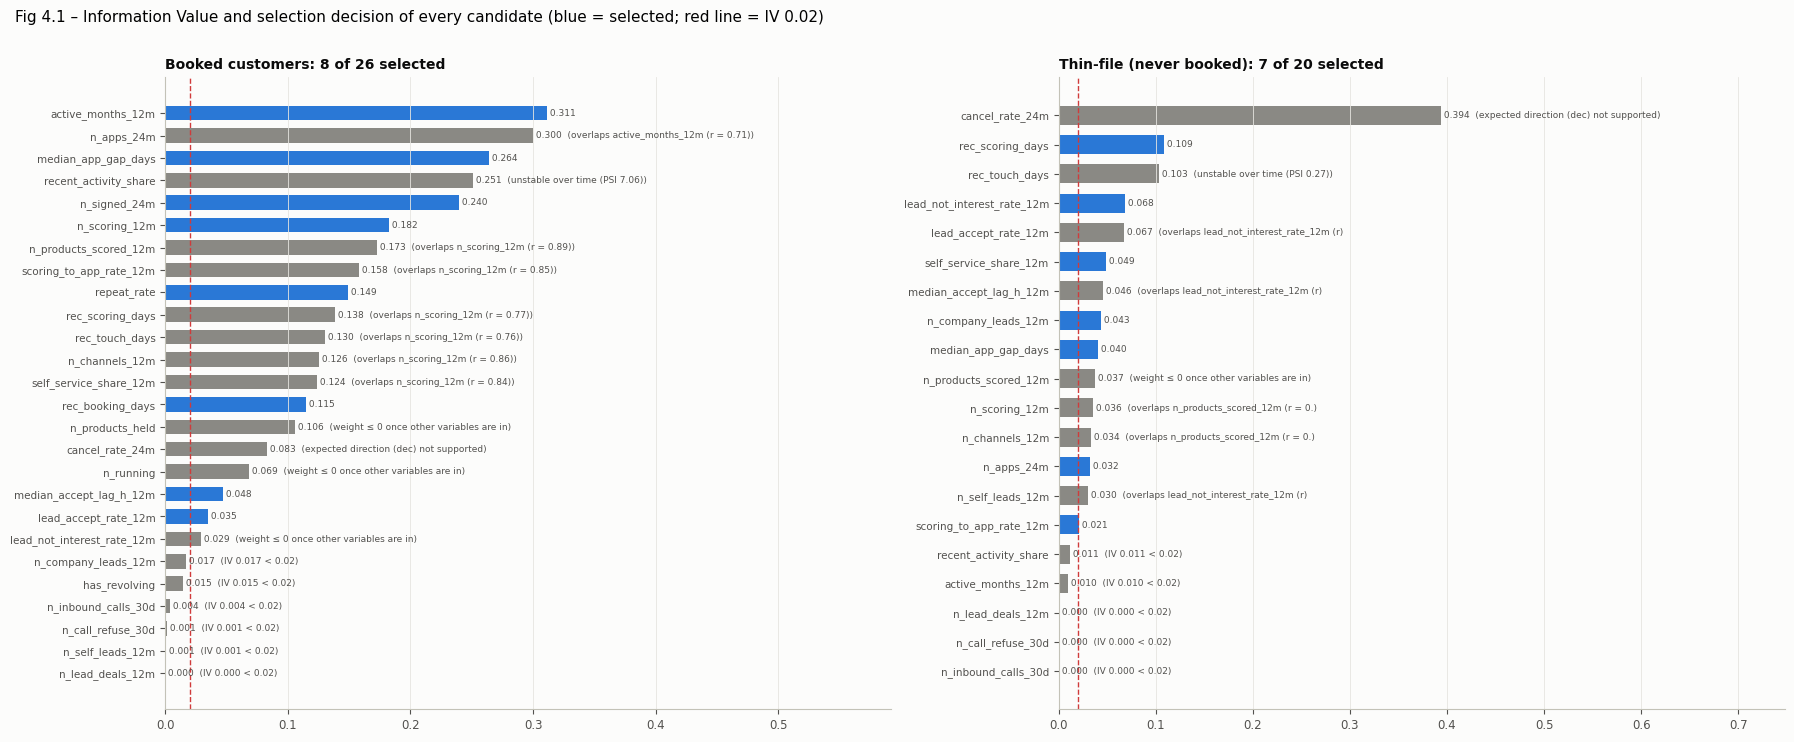

scorecard,Booked customers,Thin-file (never booked)
variable,,
active_months_12m,selected,dropped: IV 0.010 < 0.02
cancel_rate_24m,dropped: expected direction (dec) not supporte...,dropped: expected direction (dec) not supporte...
has_revolving,dropped: IV 0.015 < 0.02,NaN
lead_accept_rate_12m,selected,dropped: overlaps lead_not_interest_rate_12m (...
lead_not_interest_rate_12m,dropped: weight ≤ 0 once other variables are i...,selected
median_accept_lag_h_12m,selected,dropped: overlaps lead_not_interest_rate_12m (...
median_app_gap_days,selected,selected
n_apps_24m,dropped: overlaps active_months_12m (r = 0.71),selected
n_call_refuse_30d,dropped: IV 0.001 < 0.02,dropped: IV 0.000 < 0.02


In [18]:
def iv_label(x):
    return "very weak" if x < 0.02 else "weak" if x < 0.1 else "medium" if x < 0.3 else "strong"

sel_tbl = pd.concat([pd.DataFrame({"scorecard": c["name"], "dimension": [VARS[v]["dim"] for v in c["iv"].index], "IV": c["iv"].values,
                                   "strength": [iv_label(x) for x in c["iv"]], "PSI T0→Snapshot": c["psi"].values,
                                   "status": [c["status"][v] for v in c["iv"].index]}, index=c["iv"].index)
                     for c in (CARD_MAIN, CARD_THIN)]).rename_axis("variable").reset_index()
sel_tbl.to_csv(OUT / "variable_selection_iv.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, card in zip(axes, (CARD_MAIN, CARD_THIN)):
    d = sel_tbl[sel_tbl["scorecard"] == card["name"]].sort_values("IV")
    ax.barh(d["variable"], d["IV"], color=[BLUE if s == "selected" else GREY for s in d["status"]], height=0.65)
    for i, (val, s) in enumerate(zip(d["IV"], d["status"])):
        ax.text(val, i, f" {val:.3f}  {'' if s == 'selected' else '(' + s.split(':')[1].strip()[:38] + ')'}", va="center", fontsize=6.5, color="#52514e")
    ax.axvline(IV_MIN, color=RED, linestyle="--", linewidth=1)
    ax.set_xlim(0, d["IV"].max() * 1.9); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7.5)
    ax.set_title(f"{card['name']}: {len(card['selected'])} of {len(d)} selected", loc="left")
fig.suptitle(f"Fig 4.1 – Information Value and selection decision of every candidate (blue = selected; red line = IV {IV_MIN})", x=0.01, ha="left", fontsize=11)
save(fig, "4_1_iv_selection")
sel_tbl.pivot_table(index="variable", columns="scorecard", values="status", aggfunc="first")

> **💡 Insight (Fig 4.1):**
> - **Scorecard khách đã vay giữ 8/26 biến:** số tháng hoạt động, khoảng cách giữa các hồ sơ, số hợp đồng 24 tháng, số lần scoring, tỉ lệ quay lại vay, thời gian từ khoản vay gần nhất, tốc độ chấp nhận lead, tỉ lệ chấp nhận lead.
> - **Scorecard thin-file giữ 7/20 biến:** thời gian từ lần scoring gần nhất, tỉ lệ "không quan tâm", tỉ lệ tự phục vụ, số lead do công ty đẩy, khoảng cách hồ sơ, số hồ sơ, phễu cá nhân.
> - **Kết quả của các biến mới:**
>
>   | Biến mới | Kết quả |
>   |---|---|
>   | `recent_activity_share` | IV cao thứ 4 (0,25) nhưng **bị loại vì không ổn định** (PSI 7,06). Bộ lọc mới đã chặn đúng lỗi kiểu Recency của bản cũ |
>   | `median_accept_lag_h_12m` | Được giữ ở scorecard khách đã vay, đóng góp nhỏ (tối đa 3 điểm) |
>   | `scoring_to_app_rate_12m` | Được giữ ở scorecard thin-file |
>   | `n_company_leads_12m` | Được giữ ở scorecard thin-file |
>   | `n_self_leads_12m` | Quá hiếm (IV 0,001) |
>
> - `cancel_rate_24m` lại bị loại ở cả hai scorecard. Hủy hồ sơ **không** làm giảm chuyển đổi; với khách thin-file, hủy hồ sơ còn có IV rất cao (0,39) theo chiều *tăng*.
>
> **➡️ Ý nghĩa (Yêu cầu 1):** Yếu tố phản ánh gắn kết **khác nhau theo loại khách**:
> - Khách đã vay: gắn kết thể hiện qua **nhịp vay và nộp hồ sơ đều đặn**.
> - Khách chưa từng vay: gắn kết thể hiện qua **hoạt động scoring gần đây và phản hồi với lead**.
> - Đây là lý do tách hai scorecard.

### 4.2 Ràng buộc đơn điệu: sửa lỗi Recency

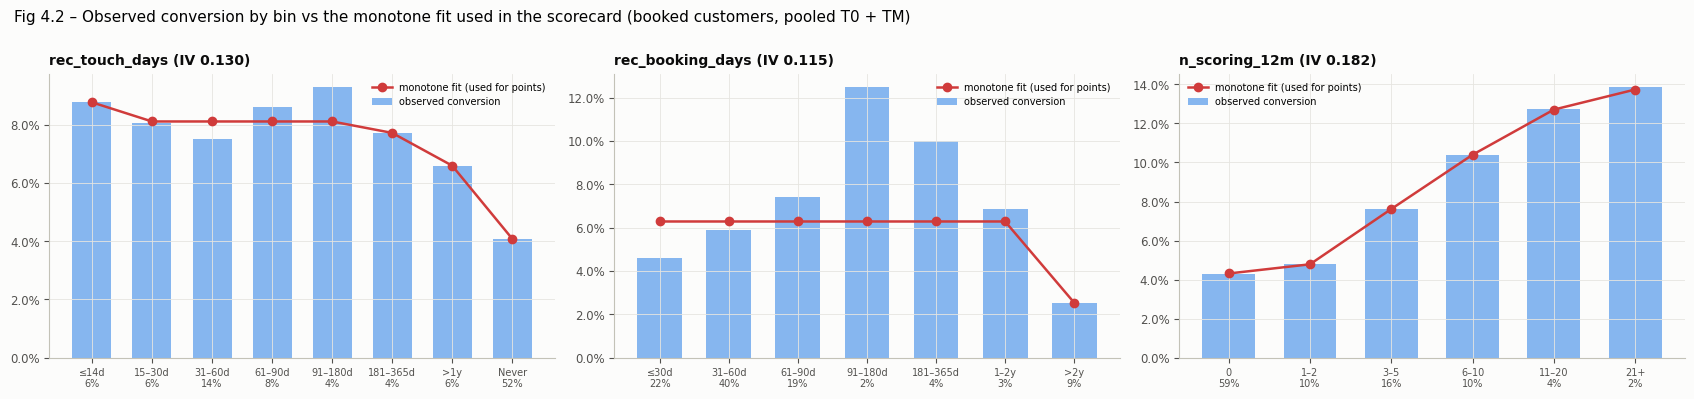

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, v in zip(axes, ["rec_touch_days", "rec_booking_days", "n_scoring_12m"]):
    t = CARD_MAIN["tables"][v]
    x = np.arange(len(t))
    ax.bar(x, t["rate_raw"], color=BLUE_L, width=0.65, label="observed conversion")
    ax.plot(x, t["rate_fit"], color=RED, marker="o", linewidth=1.8, label="monotone fit (used for points)")
    ax.set_xticks(x, [f"{b}\n{s:.0%}" for b, s in zip(t["bin"], t["share"])], fontsize=7)
    ax.yaxis.set_major_formatter(PCT1)
    ax.set_title(f"{v} (IV {CARD_MAIN['iv'][v]:.3f})", loc="left")
    ax.legend(frameon=False, fontsize=7)
fig.suptitle("Fig 4.2 – Observed conversion by bin vs the monotone fit used in the scorecard (booked customers, pooled T0 + TM)", x=0.01, ha="left", fontsize=11)
save(fig, "4_2_monotone")

> **💡 Insight (Fig 4.2, scorecard khách đã vay):**
> - `rec_booking_days`: tỉ lệ quan sát cao nhất ở nhóm 91–180 ngày (12,5%), còn nhóm ≤30 ngày chỉ 4,6%, đúng hiệu ứng "vừa vay Tết xong". Đường đơn điệu **gộp mọi khoản vay trong vòng 2 năm về cùng một mức (6,3%)**; chỉ khách không vay quá 2 năm mới bị trừ (2,5%).
> - `rec_touch_days`: tương tự, mọi tương tác trong 6 tháng được coi như nhau.
> - `n_scoring_12m`: dữ liệu vốn đã đơn điệu nên đường fit trùng tỉ lệ quan sát.
>
> **➡️ Ý nghĩa:** Điểm **không thưởng cho mùa vụ**. "Vừa vay xong" không được cộng thêm điểm, cũng không bị trừ điểm; chỉ "lâu không quay lại" mới bị trừ. Nhờ đó điểm giữ được ý nghĩa khi dùng ở ngày chốt (PSI điểm 0,014, §5.2).

### 4.3 Bảng điểm, trọng số và thang điểm chung

{'Booked customers': 'base 13.8 pts + up to 91.5 pts', 'Thin-file (never booked)': 'base -10.0 pts + up to 111.2 pts'}


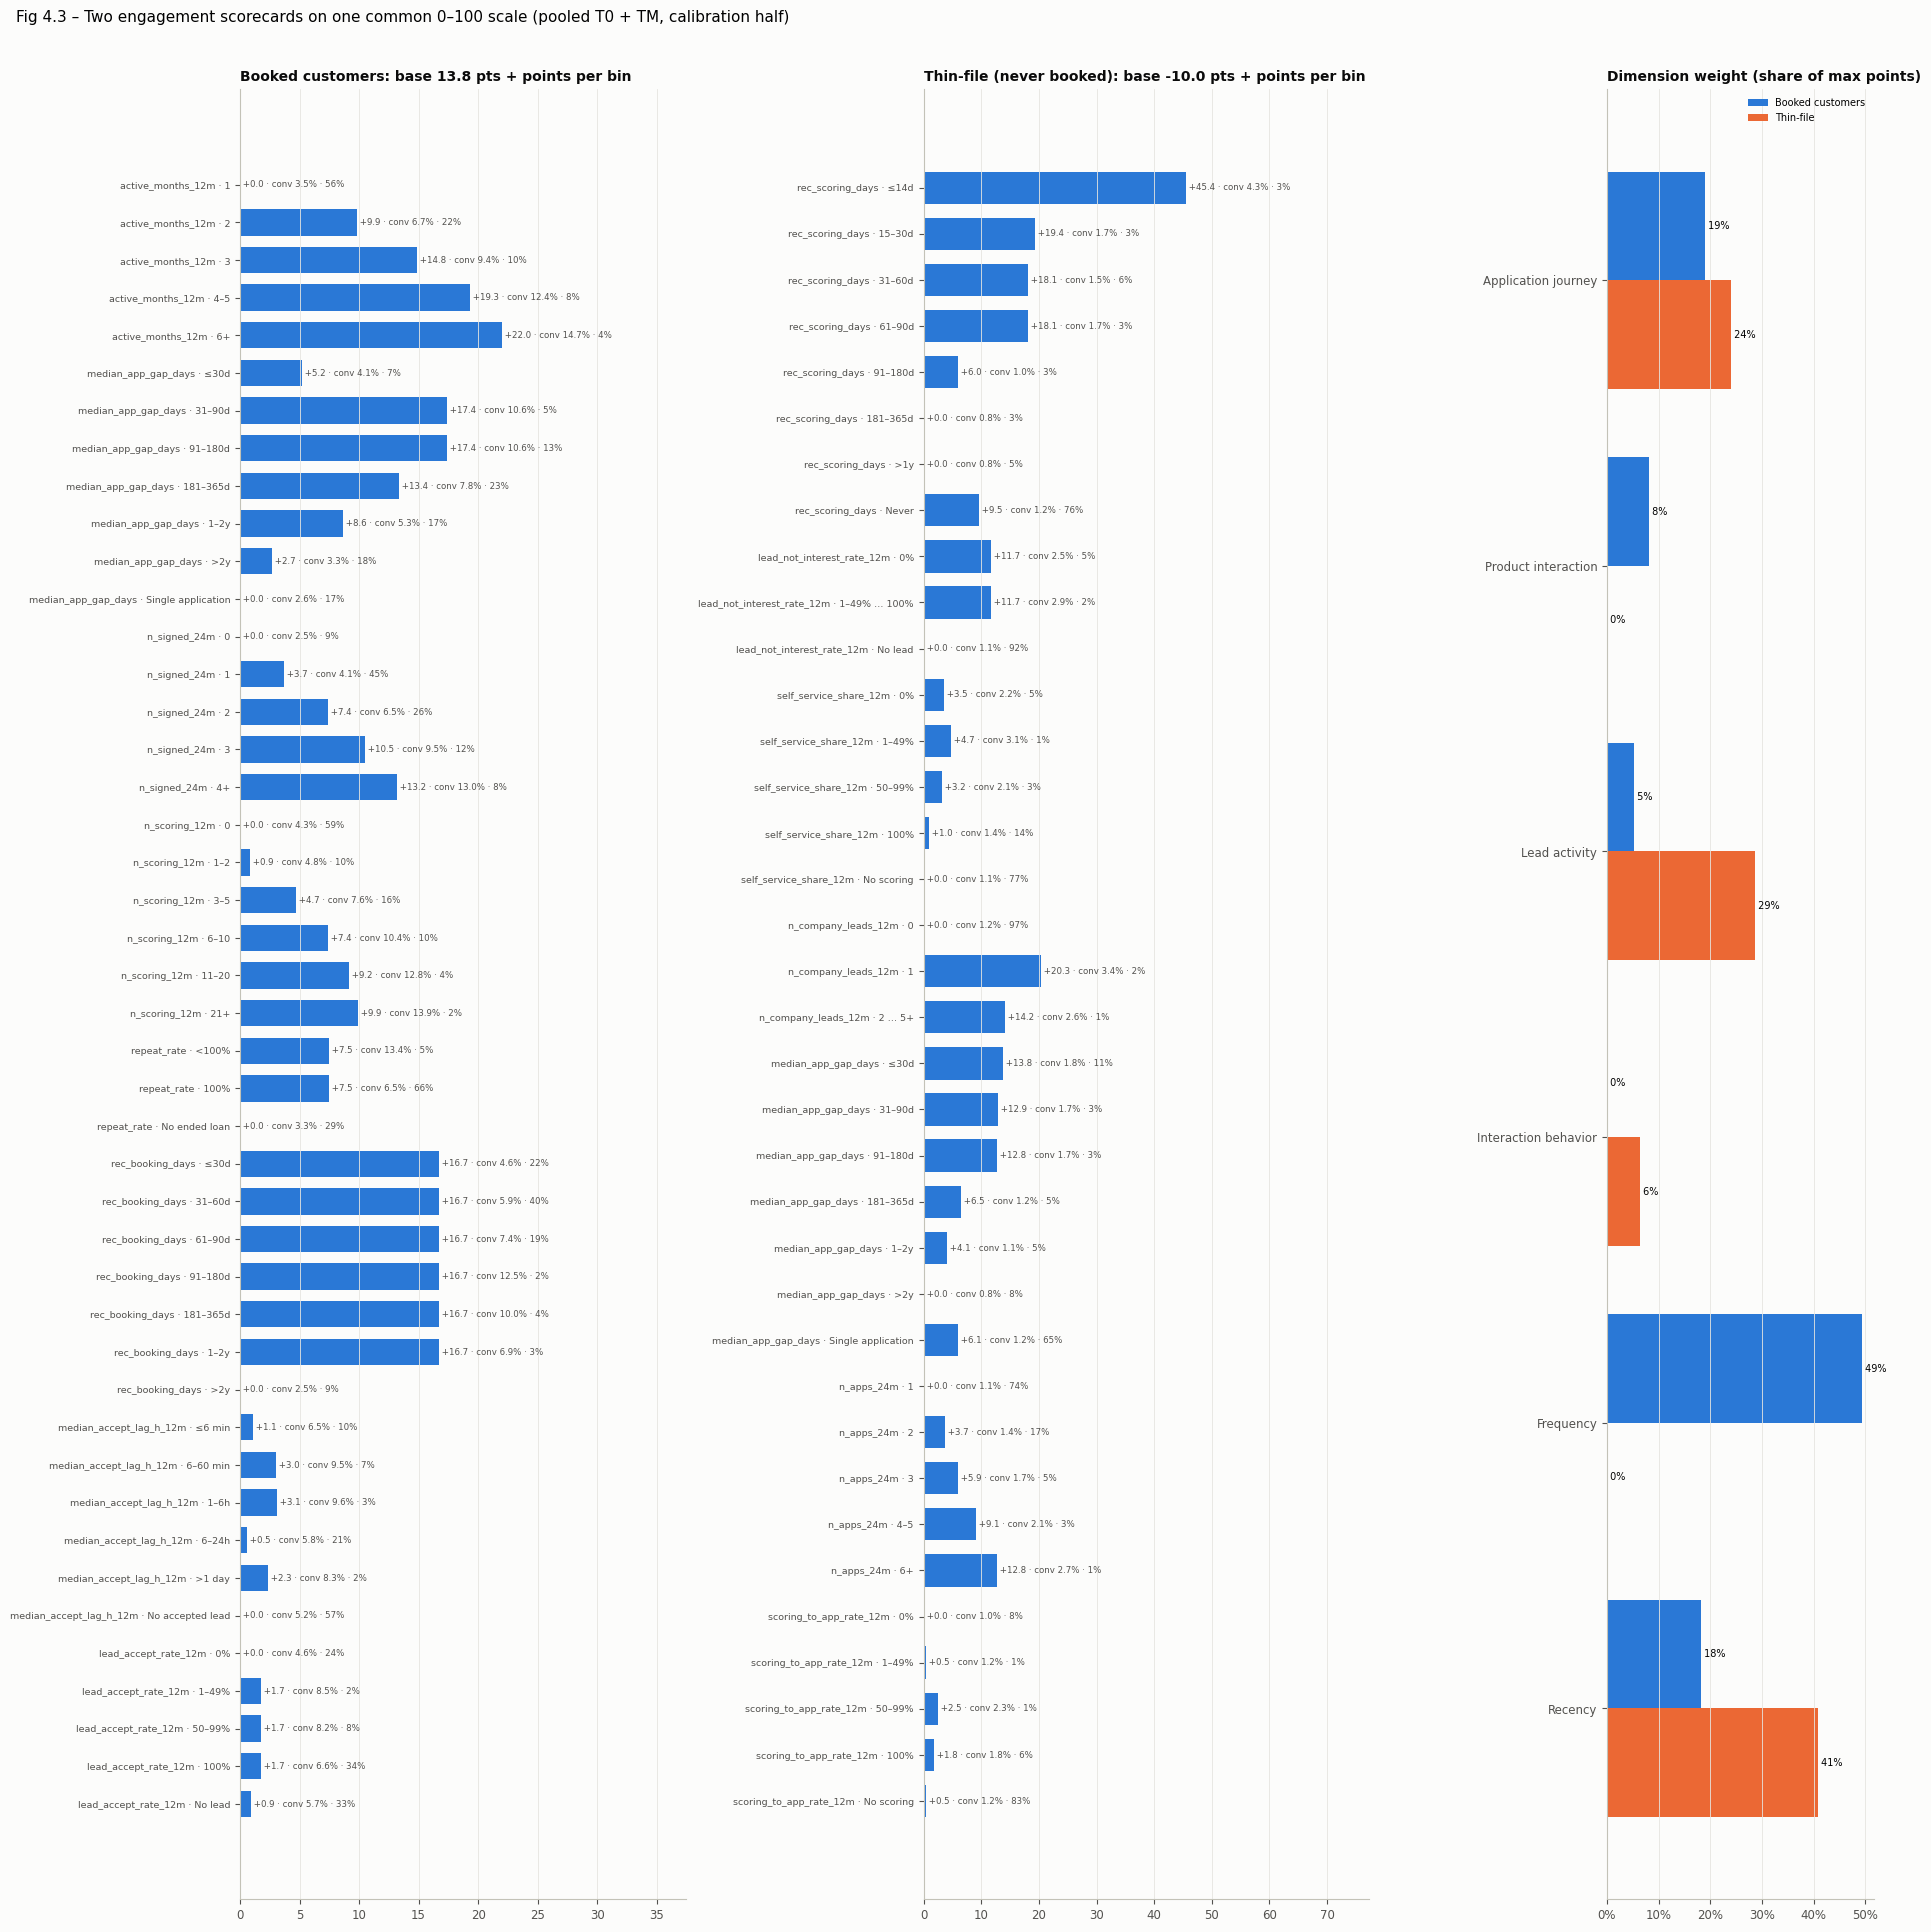

,Recency,Frequency,Interaction behavior,Lead activity,Product interaction,Application journey
Booked,0.1828,0.4926,0.0000,0.0529,0.0817,0.1901
Thin-file,0.4086,0.0000,0.0648,0.2872,0.0000,0.2394


In [20]:
# Common 0-100 scale: score = A + B * predicted log-odds, p1 -> 0 and p99 -> 100 on the pooled training rows of both cards
L_all = np.concatenate([CARD_MAIN["logit_train"], CARD_THIN["logit_train"]])
L1, L99 = np.percentile(L_all, [1, 99])
SCALE_B = 100 / (L99 - L1)
SCALE_A = -SCALE_B * L1

def card_points(card):
    rows = []
    for v in card["selected"]:
        t = card["tables"][v]
        rows.append(t.assign(points=SCALE_B * card["coef"][v] * (t["woe"] - t["woe"].min()), scorecard=card["name"]))
    sc = pd.concat(rows, ignore_index=True)
    card["points"] = {v: sc[sc["variable"] == v].set_index("bin")["points"] for v in card["selected"]}
    card["maxpts"] = pd.Series({v: card["points"][v].max() for v in card["selected"]})
    card["base"] = SCALE_A + SCALE_B * (card["intercept"] + sum(card["coef"][v] * card["tables"][v]["woe"].min() for v in card["selected"]))
    card["dim_w"] = (card["maxpts"].groupby([VARS[v]["dim"] for v in card["selected"]]).sum() / card["maxpts"].sum()).reindex(DIM_ORDER).fillna(0)
    return sc[["scorecard", "dimension", "variable", "bin", "n", "share", "rate_raw", "rate_fit", "woe", "points"]]

SCORECARD = pd.concat([card_points(CARD_MAIN), card_points(CARD_THIN)], ignore_index=True)
SCORECARD.to_csv(OUT / "eng_scorecard.csv", index=False)
print({c["name"]: f"base {c['base']:.1f} pts + up to {c['maxpts'].sum():.1f} pts" for c in (CARD_MAIN, CARD_THIN)})

def score_date(d, cards=(CARD_MAIN, CARD_THIN)):
    """ENG_score (0-100), scorecard used, points per variable and 0-100 sub-score per dimension for every customer at date d."""
    n = len(F[d])
    out = pd.DataFrame({"ENG_score": np.zeros(n), "scorecard": ""})
    pts = pd.DataFrame(np.nan, index=range(n), columns=sorted({v for c in cards for v in c["selected"]}))
    for c in cards:
        rows = np.where(c["member"][d])[0]
        p = pd.DataFrame({v: B[d][v].iloc[rows].astype(str).map(c["maps"][v]).map(c["points"][v]).astype(float).fillna(0).values
                          for v in c["selected"]}, index=rows)
        pts.loc[rows, p.columns] = p.values
        out.loc[rows, "ENG_score"] = (c["base"] + p.sum(axis=1)).clip(0, 100).values
        out.loc[rows, "scorecard"] = c["name"]
        for dim in DIM_ORDER:
            vs = [v for v in c["selected"] if VARS[v]["dim"] == dim]
            if vs:
                out.loc[rows, f"sub_{dim}"] = (100 * p[vs].sum(axis=1) / c["maxpts"][vs].sum()).values
    return out, pts

S = {d: score_date(d) for d in DATES}
S0, S1, SS, PS = S[T0][0], S[T1][0], S[SNAPSHOT][0], S[SNAPSHOT][1]

fig, axes = plt.subplots(1, 3, figsize=(19, 0.3 * len(SCORECARD) / 1.4 + 2.5), gridspec_kw={"width_ratios": [1.5, 1.5, 0.9]})
for ax, card in zip(axes[:2], (CARD_MAIN, CARD_THIN)):
    d = SCORECARD[SCORECARD["scorecard"] == card["name"]].iloc[::-1].reset_index(drop=True)
    ax.barh(range(len(d)), d["points"], color=BLUE, height=0.7)
    ax.set_yticks(range(len(d)), [f"{r.variable} · {r.bin}" for r in d.itertuples()], fontsize=6.8)
    for i, r in enumerate(d.itertuples()):
        ax.text(r.points, i, f" +{r.points:.1f} · conv {r.rate_raw:.1%} · {r.share:.0%}", va="center", fontsize=6.2, color="#52514e")
    ax.set_xlim(0, d["points"].max() * 1.7); ax.grid(axis="y", visible=False)
    ax.set_title(f"{card['name']}: base {card['base']:.1f} pts + points per bin", loc="left")
ax = axes[2]
dw = pd.DataFrame({"Booked": CARD_MAIN["dim_w"], "Thin-file": CARD_THIN["dim_w"]})
x = np.arange(len(dw)); w = 0.38
ax.barh(x + w / 2, dw["Booked"], w, color=BLUE, label="Booked customers")
ax.barh(x - w / 2, dw["Thin-file"], w, color=ORANGE, label="Thin-file")
for i, (a_, b_) in enumerate(zip(dw["Booked"], dw["Thin-file"])):
    ax.text(a_, i + w / 2, f" {a_:.0%}", va="center", fontsize=7); ax.text(b_, i - w / 2, f" {b_:.0%}", va="center", fontsize=7)
ax.set_yticks(x, dw.index); ax.xaxis.set_major_formatter(PCT); ax.legend(frameon=False, fontsize=7); ax.grid(axis="y", visible=False)
ax.set_title("Dimension weight (share of max points)", loc="left")
fig.suptitle("Fig 4.3 – Two engagement scorecards on one common 0–100 scale (pooled T0 + TM, calibration half)", x=0.01, ha="left", fontsize=11)
save(fig, "4_3_scorecard")
dw.T

> **💡 Insight (Fig 4.3):**
>
> | Khía cạnh | Khách đã vay | Khách thin-file |
> |---|---|---|
> | Frequency | **49%** | 0% |
> | Application journey | 19% | 24% |
> | Recency | 18% | **41%** |
> | Product interaction | 8% | 0% |
> | Lead activity | 5% | **29%** |
> | Interaction behavior | 0% | **6%** |
>
> - Cả hai scorecard dùng **cùng một thang** (điểm = A + B × log-odds), nên 60 điểm có cùng ý nghĩa xác suất ở cả hai nhóm.
> - Điểm nền khác nhau: **13,8** với khách đã vay và **−10** với khách thin-file, vì khả năng quay lại của khách thin-file thấp hơn hẳn (khoảng 1,3% so với 5%).
> - Với khách thin-file, scoring trong 14 ngày gần nhất cộng tới **+45 điểm**, có 1 lead do công ty đẩy cộng **+20 điểm**.
>
> **➡️ Ý nghĩa:** Tách scorecard giúp **Lead và Interaction có trọng số thật** ở đúng nhóm khách mà các tín hiệu này quan trọng: khách chưa có lịch sử vay. Ở khách đã vay, thông tin của chúng đã nằm trong nhịp vay.

---
## 5. Kiểm chứng điểm (Yêu cầu 6 – phần 1: sức dự báo và độ ổn định)

### 5.1 So sánh các phương án (holdout, và out-of-time tại T1)
| Phương án | Mục đích so sánh |
|---|---|
| **ENG final**: 2 scorecard, học trên T0 + TM | phương án chọn |
| 1 scorecard chung, học trên T0 + TM | tách scorecard riêng cho thin-file có giúp không? |
| 2 scorecard, chỉ học trên T0 | học trên nhiều mốc có giúp không? |
| RFM đơn giản | cách làm phổ biến khi không có dữ liệu kết quả |
| LightGBM đơn điệu (§5.3) | trần tham chiếu: mô hình phức tạp hơn được thêm bao nhiêu |

In [21]:
def ks(yv, s):
    fpr, tpr, _ = roc_curve(yv, s)
    return float(np.max(tpr - fpr))

def boot_auc(yv, s, n=50, seed=SEED):
    r = np.random.default_rng(seed)
    return np.percentile([roc_auc_score(yv[i], s[i]) for i in r.integers(0, len(yv), size=(n, len(yv)))], [2.5, 97.5])

CARD_GLOBAL = fit_card("Global (one card)", ALL, CANDIDATES)
CARD_MAIN_T0 = fit_card("Booked, T0 only", BOOKED, CANDIDATES, train_dates=[T0])
CARD_THIN_T0 = fit_card("Thin, T0 only", THIN, [v for v in CANDIDATES if v not in BOOKED_VARS], train_dates=[T0])

def seg_logit(d, cards):
    s = np.zeros(len(F[d]))
    for c in cards:
        rows = np.where(c["member"][d])[0]
        s[rows] = card_logit(c, B[d], rows)
    return s

def rfm(d):
    Fd = F[d]
    return (Fd["rec_touch_days"].fillna(10_000).rank(ascending=False) + Fd["active_months_12m"].rank() + Fd["n_scoring_12m"].rank()).values

HOLD_TR = {d: HOLD for d in TRAIN}
variants = {
    "ENG final (2 cards, T0+TM)": lambda d: S[d][0]["ENG_score"].values,
    "1 global card (T0+TM)": lambda d: seg_logit(d, [CARD_GLOBAL]),
    "2 cards, trained on T0 only": lambda d: seg_logit(d, [CARD_MAIN_T0, CARD_THIN_T0]),
    "Simple RFM rank": rfm,
}
perf, SCORES_T1 = [], {}
for name, fn in variants.items():
    s_tr = np.concatenate([fn(d)[HOLD] for d in TRAIN]); y_tr = np.concatenate([y[d][HOLD] for d in TRAIN])
    s1 = fn(T1); SCORES_T1[name] = s1
    th = THIN[T1][HOLD]
    perf.append({"model": name, "AUC holdout (T0+TM)": roc_auc_score(y_tr, s_tr), "AUC out-of-time T1": roc_auc_score(y1[HOLD], s1[HOLD]),
                 "AUC T1 booked": roc_auc_score(y1[HOLD][~th], s1[HOLD][~th]), "AUC T1 thin-file": roc_auc_score(y1[HOLD][th], s1[HOLD][th]),
                 "KS T1": ks(y1[HOLD], s1[HOLD])})
perf = pd.DataFrame(perf).set_index("model")
ci = boot_auc(y1[HOLD], SCORES_T1["ENG final (2 cards, T0+TM)"][HOLD])
print(f"ENG final out-of-time AUC 95% CI: {ci[0]:.3f}–{ci[1]:.3f}")
perf

ENG final out-of-time AUC 95% CI: 0.700–0.704


,AUC holdout (T0+TM),AUC out-of-time T1,AUC T1 booked,AUC T1 thin-file,KS T1
model,,,,,
"ENG final (2 cards, T0+TM)",0.7151,0.7023,0.6632,0.5590,0.3041
1 global card (T0+TM),0.7097,0.6982,0.6595,0.5456,0.2963
"2 cards, trained on T0 only",0.7146,0.7004,0.6614,0.5523,0.3015
Simple RFM rank,0.6524,0.6355,0.6191,0.5210,0.2060


### 5.2 Decile, gain và độ ổn định của ENG final (out-of-time T1, holdout)

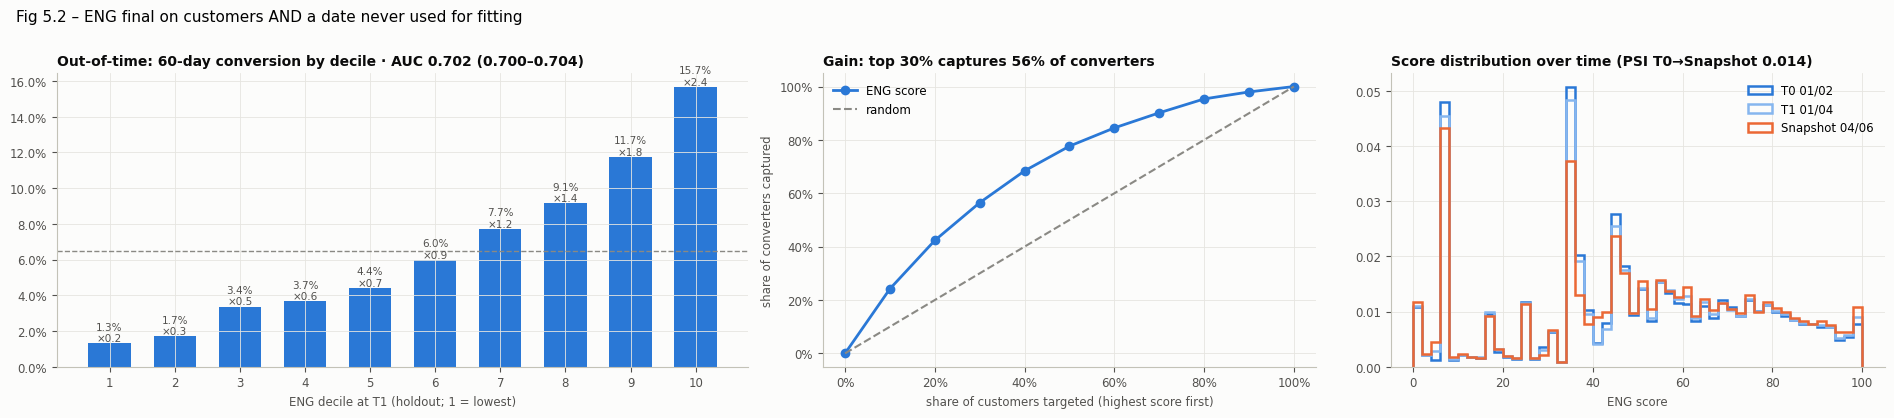

,mean_score,PSI_vs_T0
as_of,,
T0 01/02,49.6996,0.0000
TM 01/03,49.8787,0.0007
T1 01/04,50.1759,0.0018
Snapshot 04/06,51.3985,0.0144


,decile,customers,min_score,max_score,conversion,converters,lift,cum_capture
0,1,50007,0.0000,6.0618,0.0131,656,0.2029,1.0000
1,2,50007,6.0618,29.5568,0.0169,847,0.2619,0.9797
2,3,50006,29.5568,35.0564,0.0336,1682,0.5201,0.9535
3,4,50007,35.0564,44.0248,0.0366,1828,0.5653,0.9015
4,5,50006,44.0248,50.1621,0.0442,2209,0.6831,0.8450
5,6,50007,50.1621,57.7853,0.0599,2996,0.9265,0.7767
6,7,50006,57.7853,66.3356,0.0772,3858,1.1930,0.6840
7,8,50007,66.3356,75.8963,0.0914,4570,1.4132,0.5647
8,9,50006,75.8963,86.2513,0.1173,5865,1.8137,0.4234
9,10,50007,86.2513,100.0000,0.1565,7827,2.4204,0.2420


In [22]:
yh1 = y1[HOLD]
s1 = S1["ENG_score"].values[HOLD]
hv = pd.DataFrame({"score": s1, "y": yh1})
hv["decile"] = pd.qcut(hv["score"].rank(method="first"), 10, labels=range(1, 11))
dec = hv.groupby("decile", observed=True).agg(customers=("y", "size"), min_score=("score", "min"), max_score=("score", "max"),
                                              conversion=("y", "mean"), converters=("y", "sum")).reset_index()
dec["lift"] = dec["conversion"] / yh1.mean()
dec["cum_capture"] = dec["converters"][::-1].cumsum()[::-1] / dec["converters"].sum()
dec.to_csv(OUT / "validation_oot_deciles.csv", index=False)

score_bins = np.unique(np.quantile(S0["ENG_score"], np.linspace(0, 1, 11)))
cut = lambda s: pd.cut(s, np.r_[-np.inf, score_bins[1:-1], np.inf])
stab = pd.DataFrame({"as_of": ["T0 01/02", "TM 01/03", "T1 01/04", "Snapshot 04/06"],
                     "mean_score": [S[d][0]["ENG_score"].mean() for d in DATES],
                     "PSI_vs_T0": [psi(cut(S0["ENG_score"]), cut(S[d][0]["ENG_score"])) for d in DATES]}).set_index("as_of")

fig, axes = plt.subplots(1, 3, figsize=(19, 4.2), gridspec_kw={"width_ratios": [1.4, 1, 1]})
ax = axes[0]
ax.bar(dec["decile"].astype(str), dec["conversion"], color=BLUE, width=0.65)
ax.axhline(yh1.mean(), color=GREY, linestyle="--", linewidth=1)
for i, (c, l) in enumerate(zip(dec["conversion"], dec["lift"])):
    ax.text(i, c, f"{c:.1%}\n×{l:.1f}", ha="center", va="bottom", fontsize=7.5, color="#52514e")
ax.yaxis.set_major_formatter(PCT1); ax.set_xlabel("ENG decile at T1 (holdout; 1 = lowest)")
ax.set_title(f"Out-of-time: 60-day conversion by decile · AUC {perf.iloc[0]['AUC out-of-time T1']:.3f} ({ci[0]:.3f}–{ci[1]:.3f})", loc="left")
ax = axes[1]
xg = np.r_[0, np.arange(1, 11) / 10]
gain = np.r_[0, dec.sort_values("decile", ascending=False)["converters"].cumsum().values / dec["converters"].sum()]
ax.plot(xg, gain, color=BLUE, marker="o", linewidth=2, label="ENG score")
ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", label="random")
ax.xaxis.set_major_formatter(PCT); ax.yaxis.set_major_formatter(PCT); ax.legend(frameon=False)
ax.set_xlabel("share of customers targeted (highest score first)"); ax.set_ylabel("share of converters captured")
ax.set_title(f"Gain: top 30% captures {gain[3]:.0%} of converters", loc="left")
ax = axes[2]
for (lab, d), c in zip([("T0 01/02", T0), ("T1 01/04", T1), ("Snapshot 04/06", SNAPSHOT)], [BLUE, BLUE_L, ORANGE]):
    ax.hist(S[d][0]["ENG_score"], bins=50, histtype="step", linewidth=1.8, color=c, label=lab, density=True)
ax.set_xlabel("ENG score"); ax.legend(frameon=False)
ax.set_title(f"Score distribution over time (PSI T0→Snapshot {stab['PSI_vs_T0'].iloc[-1]:.3f})", loc="left")
fig.suptitle("Fig 5.2 – ENG final on customers AND a date never used for fitting", x=0.01, ha="left", fontsize=11)
save(fig, "5_2_oot_validation")
display(stab)
dec

> **💡 Insight (bảng 5.1, Fig 5.2):** đánh giá trên khách *và* thời điểm chưa dùng để học.
>
> | Phương án | AUC out-of-time T1 | AUC thin-file |
> |---|---|---|
> | **ENG final** (2 scorecard, học T0 + TM) | **0,702** (KTC 95%: 0,700–0,704) | **0,559** |
> | 1 scorecard chung | 0,698 | 0,546 |
> | 2 scorecard, chỉ học T0 | 0,700 | |
> | RFM đơn giản | 0,636 | |
>
> - **Cả hai cải tiến đều giúp, dù mức tăng nhỏ:**
>   - Tách scorecard: +0,004 tổng thể, +0,013 trong nhóm thin-file.
>   - Học trên nhiều mốc: +0,002, và điểm ổn định hơn.
> - So với RFM đơn giản: **+0,066**.
> - **Decile cao nhất chuyển đổi 15,7% (×2,4)**, decile thấp nhất 1,3%. **30% khách điểm cao nhất thu được 56% số khách chuyển đổi.**
> - **Điểm ổn định:** PSI 0,014 tại ngày chốt; trung bình điểm chỉ đi từ 49,7 lên 51,4.
>
> **➡️ Ý nghĩa:**
> - Điểm dự báo được trên khách mới và tại thời điểm mới, nên dùng được ở ngày chốt.
> - Khách thin-file vẫn **khó dự báo** (AUC 0,56), vì họ chỉ có rất ít hành vi để đo. Đây là giới hạn của dữ liệu, không phải của phương pháp.

### 5.3 Mô hình thách thức: LightGBM có ràng buộc đơn điệu + SHAP
Gradient boosting học được tương tác và đường cong phức tạp mà scorecard cộng tính không có. Để vẫn **giải thích được**:
- **Ràng buộc đơn điệu** theo đúng chiều kinh doanh của từng biến (cột `expected_direction` ở §2).
- **SHAP** (tính trực tiếp bằng `pred_contrib` của LightGBM): mỗi dự báo được tách thành phần đóng góp của từng biến.

Mô hình được học trên cùng dữ liệu (T0 + TM, nửa calibration) và kiểm chứng trên **cùng nửa holdout tại T1**.

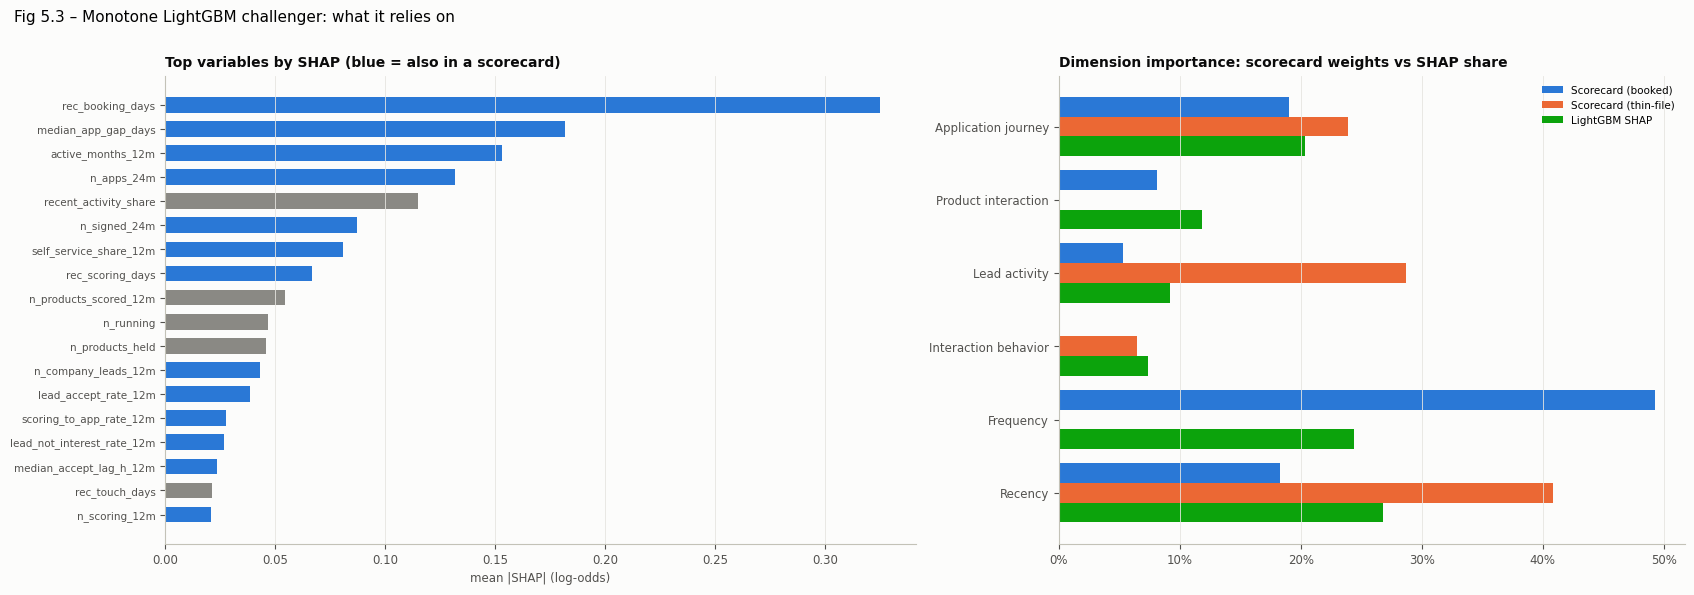

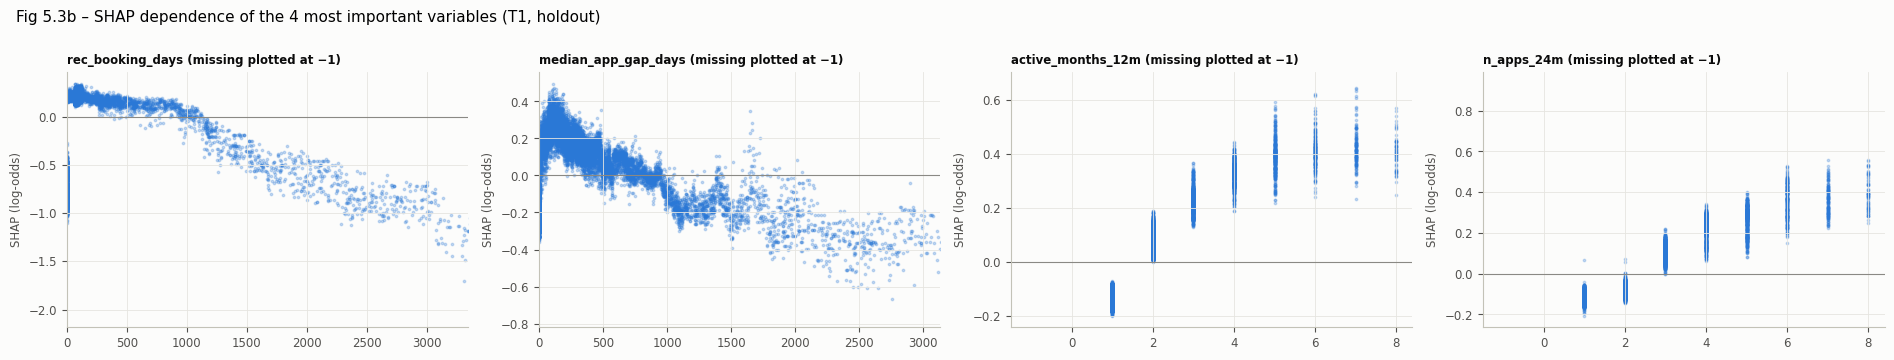

,AUC holdout (T0+TM),AUC out-of-time T1,AUC T1 booked,AUC T1 thin-file,KS T1
model,,,,,
"ENG final (2 cards, T0+TM)",0.7151,0.7023,0.6632,0.5590,0.3041
1 global card (T0+TM),0.7097,0.6982,0.6595,0.5456,0.2963
"2 cards, trained on T0 only",0.7146,0.7004,0.6614,0.5523,0.3015
Simple RFM rank,0.6524,0.6355,0.6191,0.5210,0.2060
LightGBM monotone (challenger),0.7274,0.7101,0.6731,0.5502,0.3081


,mean_abs_shap
rec_booking_days,0.3251
median_app_gap_days,0.1816
active_months_12m,0.1530
n_apps_24m,0.1317
recent_activity_share,0.1150
n_signed_24m,0.0873
self_service_share_12m,0.0811
rec_scoring_days,0.0666
n_products_scored_12m,0.0545
n_running,0.0468


In [23]:
GB_FEATS = CANDIDATES
mono = [1 if VARS[v]["direction"] == "inc" else -1 if VARS[v]["direction"] == "dec" else 0 for v in GB_FEATS]
Xtr = pd.concat([F[d].iloc[CAL][GB_FEATS] for d in TRAIN], ignore_index=True)
ytr_gb = np.concatenate([y[d][CAL] for d in TRAIN])
gbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=500, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, monotone_constraints=mono, monotone_constraints_method="advanced",
                         random_state=SEED, verbose=-1).fit(Xtr, ytr_gb)
p_gb = {d: gbm.predict_proba(F[d][GB_FEATS])[:, 1] for d in DATES}
auc_gb_tr = roc_auc_score(np.concatenate([y[d][HOLD] for d in TRAIN]), np.concatenate([p_gb[d][HOLD] for d in TRAIN]))
th = THIN[T1][HOLD]
perf.loc["LightGBM monotone (challenger)"] = [auc_gb_tr, roc_auc_score(yh1, p_gb[T1][HOLD]), roc_auc_score(yh1[~th], p_gb[T1][HOLD][~th]),
                                              roc_auc_score(yh1[th], p_gb[T1][HOLD][th]), ks(yh1, p_gb[T1][HOLD])]
perf.to_csv(OUT / "validation_model_comparison.csv")

# SHAP on 100k holdout customers at T1
idx_shap = np.random.default_rng(SEED).choice(HOLD, 100_000, replace=False)
contrib = gbm.booster_.predict(F1.iloc[idx_shap][GB_FEATS], pred_contrib=True)[:, :-1]
shap_imp = pd.Series(np.abs(contrib).mean(axis=0), index=GB_FEATS).sort_values(ascending=False)
shap_dim = shap_imp.groupby([VARS[v]["dim"] for v in shap_imp.index]).sum()
shap_dim = (shap_dim / shap_dim.sum()).reindex(DIM_ORDER).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
d = shap_imp.head(18)[::-1]
ax.barh(d.index, d.values, color=[BLUE if v in CARD_MAIN["selected"] + CARD_THIN["selected"] else GREY for v in d.index], height=0.65)
ax.set_xlabel("mean |SHAP| (log-odds)"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7.5)
ax.set_title("Top variables by SHAP (blue = also in a scorecard)", loc="left")
ax = axes[1]
cmp = pd.DataFrame({"Scorecard (booked)": CARD_MAIN["dim_w"], "Scorecard (thin-file)": CARD_THIN["dim_w"], "LightGBM SHAP": shap_dim})
x = np.arange(len(cmp)); w = 0.27
for k, (col, c) in enumerate(zip(cmp.columns, [BLUE, ORANGE, GREEN])):
    ax.barh(x + (1 - k) * w, cmp[col], w, color=c, label=col)
ax.set_yticks(x, cmp.index); ax.xaxis.set_major_formatter(PCT); ax.legend(frameon=False, fontsize=7.5); ax.grid(axis="y", visible=False)
ax.set_title("Dimension importance: scorecard weights vs SHAP share", loc="left")
fig.suptitle("Fig 5.3 – Monotone LightGBM challenger: what it relies on", x=0.01, ha="left", fontsize=11)
save(fig, "5_3_lgbm_shap")

top4 = [v for v in shap_imp.index[:4]]
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, v in zip(axes, top4):
    k = GB_FEATS.index(v)
    xv = F1.iloc[idx_shap][v].values
    sub = np.random.default_rng(1).choice(len(xv), 15_000, replace=False)
    ax.scatter(np.nan_to_num(xv[sub], nan=-1), contrib[sub, k], s=3, alpha=0.25, color=BLUE)
    hi = np.nanpercentile(xv, 99)
    ax.set_xlim(-1.5, hi * 1.05 if hi > 0 else 1)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set_title(f"{v} (missing plotted at −1)", loc="left", fontsize=8.5); ax.set_ylabel("SHAP (log-odds)")
fig.suptitle("Fig 5.3b – SHAP dependence of the 4 most important variables (T1, holdout)", x=0.01, ha="left", fontsize=11)
save(fig, "5_3b_shap_dependence")
display(perf)
shap_imp.to_frame("mean_abs_shap").head(15)

> **💡 Insight (Fig 5.3, 5.3b):**
> - **LightGBM đơn điệu đạt AUC out-of-time 0,710**, chỉ hơn scorecard **0,008**. Với khách thin-file nó còn *kém* hơn (0,550 so với 0,559).
> - **SHAP xác nhận cùng các yếu tố:** thời gian từ khoản vay gần nhất, khoảng cách hồ sơ, số tháng hoạt động, số hồ sơ, số hợp đồng.
> - Tỉ trọng theo khía cạnh của SHAP gần với scorecard: Recency 27%, Frequency 24%, Application 20%, Product 12%, Lead 9%, Interaction 7%.
> - Khác biệt đáng chú ý: LightGBM dựa nhiều vào `recent_activity_share` (top 5). Scorecard đã **loại** biến này vì không ổn định (PSI 7). Phần lợi thế 0,008 của LightGBM có thể *không giữ được* khi dùng ở ngày chốt.
> - Đồ thị SHAP dependence cho thấy chiều tác động đúng với ràng buộc kinh doanh, ví dụ không vay quá 2 năm thì đóng góp giảm mạnh.
>
> **➡️ Ý nghĩa:** Scorecard chỉ mất khoảng 0,008 AUC so với mô hình phức tạp, nhưng **giải thích được từng điểm** và **ổn định hơn theo thời gian**. Vì vậy ENG final dùng scorecard. Điểm LightGBM được xuất kèm (`ENG_score_ml`) làm tham chiếu và để kiểm tra chéo.

---
## 6. Phân khúc theo mức gắn kết (Yêu cầu 4)
> Phạm vi: chỉ phân nhóm theo **mức gắn kết**. Phân khúc kết hợp FH × ENG và hành động cụ thể (NBA) làm ở Challenge 3.

Ngưỡng phân khúc **không** đặt theo phân vị tùy ý mà lấy từ **tỉ lệ chuyển đổi thực tế** trên nửa holdout ở các mốc học (T0 + TM):
chia điểm thành 20 khoảng, làm trơn đơn điệu, rồi cắt tại các mức **lift** (so với trung bình) có ý nghĩa kinh doanh:

| Phân khúc | Lift chuyển đổi | Ý nghĩa |
|---|---|---|
| **Champions** | ≥ 2,0 | khả năng quay lại gấp đôi trung bình trở lên |
| **Active** | 1,0 – 2,0 | trên trung bình |
| **Warm** | 0,5 – 1,0 | dưới trung bình nhưng còn tín hiệu |
| **Dormant** | < 0,5 | gần như không tương tác |

Score cut-offs: {'Champions': 80.1, 'Active': 56.8, 'Warm': 37.0}


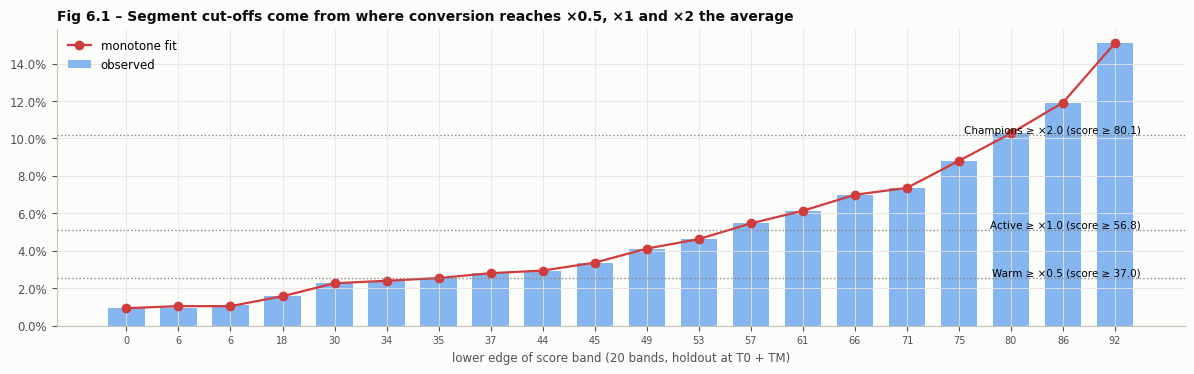

In [24]:
LIFT_CUTS = {"Champions": 2.0, "Active": 1.0, "Warm": 0.5}
SEG_ORDER = ["Champions", "Active", "Warm", "Dormant"]
SEG_COLOR = {"Champions": BLUE, "Active": BLUE_L, "Warm": ORANGE, "Dormant": GREY}

s_cut = np.concatenate([S[d][0]["ENG_score"].values[HOLD] for d in TRAIN])
y_cut = np.concatenate([y[d][HOLD] for d in TRAIN])
band = pd.qcut(pd.Series(s_cut).rank(method="first"), 20, labels=False)
bt = pd.DataFrame({"band": band, "score": s_cut, "y": y_cut}).groupby("band").agg(min_score=("score", "min"), n=("y", "size"), conv=("y", "mean"))
bt["conv_fit"] = IsotonicRegression(increasing=True).fit_transform(bt["min_score"], bt["conv"], sample_weight=bt["n"])
bt["lift_fit"] = bt["conv_fit"] / y_cut.mean()
SEG_CUTS = {}
for seg, lift in LIFT_CUTS.items():
    hit = bt[bt["lift_fit"] >= lift]
    SEG_CUTS[seg] = float(hit["min_score"].min()) if len(hit) else np.inf
print("Score cut-offs:", {k: round(v, 1) for k, v in SEG_CUTS.items()})

def segment(s):
    return np.select([s >= SEG_CUTS["Champions"], s >= SEG_CUTS["Active"], s >= SEG_CUTS["Warm"]], SEG_ORDER[:3], default="Dormant")

for d in DATES:
    S[d][0]["ENG_segment"] = segment(S[d][0]["ENG_score"].values)

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(range(len(bt)), bt["conv"], color=BLUE_L, width=0.7, label="observed")
ax.plot(range(len(bt)), bt["conv_fit"], color=RED, marker="o", linewidth=1.6, label="monotone fit")
for seg, lift in LIFT_CUTS.items():
    ax.axhline(lift * y_cut.mean(), color=GREY, linestyle=":", linewidth=1)
    ax.text(len(bt) - 0.5, lift * y_cut.mean(), f"{seg} ≥ ×{lift} (score ≥ {SEG_CUTS[seg]:.1f})", fontsize=7.5, ha="right", va="bottom")
ax.set_xticks(range(len(bt)), [f"{v:.0f}" for v in bt["min_score"]], fontsize=7)
ax.set_xlabel("lower edge of score band (20 bands, holdout at T0 + TM)"); ax.yaxis.set_major_formatter(PCT1); ax.legend(frameon=False, loc="upper left")
ax.set_title("Fig 6.1 – Segment cut-offs come from where conversion reaches ×0.5, ×1 and ×2 the average", loc="left")
save(fig, "6_1_cutoffs")

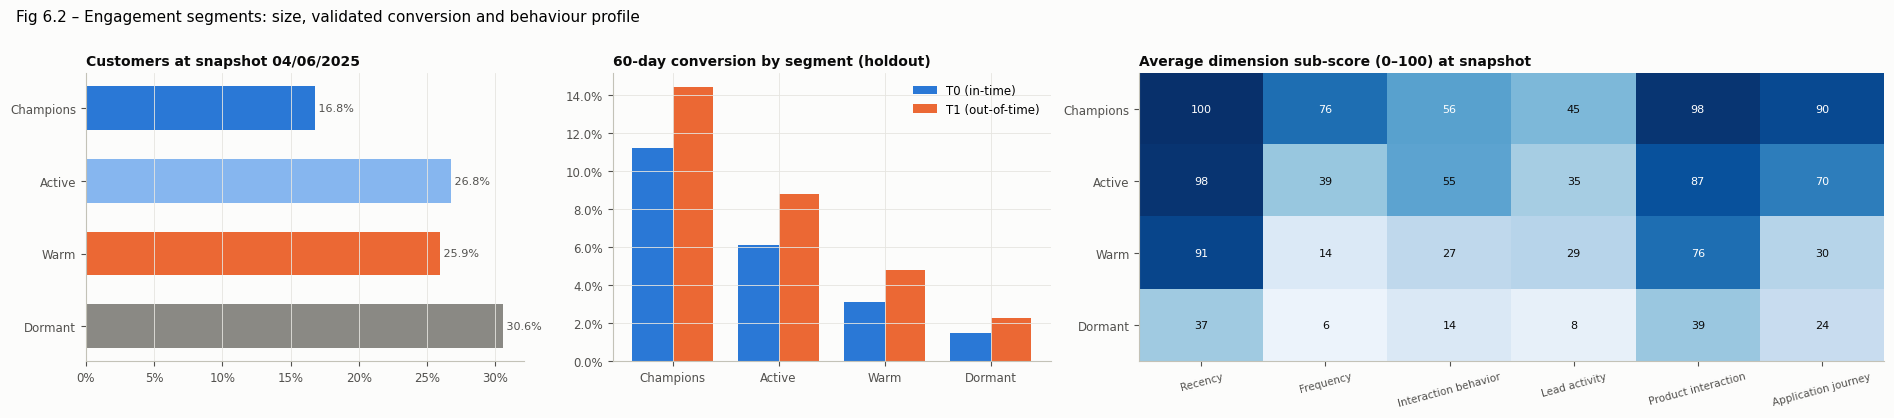

ENG_segment,Champions,Active,Warm,Dormant
customers,"167,605.0000","267,684.0000","259,474.0000","305,765.0000"
avg_score,89.7570,68.1851,47.5863,18.9114
median_days_since_touch,66.0000,151.0000,159.0000,162.0000
active_months_12m,4.5179,2.0234,1.1696,1.2120
scoring_12m,10.6441,2.5497,0.6967,0.4209
products_scored,2.4664,1.3082,0.4891,0.2378
channels,1.8321,0.7671,0.3439,0.2484
company_leads_12m,1.8023,1.7764,1.3961,0.2849
products_held,2.2523,1.6616,1.3047,0.4581
thin_file,0.0002,0.0024,0.0208,0.5767


In [25]:
prof_vars = ["rec_touch_days", "active_months_12m", "n_scoring_12m", "n_products_scored_12m", "n_channels_12m", "n_company_leads_12m",
             "n_products_held", "n_running", "recent_activity_share", "app_sessions"]
snap = pd.concat([FS[["client"] + prof_vars], SS], axis=1)
prof = snap.groupby("ENG_segment").agg(
    customers=("client", "size"), avg_score=("ENG_score", "mean"),
    median_days_since_touch=("rec_touch_days", "median"), active_months_12m=("active_months_12m", "mean"),
    scoring_12m=("n_scoring_12m", "mean"), products_scored=("n_products_scored_12m", "mean"),
    channels=("n_channels_12m", "mean"), company_leads_12m=("n_company_leads_12m", "mean"),
    products_held=("n_products_held", "mean"), thin_file=("scorecard", lambda s: (s == CARD_THIN["name"]).mean()),
    no_running_loan=("n_running", lambda s: (s == 0).mean()), app_users=("app_sessions", lambda s: (s > 0).mean())).reindex(SEG_ORDER)
prof["share"] = prof["customers"] / prof["customers"].sum()
seg_conv = pd.DataFrame({
    "conv 60d at T0 (holdout)": pd.Series(y0[HOLD]).groupby(S0["ENG_segment"].values[HOLD]).mean(),
    "conv 60d at T1 (holdout, out-of-time)": pd.Series(yh1).groupby(S1["ENG_segment"].values[HOLD]).mean(),
    "share at T1": pd.Series(S1["ENG_segment"]).value_counts(normalize=True)}).reindex(SEG_ORDER)
prof = prof.join(seg_conv)
prof.to_csv(OUT / "segment_profile.csv")

subcols = [f"sub_{d}" for d in DIM_ORDER if f"sub_{d}" in SS.columns]
heat = snap.groupby("ENG_segment")[subcols].mean().reindex(SEG_ORDER)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.7]})
ax = axes[0]
ax.barh(SEG_ORDER[::-1], prof["share"][::-1], color=[SEG_COLOR[s] for s in SEG_ORDER[::-1]], height=0.6)
bar_labels(ax, prof["share"][::-1].values, horizontal=True, size=8)
ax.xaxis.set_major_formatter(PCT); ax.grid(axis="y", visible=False); ax.set_title("Customers at snapshot 04/06/2025", loc="left")
ax = axes[1]
x = np.arange(4); w = 0.38
ax.bar(x - w / 2, prof["conv 60d at T0 (holdout)"], w, color=BLUE, label="T0 (in-time)")
ax.bar(x + w / 2, prof["conv 60d at T1 (holdout, out-of-time)"], w, color=ORANGE, label="T1 (out-of-time)")
ax.set_xticks(x, SEG_ORDER); ax.yaxis.set_major_formatter(PCT1); ax.legend(frameon=False)
ax.set_title("60-day conversion by segment (holdout)", loc="left")
ax = axes[2]
im = ax.imshow(heat.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(subcols)), [c[4:] for c in subcols], rotation=15, fontsize=7.5); ax.set_yticks(range(4), SEG_ORDER)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iat[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if heat.iat[i, j] > 55 else "#0b0b0b")
ax.grid(False); ax.set_title("Average dimension sub-score (0–100) at snapshot", loc="left")
fig.suptitle("Fig 6.2 – Engagement segments: size, validated conversion and behaviour profile", x=0.01, ha="left", fontsize=11)
save(fig, "6_2_segments")
prof.T

> **💡 Insight (Fig 6.1, 6.2, bảng hồ sơ phân khúc):** ngưỡng điểm là **Champions ≥ 80,1 · Active ≥ 56,8 · Warm ≥ 37,0**.
>
> | | Champions | Active | Warm | Dormant |
> |---|---|---|---|---|
> | % khách tại ngày chốt | 17% | 27% | 26% | 31% |
> | Chuyển đổi 60 ngày tại T1 (out-of-time) | **14,4%** | 8,8% | 4,8% | **2,3%** |
> | Tháng hoạt động / 12 tháng | 4,5 | 2,0 | 1,2 | 1,2 |
> | Lần scoring / 12 tháng | 10,6 | 2,5 | 0,7 | 0,4 |
> | Số sản phẩm đã dùng | 2,3 | 1,7 | 1,3 | 0,5 |
> | Khách thin-file | 0% | 0% | 2% | **58%** |
> | Không còn khoản vay đang chạy | 9% | 20% | 35% | **74%** |
>
> - Thứ tự chuyển đổi **giữ nguyên** ở cả mốc học và mốc out-of-time.
> - **Dormant** gồm hai nhóm: khách chưa từng vay (58%) và khách đã vay nhưng không còn khoản nào đang chạy.
> - **Warm** có điểm yếu nhất ở Application journey và Frequency: khách chỉ có hồ sơ dịp Tết.
>
> **➡️ Ý nghĩa:** Bốn mức gắn kết khác nhau rõ về hành vi và được kiểm chứng bằng chuyển đổi thực tế. Phân khúc ở đây **chỉ theo mức gắn kết**. Kết hợp với Financial Health và Next Best Action thuộc **Challenge 3**, dùng `ENG_score` / `ENG_segment` xuất ở §9.

---
## 7. Yếu tố thúc đẩy và làm giảm gắn kết (Yêu cầu 5)
So sánh đơn biến (như Fig 3.4) dễ bị **gây nhiễu**: ví dụ khách có tỉ lệ "không quan tâm" cao *đồng thời* là khách được tạo nhiều lead, mà có lead đã là dấu hiệu tốt.
Vì vậy dùng **hồi quy logistic đa biến** trên toàn bộ biến (kể cả các biến tiêu cực), đo **odds ratio** khi biến tăng 1 độ lệch chuẩn (hoặc khi cờ = 1), *giữ nguyên các biến khác*:
- **OR > 1 (xanh)**: thúc đẩy chuyển đổi · **OR < 1 (đỏ)**: làm giảm.
- Khoảng tin cậy 95% tính từ ma trận thông tin Fisher.
- Cột *univariate OR* cho thấy kết luận thay đổi thế nào khi không kiểm soát biến khác.
- SHAP của LightGBM (§5.3) là cách kiểm tra chéo: hai phương pháp khác nhau phải cho cùng chiều tác động.

driver model AUC out-of-time (T1 holdout): 0.710


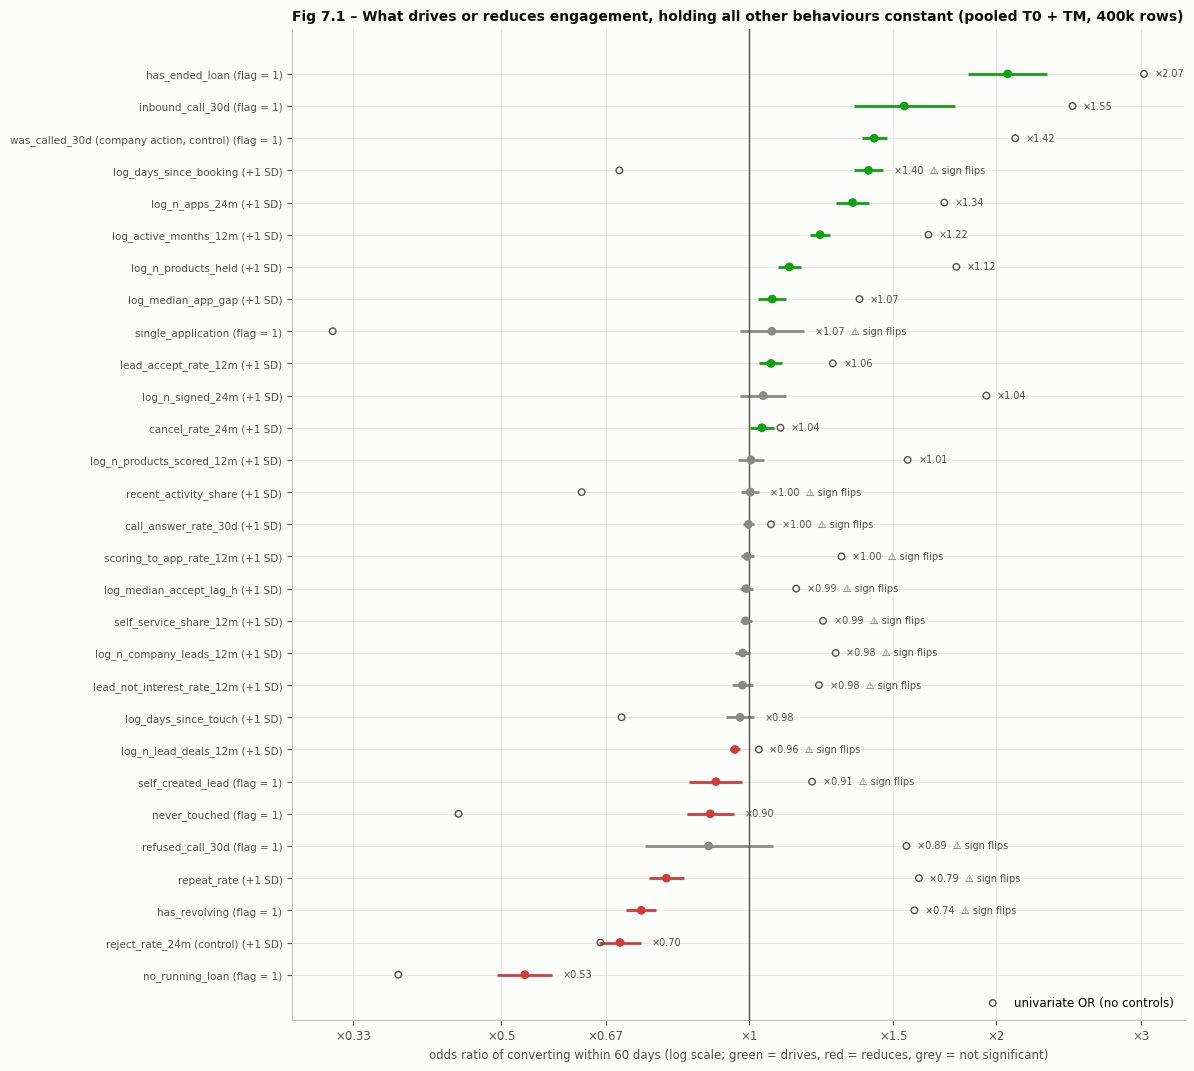

,unit,OR_multivariate,CI_low,CI_high,OR_univariate,share_or_mean,effect,sign_flips_vs_univariate
no_running_loan,flag = 1,0.5338,0.4941,0.5766,0.3744,0.3018,reduces ↓,False
reject_rate_24m (control),+1 SD,0.6969,0.6566,0.7398,0.6597,0.2596,reduces ↓,False
has_revolving,flag = 1,0.7399,0.7093,0.7718,1.5912,0.2376,reduces ↓,True
repeat_rate,+1 SD,0.7939,0.7566,0.8330,1.6117,0.5626,reduces ↓,True
refused_call_30d,flag = 1,0.8935,0.7467,1.0691,1.5564,0.0080,not significant,True
never_touched,flag = 1,0.8977,0.8401,0.9593,0.4434,0.5615,reduces ↓,False
self_created_lead,flag = 1,0.9121,0.8468,0.9824,1.1943,0.0438,reduces ↓,True
log_n_lead_deals_12m,+1 SD,0.9620,0.9477,0.9764,1.0290,0.0187,reduces ↓,True
log_days_since_touch,+1 SD,0.9759,0.9383,1.0151,0.7001,5.9379,not significant,False
lead_not_interest_rate_12m,+1 SD,0.9826,0.9552,1.0108,1.2177,0.2744,not significant,True


In [26]:
def driver_matrix(Fd):
    X = pd.DataFrame(index=Fd.index)
    X["never_touched"] = Fd["rec_touch_days"].isna().astype(float)
    X["log_days_since_touch"] = np.log1p(Fd["rec_touch_days"].fillna(Fd["rec_touch_days"].max()))
    X["log_days_since_booking"] = np.log1p(Fd["rec_booking_days"].fillna(Fd["rec_booking_days"].max()).clip(lower=0))
    # n_scoring_12m and n_channels_12m are left out: rho 0.94-0.98 with n_products_scored_12m (§3.5) -> unstable coefficients
    for v in ["active_months_12m", "n_signed_24m", "n_company_leads_12m", "n_lead_deals_12m",
              "n_products_scored_12m", "n_products_held", "n_apps_24m"]:
        X[f"log_{v}"] = np.log1p(Fd[v].clip(upper=Fd[v].quantile(0.999)))
    X["recent_activity_share"] = Fd["recent_activity_share"].fillna(0)
    X["was_called_30d (company action, control)"] = (Fd["n_sales_calls_30d"] > 0).astype(float)
    X["call_answer_rate_30d"] = Fd["call_answer_rate_30d"].fillna(0)
    X["inbound_call_30d"] = (Fd["n_inbound_calls_30d"] > 0).astype(float)
    X["refused_call_30d"] = (Fd["n_call_refuse_30d"] > 0).astype(float)
    X["self_service_share_12m"] = Fd["self_service_share_12m"].fillna(0)
    X["scoring_to_app_rate_12m"] = Fd["scoring_to_app_rate_12m"].fillna(0)
    X["lead_accept_rate_12m"] = Fd["lead_accept_rate_12m"].fillna(0)
    X["lead_not_interest_rate_12m"] = Fd["lead_not_interest_rate_12m"].fillna(0)
    X["log_median_accept_lag_h"] = np.log1p(Fd["median_accept_lag_h_12m"].fillna(0))
    X["self_created_lead"] = (Fd["n_self_leads_12m"] > 0).astype(float)
    X["has_revolving"] = Fd["has_revolving"]
    X["no_running_loan"] = (Fd["n_running"] == 0).astype(float)
    X["repeat_rate"] = Fd["repeat_rate"].fillna(0)
    X["has_ended_loan"] = Fd["repeat_rate"].notna().astype(float)
    X["cancel_rate_24m"] = Fd["cancel_rate_24m"]
    X["reject_rate_24m (control)"] = Fd["reject_rate_24m"]
    X["log_median_app_gap"] = np.log1p(Fd["median_app_gap_days"].fillna(0))
    X["single_application"] = Fd["median_app_gap_days"].isna().astype(float)
    return X

XD = pd.concat([driver_matrix(F[d]).iloc[CAL] for d in TRAIN], ignore_index=True)
yd = np.concatenate([y[d][CAL] for d in TRAIN])
binary = [c for c in XD.columns if set(np.unique(XD[c])) <= {0.0, 1.0}]
cont = [c for c in XD.columns if c not in binary]
mu, sd = XD[cont].mean(), XD[cont].std().replace(0, 1)
standardise = lambda X: X.assign(**{c: (X[c] - mu[c]) / sd[c] for c in cont})

idx = np.random.default_rng(SEED).choice(len(XD), 400_000, replace=False)
Xs, ys = standardise(XD).iloc[idx].values, yd[idx]
m = LogisticRegression(C=1e6, max_iter=3000).fit(Xs, ys)
Xa = np.c_[np.ones(len(Xs)), Xs]
p = m.predict_proba(Xs)[:, 1]
cov = np.linalg.inv((Xa * (p * (1 - p))[:, None]).T @ Xa)
se = np.sqrt(np.diag(cov))[1:]
b = m.coef_[0]
uni = [np.exp(LogisticRegression(C=1e6, max_iter=1000).fit(Xs[:, [k]], ys).coef_[0][0]) for k in range(Xs.shape[1])]
drivers = pd.DataFrame({"unit": ["flag = 1" if c in binary else "+1 SD" for c in XD.columns],
                        "OR_multivariate": np.exp(b), "CI_low": np.exp(b - 1.96 * se), "CI_high": np.exp(b + 1.96 * se),
                        "OR_univariate": uni, "share_or_mean": XD.mean().values}, index=XD.columns)
drivers["effect"] = np.where(drivers["CI_low"] > 1, "drives ↑", np.where(drivers["CI_high"] < 1, "reduces ↓", "not significant"))
drivers["sign_flips_vs_univariate"] = np.sign(np.log(drivers["OR_multivariate"])) != np.sign(np.log(drivers["OR_univariate"]))
drivers = drivers.sort_values("OR_multivariate")
drivers.to_csv(OUT / "engagement_drivers.csv")
print(f"driver model AUC out-of-time (T1 holdout): {roc_auc_score(yh1, m.predict_proba(standardise(driver_matrix(F1)).iloc[HOLD].values)[:, 1]):.3f}")

fig, ax = plt.subplots(figsize=(12, 0.33 * len(drivers) + 1.2))
yy = np.arange(len(drivers))
col = [GREEN if e.startswith("drives") else RED if e.startswith("reduces") else GREY for e in drivers["effect"]]
ax.hlines(yy, drivers["CI_low"], drivers["CI_high"], color=col, linewidth=2)
ax.scatter(drivers["OR_multivariate"], yy, color=col, s=28, zorder=3)
ax.scatter(drivers["OR_univariate"], yy, facecolors="none", edgecolors="#52514e", s=22, zorder=2, label="univariate OR (no controls)")
ax.axvline(1, color="#52514e", linewidth=1)
ax.set_xscale("log")
lo_, hi_ = min(drivers["CI_low"].min(), drivers["OR_univariate"].min()), max(drivers["CI_high"].max(), drivers["OR_univariate"].max())
ax.xaxis.set_major_locator(mtick.FixedLocator([t for t in [0.25, 0.33, 0.5, 0.67, 1, 1.5, 2, 3, 4] if lo_ / 1.2 <= t <= hi_ * 1.2]))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"×{v:g}"))
ax.xaxis.set_minor_locator(mtick.NullLocator())
ax.set_yticks(yy, [f"{i} ({u})" for i, u in zip(drivers.index, drivers["unit"])], fontsize=7.5)
for k, r in enumerate(drivers.itertuples()):
    ax.text(max(r.CI_high, r.OR_univariate) * 1.03, k, f"×{r.OR_multivariate:.2f}" + ("  ⚠ sign flips" if r.sign_flips_vs_univariate else ""),
            va="center", fontsize=7, color="#52514e")
ax.legend(frameon=False, loc="lower right")
ax.set_xlabel("odds ratio of converting within 60 days (log scale; green = drives, red = reduces, grey = not significant)")
ax.set_title("Fig 7.1 – What drives or reduces engagement, holding all other behaviours constant (pooled T0 + TM, 400k rows)", loc="left")
save(fig, "7_1_drivers")
drivers

> **💡 Insight (Fig 7.1):** mô hình đa biến trên 400 nghìn dòng (T0 + TM), AUC out-of-time 0,710.
>
> **🟢 Thúc đẩy gắn kết** (giữ các yếu tố khác cố định):
> - **Đã có khoản vay kết thúc ×2,07:** khách đã trả xong một khoản dễ quay lại vay tiếp.
> - **Tự gọi vào ×1,55.**
> - **Thời gian từ khoản vay gần nhất ×1,40** (mỗi +1 độ lệch chuẩn). Chiều này đảo ngược so với đơn biến: với cùng mức hoạt động, khoản vay trước càng xa thì khách càng có nhu cầu vay mới.
> - **Số hồ sơ ×1,34**, **số tháng hoạt động ×1,22**, **số sản phẩm đã dùng ×1,12**, khoảng cách hồ sơ ×1,07, tỉ lệ chấp nhận lead ×1,06, tỉ lệ hủy hồ sơ ×1,04.
>
> **🔴 Làm giảm gắn kết:**
> - **Không còn khoản vay đang chạy ×0,53:** tín hiệu rời bỏ mạnh nhất.
> - **Có thẻ / hạn mức quay vòng ×0,74.** Đảo chiều so với đơn biến (×1,59): khách dùng hạn mức sẵn có thay vì vay khoản mới.
> - **Tỉ lệ bị từ chối ×0,70** (biến kiểm soát); **chưa từng tương tác ×0,90**.
> - Có lead Deal hoặc tự tạo lead *giảm nhẹ* (×0,91–0,96): khách vừa chốt qua lead đã có sản phẩm.
>
> **⚪ Không có tác động riêng khi đã kiểm soát các yếu tố khác:**
> - Cả **3 biến mới**: xu hướng hoạt động, phễu cá nhân, tốc độ chấp nhận lead.
> - Tỉ lệ "không quan tâm" (đơn biến ×1,22 hoàn toàn do gây nhiễu); số lead công ty đẩy; từ chối cuộc gọi; tỉ lệ nghe máy.
>
> `was_called_30d` (×1,42) chỉ là **biến kiểm soát** cho việc telesales chọn khách.
>
> **➡️ Ý nghĩa:**
> - Gắn kết của khách tài chính tiêu dùng **xoay quanh chu kỳ khoản vay**: cao nhất khi khoản vay sắp hoặc vừa kết thúc, thấp nhất khi không còn khoản nào đang chạy.
> - Số lead hay số cuộc gọi do công ty tạo ra **không làm tăng** gắn kết.
> - Các biến mới có tín hiệu riêng lẻ, nhưng thông tin của chúng đã nằm trong nhịp vay và nộp hồ sơ. Vì vậy chúng giúp nhiều nhất ở **khách thin-file** (§4.3).

---
## 8. Điểm có gắn với kết quả kinh doanh không? (Yêu cầu 6 – phần 2)
Ngoài chuyển đổi, kiểm tra thêm các kết quả kinh doanh khác trên **nửa holdout tại T1** (khách và thời điểm chưa dùng để học):
- **Nộp hồ sơ mới** (ý định vay), **số tiền giải ngân mới** (giá trị), theo phân khúc ENG tại T1.
- **Sau ngày chốt**: điểm ở ngày chốt có dự báo được phản hồi với cuộc gọi bán hàng *sau* 04/06/2025 không (nghe máy, quan tâm/đồng ý, từ chối).
  Lưu ý: bảng CALL kéo dài đến 08/2026, vượt xa các bảng khác; cần xác nhận lại với BTC trước khi dùng làm bằng chứng chính.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

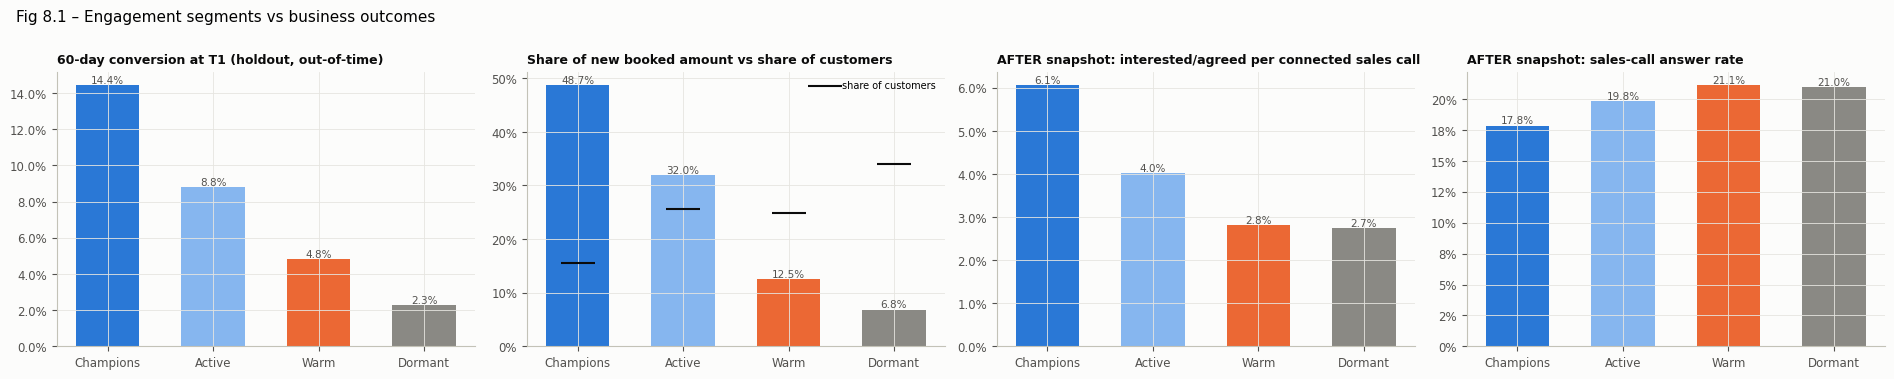

,Spearman ρ with ENG score (T1 holdout)
conversion,0.1724
new application,0.1830
new booked amount,0.1741


,customers,conversion,new_application_rate,avg_new_booked_amount_m,share_of_customers,share_of_new_booked_amount
segment,,,,,,
Champions,77768,0.1444,0.2093,3.2904,0.1555,0.4874
Active,127727,0.0879,0.1184,1.3141,0.2554,0.3197
Warm,124710,0.0481,0.0659,0.5259,0.2494,0.1249
Dormant,169861,0.0228,0.0462,0.2103,0.3397,0.0680


,customers_called,answer_rate,positive,refuse,connected,interested_or_agreed_per_connected,refuse_per_connected,made_inbound_call,termination_request
segment,,,,,,,,,
Champions,98266,0.1785,"4,589.0000","34,114.0000","75,671.0000",0.0606,0.4508,0.0929,0.0075
Active,127385,0.1982,"4,019.0000","47,677.0000","100,163.0000",0.0401,0.4760,0.0596,0.0029
Warm,78428,0.2114,"1,680.0000","28,672.0000","59,836.0000",0.0281,0.4792,0.0344,0.0012
Dormant,39991,0.2099,820.0000,"14,087.0000","29,954.0000",0.0274,0.4703,0.0159,0.0004


In [27]:
ho = pd.DataFrame({"segment": S1["ENG_segment"].values[HOLD], "score": s1, "converted": yh1,
                   "applied": Y[T1]["applied"].values[HOLD], "amount": Y[T1]["new_booked_amount"].values[HOLD]})
biz = ho.groupby("segment").agg(customers=("converted", "size"), conversion=("converted", "mean"), new_application_rate=("applied", "mean"),
                                avg_new_booked_amount_m=("amount", lambda s: s.mean() / 1e6)).reindex(SEG_ORDER)
biz["share_of_customers"] = biz["customers"] / biz["customers"].sum()
biz["share_of_new_booked_amount"] = ho.groupby("segment")["amount"].sum().reindex(SEG_ORDER) / ho["amount"].sum()
biz.to_csv(OUT / "validation_business_by_segment.csv")   # input for Challenge 3 (opportunity value)
rank_corr = pd.Series({"conversion": ho[["score", "converted"]].corr("spearman").iat[0, 1],
                       "new application": ho[["score", "applied"]].corr("spearman").iat[0, 1],
                       "new booked amount": ho[["score", "amount"]].corr("spearman").iat[0, 1]}, name="Spearman ρ with ENG score (T1 holdout)")

post = q(f"""
SELECT client, COUNT(*) FILTER (WHERE NOT is_inbound) AS out_calls,
       AVG(is_connected::INT) FILTER (WHERE NOT is_inbound) AS answer_rate,
       COUNT(*) FILTER (WHERE NOT is_inbound AND is_connected) AS connected,
       COUNT(*) FILTER (WHERE response IN ('INTERESTED', 'AGREED')) AS positive,
       COUNT(*) FILTER (WHERE response = 'REFUSE') AS refuse,
       COUNT(*) FILTER (WHERE is_inbound) AS inbound,
       COUNT(*) FILTER (WHERE response = 'TERMINATION_REQUEST') AS termination
FROM call WHERE NOT is_collection AND t_call >= TIMESTAMP '{SNAPSHOT}' GROUP BY 1""")
ps = pd.DataFrame({"client": FS["client"], "segment": SS["ENG_segment"]}).merge(post, on="client", how="left")
called = ps["out_calls"].fillna(0) > 0
post_tbl = ps[called].groupby("segment").agg(customers_called=("client", "size"), answer_rate=("answer_rate", "mean"),
                                             positive=("positive", "sum"), refuse=("refuse", "sum"), connected=("connected", "sum")).reindex(SEG_ORDER)
post_tbl["interested_or_agreed_per_connected"] = post_tbl["positive"] / post_tbl["connected"]
post_tbl["refuse_per_connected"] = post_tbl["refuse"] / post_tbl["connected"]
post_tbl = post_tbl.join(ps.groupby("segment").agg(made_inbound_call=("inbound", lambda s: (s.fillna(0) > 0).mean()),
                                                   termination_request=("termination", lambda s: (s.fillna(0) > 0).mean())))

fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for ax, (tbl, col, title, fmt) in zip(axes, [
        (biz, "conversion", "60-day conversion at T1 (holdout, out-of-time)", PCT1),
        (biz, "share_of_new_booked_amount", "Share of new booked amount vs share of customers", PCT),
        (post_tbl, "interested_or_agreed_per_connected", "AFTER snapshot: interested/agreed per connected sales call", PCT1),
        (post_tbl, "answer_rate", "AFTER snapshot: sales-call answer rate", PCT)]):
    ax.bar(SEG_ORDER, tbl[col], color=[SEG_COLOR[s] for s in SEG_ORDER], width=0.6)
    bar_labels(ax, tbl[col].values, fmt="{:.1%}")
    if col == "share_of_new_booked_amount":
        ax.scatter(SEG_ORDER, biz["share_of_customers"], color="#0b0b0b", marker="_", s=600, zorder=3, label="share of customers")
        ax.legend(frameon=False, fontsize=7)
    ax.yaxis.set_major_formatter(fmt); ax.set_title(title, loc="left", fontsize=9)
fig.suptitle("Fig 8.1 – Engagement segments vs business outcomes", x=0.01, ha="left", fontsize=11)
save(fig, "8_1_business_outcomes")
display(rank_corr.to_frame())
display(biz)
post_tbl

> **💡 Insight (Fig 8.1):** trên nửa holdout tại T1 (out-of-time), cửa sổ 60 ngày.
> - **Liên hệ với 3 kết quả kinh doanh:** Spearman ρ = 0,17 với chuyển đổi, 0,18 với nộp hồ sơ mới, 0,17 với số tiền giải ngân mới.
> - **Giá trị tập trung ở nhóm gắn kết cao:**
>   - **Champions** chiếm 16% khách nhưng mang về **49% số tiền giải ngân mới** (3,3 triệu/khách, so với 0,21 triệu/khách ở Dormant).
>   - **Champions + Active** chiếm 41% khách và tạo ra **81%** giá trị; **Dormant** chiếm 34% khách nhưng chỉ tạo ra 6,8%.
>   - Tỉ lệ nộp hồ sơ mới là 20,9% ở Champions so với 4,6% ở Dormant.
> - **Sau ngày chốt (dữ liệu chưa từng dùng):**
>   - Tỉ lệ *quan tâm hoặc đồng ý* trên mỗi cuộc gọi kết nối được là **6,1% ở Champions so với 2,7% ở Dormant** (×2,2).
>   - Tỉ lệ khách tự gọi vào là 9,3% so với 1,6%.
>   - **Tỉ lệ nghe máy gần như bằng nhau** (18–21%).
>
> **➡️ Ý nghĩa (Yêu cầu 6):** Engagement Score **gắn với kết quả kinh doanh thật**: chuyển đổi, ý định vay, giá trị giải ngân và phản hồi tích cực với telesales. Điểm *không* dự báo việc khách có nghe máy hay không.
>
> ⚠️ Dữ liệu CALL sau ngày chốt cần được BTC xác nhận trước khi dùng làm bằng chứng chính.

---
## 9. Kết luận và xuất file

In [28]:
# Customer-level explanation: the variable giving the most points, and the one with the biggest gap to its maximum
card_max = np.where(SS["scorecard"].values[:, None] == CARD_MAIN["name"],
                    CARD_MAIN["maxpts"].reindex(PS.columns).values, CARD_THIN["maxpts"].reindex(PS.columns).values)
pv = PS.values
gap = np.where(np.isnan(pv), -np.inf, card_max - np.nan_to_num(pv))
top_i, gap_i = np.nanargmax(np.where(np.isnan(pv), -np.inf, pv), axis=1), gap.argmax(axis=1)
cols = np.array(PS.columns)
bin_of = lambda idx: pd.Series([BS[cols[j]].iat[i] for i, j in enumerate(idx)], dtype=str)
explain = ("ENG " + SS["ENG_score"].round(0).astype(int).astype(str) + " (" + SS["ENG_segment"] + ", "
           + np.where(SS["scorecard"] == CARD_THIN["name"], "thin-file card", "booked card") + "). Best: " + cols[top_i] + " = " + bin_of(top_i)
           + " (+" + pd.Series(pv[np.arange(len(pv)), top_i].round(0).astype(int)).astype(str) + " pts). Biggest gap: " + cols[gap_i] + " = "
           + bin_of(gap_i) + " (" + pd.Series(gap[np.arange(len(gap)), gap_i].round(0).astype(int)).astype(str) + " pts missing)")
p_snap = p_gb[SNAPSHOT]
export = pd.concat([FS[["client"]].rename(columns={"client": "SKP_CLIENT"}), SS[["ENG_score", "ENG_segment", "scorecard"] + subcols].round(1),
                    pd.DataFrame({"ENG_score_ml": (100 * pd.Series(p_snap).rank(pct=True)).round(1)})], axis=1)
export["ENG_explanation"] = explain.values
export.to_csv(OUT / "customer_engagement_scores.csv", index=False, encoding="utf-8-sig")

assert len(export) == len(FS) and export["SKP_CLIENT"].is_unique
assert export["ENG_score"].between(0, 100).all() and export["ENG_segment"].isin(SEG_ORDER).all()
print(f"customer_engagement_scores.csv: {len(export):,} rows -> {OUT}")
print("Files:", sorted(p.name for p in OUT.glob("*.csv")))
export.sample(6, random_state=1)

customer_engagement_scores.csv: 1,000,528 rows -> D:\Thi\BI10_ROUND02_DATASET\solution\challenge2_engagement\data_root\output\challenge2
Files: ['customer_engagement_scores.csv', 'eda_converted_vs_not.csv', 'eda_variable_summary.csv', 'eng_scorecard.csv', 'engagement_drivers.csv', 'segment_profile.csv', 'validation_business_by_segment.csv', 'validation_model_comparison.csv', 'validation_oot_deciles.csv', 'variable_selection_iv.csv']


,SKP_CLIENT,ENG_score,ENG_segment,scorecard,sub_Recency,sub_Frequency,sub_Interaction behavior,sub_Lead activity,sub_Product interaction,sub_Application journey,ENG_score_ml,ENG_explanation
664327,117458754,21.0000,Dormant,Thin-file (never booked),13.1000,NaN,43.9000,36.5000,NaN,38.5000,16.1000,"ENG 21 (Dormant, thin-file card). Best: lead_n..."
791151,125460450,46.8000,Warm,Booked customers,100.0000,18.3000,NaN,58.4000,0.0000,30.2000,32.8000,"ENG 47 (Warm, booked card). Best: rec_booking_..."
254703,38130480,46.1000,Warm,Booked customers,100.0000,10.0000,NaN,18.2000,100.0000,15.4000,43.4000,"ENG 46 (Warm, booked card). Best: rec_booking_..."
173065,16072800,56.3000,Warm,Booked customers,100.0000,16.4000,NaN,47.1000,100.0000,49.6000,59.2000,"ENG 56 (Warm, booked card). Best: rec_booking_..."
645576,114642320,90.4000,Champions,Booked customers,100.0000,98.4000,NaN,58.4000,100.0000,30.2000,98.4000,"ENG 90 (Champions, booked card). Best: active_..."
66117,6053655,49.4000,Warm,Booked customers,0.0000,21.9000,NaN,18.2000,100.0000,100.0000,4.2000,"ENG 49 (Warm, booked card). Best: median_app_g..."


### File nhãn khách hàng: Financial Health (Challenge 1) + Engagement (Challenge 2)
Mỗi khách một dòng, gồm điểm và nhóm Financial Health lấy từ file kết quả Challenge 1, cùng điểm và nhóm Engagement của notebook này.
Đường dẫn file Challenge 1 đặt ở `FH_FILE` (hoặc biến môi trường `BI10_FH_FILE`); nếu không tìm thấy, file vẫn được xuất với riêng phần Engagement.

In [29]:
FH_FILE = Path(os.environ.get("BI10_FH_FILE", ROOT / "output" / "challenge1" / "customer_financial_health.parquet"))
labels = export[["SKP_CLIENT", "ENG_score", "ENG_segment"]]
if FH_FILE.exists():
    fh = pd.read_parquet(FH_FILE) if FH_FILE.suffix == ".parquet" else pd.read_csv(FH_FILE)
    fh.columns = [c.lower() for c in fh.columns]
    fh_col = "financial_health_score" if "financial_health_score" in fh.columns else "fh_score"
    fh = fh.rename(columns={"skp_client": "SKP_CLIENT", fh_col: "financial_health_score"})[["SKP_CLIENT", "financial_health_score"]]
    labels = fh.merge(labels, on="SKP_CLIENT", how="outer")
else:
    print(f"Challenge 1 file not found at {FH_FILE} -> exporting Engagement segment only")
# Add the two labels to the CUSTOMER_clean table itself (same columns + 2 new ones, same row order, same sheet split)
cust = pd.read_parquet(PQ_DIR / "CUSTOMER.parquet")
cust["SKP_CLIENT"] = pd.to_numeric(cust["SKP_CLIENT"]).astype("int64")
labeled = cust.merge(labels, on="SKP_CLIENT", how="left", validate="one_to_one")
assert len(labeled) == len(cust) and labeled["ENG_segment"].notna().all()
labeled.to_parquet(OUT / "CUSTOMER_clean_labeled.parquet", index=False)
with pd.ExcelWriter(OUT / "CUSTOMER_clean_labeled.xlsx", engine="openpyxl") as xw:   # Excel caps a sheet at 1,048,576 rows
    for k, start in enumerate(range(0, len(labeled), 1_000_000), 1):
        labeled.iloc[start:start + 1_000_000].to_excel(xw, sheet_name=f"CUSTOMER_{k}", index=False)
print(f"CUSTOMER_clean_labeled: {len(labeled):,} rows, new columns {list(labeled.columns[-2:])} -> {OUT}")
labeled.head()

ModuleNotFoundError: No module named 'openpyxl'

### Trả lời 6 yêu cầu của Challenge 2
| # | Yêu cầu | Trả lời | Bằng chứng |
|---|---|---|---|
| 1 | Yếu tố phản ánh gắn kết | 33 biến từ khung 5 nhóm (26 ứng viên) → **8 biến** cho khách đã vay (nhịp vay và nộp hồ sơ) và **7 biến** cho khách thin-file (scoring gần đây, phản hồi lead, phễu cá nhân) | IV, độ ổn định, trùng lặp, dấu hệ số (§4.1); lý do loại từng biến được ghi rõ |
| 2 | Phân tích R / F / Interaction / Lead / Product | EDA cho 33 biến: phân phối, ngoại lai, quan hệ với chuyển đổi, tương quan, độ trôi | §3. Phát hiện: Recency và xu hướng hoạt động bị mùa Tết chi phối; cuộc gọi bị thiên lệch chọn mẫu; "chấp nhận lead" là bước nghiệp vụ |
| 3 | Engagement Score | 2 scorecard WoE đơn điệu, học trên 2 mốc, cùng thang 0–100 | AUC out-of-time 0,702 (RFM 0,636; LightGBM 0,710); PSI 0,014 |
| 4 | Phân khúc | Champions 17% · Active 27% · Warm 26% · Dormant 31%, ngưỡng theo lift chuyển đổi | Chuyển đổi out-of-time 14,4% → 2,3% |
| 5 | Yếu tố tăng / giảm | ↑ có khoản vay đã kết thúc, tự gọi vào, thời gian từ khoản vay trước, số hồ sơ, số tháng hoạt động. ↓ không còn khoản vay đang chạy, có thẻ quay vòng, chưa từng tương tác | Odds ratio đa biến kèm khoảng tin cậy 95% (§7), kiểm tra chéo bằng SHAP (§5.3) |
| 6 | Kiểm chứng kinh doanh | Holdout + out-of-time + PSI + mô hình thách thức + 3 kết quả kinh doanh + phản hồi cuộc gọi sau ngày chốt | Champions + Active = 81% giá trị giải ngân mới; phản hồi tích cực ×2,2 |

### Hàm ý về gắn kết (đầu vào cho Challenge 3)
1. **Đo gắn kết bằng hành vi thật của khách** (vay, nộp hồ sơ, scoring), không bằng số lead hay tỉ lệ nghe máy: 30% khách điểm cao nhất chiếm 56% số khách chuyển đổi.
2. **Gắn kết có chu kỳ theo khoản vay:** thấp ngay sau giải ngân, tăng khi khoản vay sắp hoặc vừa kết thúc.
3. **Tín hiệu rời bỏ sớm nhất:** *không còn khoản vay đang chạy* (×0,53). 74% nhóm Dormant mang tín hiệu này.
4. **Khách thin-file cần cách đo riêng:** với họ, scoring gần đây và phản hồi với lead mới là tín hiệu gắn kết.
5. **Tính lại bảng điểm mỗi quý** và theo dõi PSI. Kiểm tra với nhóm FH để không dùng chung biến (`SHARED_WITH_FH`).
6. **Chuyển cho Challenge 3:** file `customer_engagement_scores.csv` gồm `ENG_score`, `ENG_segment`, scorecard đã dùng, điểm từng khía cạnh, `ENG_score_ml` và câu giải thích.

### Hạn chế
- Kết quả là **tương quan, không phải nhân quả**. Các hành động cần A/B test trước khi triển khai rộng.
- Cả tập khách là một cohort mùa Tết, nên kết quả có thể khác với khách mới vào ngoài mùa vụ.
- Khách thin-file vẫn khó dự báo (AUC 0,56) vì có rất ít hành vi.
- Thiếu dữ liệu về thẻ, tính năng app, SMS/email, NPS và khiếu nại. Phiên app chỉ dùng để mô tả vì rò rỉ kết quả.
- CALL chỉ có từ 01/2025, nên biến cuộc gọi dùng cửa sổ 30 ngày. Dữ liệu sau ngày chốt cần BTC xác nhận.